<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_UniversalAdversarialExamples_Gong2021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Universal adversarial examples and perturbations for quantum classifiers (Gong and Deng, 2021) step by step

This notebook re-implements, runs and checks the experiments and the two theorems of

> Weiyuan Gong and Dong-Ling Deng,
> "Universal Adversarial Examples and Perturbations for Quantum Classifiers",
> National Science Review (2021; vol. 9, issue 6, 2022), nwab130. https://doi.org/10.1093/nsr/nwab130 (arXiv:2102.07788)

**What the notebook does.** An *adversarial example* is an input that has been changed a little so that a classifier gets it wrong. This paper asks whether the attack can be made **universal**, in two senses:
(i) **one adversarial input that fools a whole set of different quantum classifiers** (Fig. 2, Theorem 1), and (ii) **one fixed perturbation that, added to many different inputs, makes one given classifier fail** on a large share of them (Fig. 3, Theorem 2).
The notebook builds the paper's **eight quantum classifiers** (two quantum convolutional networks and six multi-layer variational circuits, with exactly the parameter counts of the paper's Table S1) as Qiskit circuits and as an exact, differentiable PyTorch simulator (the two are asserted equal),
trains them on the paper's two datasets (**ground states of the 1D transverse-field Ising model** and **MNIST digits 1 versus 9, amplitude-encoded on 8 qubits**), runs the paper's attack (the quantum basic iterative method, qBIM, step 0.02) to re-draw Figs. 2a, 2b, 2c, 3a, 3b, 3c and S2, checks the stated numbers
(Table S1 accuracies, 37 % universal risk at strength 0.18, fidelities 0.96 and 0.78, the accuracy plateau of about 0.5), and tests the two theorems numerically (the bound of Theorem 1, how it scales with the number of classifiers and qubits, Hoeffding's inequality in Theorem 2, and the no-free-lunch bound of Eq. 4).
It adds controls the paper does not have: random-sign perturbations of the same strength, per-state (non-universal) perturbations, perturbations optimised on training states and tested on held-out states, and a classical network attacked in the same way; and every classical baseline is trained on exactly the same amplitude vectors.
It ends with a verdict for every claim and a critical reading. (A different paper, Anil et al. 2024, and the multi-task paper of Qiu et al. 2023 have their own notebooks in this folder; this one is about the 2021 existence results and the qBIM experiments.)

**How to run it.** Open in Colab (badge above), choose a CPU runtime, *Runtime -> Run all*. The first cell installs a pinned Qiskit (used to draw and to verify the circuits); if Colab asks to restart the session, restart and run all again.
No GPU, no quantum account, no token: MNIST comes from the public Hugging Face mirror `ylecun/mnist`. `FAST_MODE` (first lines of the configuration cell) is saved as `False`, the full budgets (about 70 minutes on an 8-thread CPU); set it to `True` for the class demo (about 12 minutes).

**What you get at the end.** The Table S1 reproduction, the re-drawn figures with controls, the numerical check of the theorems, a table with one verdict per claim, and a discussion of what the paper's evidence does and does not show.

**Stored outputs.** The outputs saved in this notebook come from **one execution with `FAST_MODE = False`** (the full budgets of the configuration cell: 20 training epochs, 3 independent trainings of the Ising classifier set, 100 test images per digit,
13 perturbation strengths for the images, 15 for Fig. 2b), run on an 8-thread laptop CPU in **68.7 minutes**. With `FAST_MODE = True` the same notebook needs about 12 minutes (8 epochs, one seed, 20 images per digit, coarser grids) and gives the same qualitative picture.
Everything below the code cells that is not an output (the introduction, the tables of choices and the sections *Reading the paper critically* and *Exercises*) was written around the numbers of that run.

**The one-sentence outcome.** The classifiers, data, theory check and training are reproduced; the paper's **headline attack numbers are not** (the paper's local-rotation qBIM does not reach 37 % universal risk at strength 0.18, it stays at about 5 %, and fools only 2 of 200 digits), but **universal adversarial examples and universal perturbations do exist** for these classifiers
once the perturbation is allowed to be an arbitrary state in the ball (controls of this notebook: all but one of 200 digits are fooled at strength at most 0.7, the median example has fidelity 0.80, and a single unitary of operator distance 0.1 sends every test state to one class); the no-free-lunch bound of Theorem 2 (Eq. 4) is contradicted by a direct experiment.

## The paper in one page

**Problem.** Quantum classifiers can be fooled by small, carefully crafted changes of their input (adversarial examples), just as neural networks can. Two open questions: are there **universal adversarial examples** that fool *many different* quantum classifiers at once,
and **universal adversarial perturbations** that, added to *many different inputs*, make a given classifier fail?

**Setting.** A quantum classifier maps an input state `|psi>` through a parametrised circuit and reads the label from the measurement probabilities of an output qubit (label 1 if `P(1) >= P(0)`). Classical data are encoded as amplitudes.
Adversarial perturbations are **local unitaries near the identity** applied to the input state; the attack is the quantum basic iterative method qBIM (step 0.02) maximising the cross-entropy loss; "white-box" means the attacker knows the classifiers.

**Theory.**
*Theorem 1*: for `k` classifiers on `n` qubits, a perturbation of Hilbert-Schmidt size `eps` with `eps^2 >= (4/d) ln[2k / (mu_min (1 - R0))]` (`d = 2^n`) guarantees a universal adversarial risk of at least `R0`; the needed strength grows like `ln k` and shrinks like `2^(-n)`.
*Theorem 2*: for a unitary perturbation and `n` Haar-random inputs the empirical error rate is within `sqrt(ln(2/delta) / 2n)` of the true risk with probability `1 - delta` (Hoeffding), and the average risk over ground truths and training sets is bounded below by `1 - d'(N^2 + d + 1)/(d(d+1))`
(quantum no-free-lunch), which tends to 1 as `d` grows.

**Experiments.** Eight classifiers (2 QCNNs with 44 and 92 parameters; depth-5 to depth-10 variational circuits with 144 to 279 parameters) on (a) **MNIST digits 1 vs 9** reduced to 16 x 16 and amplitude-encoded on 8 qubits, and (b) **ground states of the transverse-field Ising model**
(300 training states, 100 test states, Jx from 0 to 2). Table S1 lists the Ising accuracies (0.917 to 0.955). Fig. 2a: universal adversarial digits that fool all eight classifiers (fidelity about 96 %). Fig. 2b: universal adversarial risk against the perturbation strength for three subsets of
three classifiers, white-box (37 % at strength 0.18, roughly linear in the strength). Fig. 2c: the hybrid white-box / black-box attack (smaller, linear). Fig. 3a: one perturbation added to different digits fools the QCNN (fidelity about 78 %). Fig. 3b, c: accuracy and loss versus
strength for one perturbation added to all test states (accuracy plateau of about 0.5, loss keeps rising). All simulations were done in Julia (Yao.jl).

### What follows the paper and what had to be chosen

The paper's supplement gives the structure of the classifiers only as a sketch (Fig. S1), the qBIM details only by reference, and does not define the "perturbation strength" on its axes. Everything unspecified is marked `# CHOICE:` in the code.
Figs. 2 and 3 are plots without printed values; the printed numbers are Table S1, the 37 % at 0.18, the fidelities 96 % and 78 %, the plateau of about 0.5, and the five states misclassified by all classifiers.

| Item | Paper | This notebook |
|---|---|---|
| Quantum data | ground states of H = -sum Z_i Z_{i+1} - Jx sum X_i, Jx from 0 to 2 (chain length not stated) | **L = 8 spins** (8 qubits, matching 16 x 16 images), open chain, `Jx ~ U(0, 2)`, exact ground states; label = phase (Jx < 1 / Jx >= 1); 300 / 100 / 100 train / validation / test |
| Images | MNIST 1 vs 9, 16 x 16, amplitude encoding | `ylecun/mnist` mirror, bilinear 28 -> 16, unit-norm amplitudes; 800 / 200 train / val, 200 test (FAST; 1600 / 400 / 500 in the full run) |
| Variational classifiers 3-8 | depth 5 ... 10, "Z X Ent Z X" layers, 144 ... 279 parameters, input state (x) \|1> | 8 data qubits + 1 label qubit in \|1>; layer = Rz Rx Rz on every qubit + CNOT chain; final Ry layer; 27 p + 9 parameters (matches Table S1) |
| QCNNs 1, 2 | Cong et al. structure C1 C2 P1 C3 C4 P2 C5 C6 FC, 44 and 92 parameters | same layer pattern; translation-invariant 2-qubit units with 6 / 12 angles, pooling by controlled rotations, FC block of 4 / 12 angles: exactly 44 and 92 parameters |
| Training | Adam, cross-entropy, 20 epochs, iterations per epoch from Fig. S2 | same; batch 10 (QCNN) / 60 (variational) on Ising, 32 on MNIST (inferred / chosen); lr 0.05 (QCNN) and 0.1 (variational) picked on validation; angles ~ N(0, 0.5^2); FAST mode uses 8 epochs |
| Attack | qBIM, alpha = 0.02, local unitaries near the identity, white-box | 24 angles (Rz Rx Rz per data qubit), sign-gradient steps of 0.02, projected back to the strength ball after every step, `ceil(1.25 eps / alpha) + 2` iterations |
| Perturbation strength | "eps" (not defined for the simulations) | **normalised Hilbert-Schmidt distance**: sqrt(1 - F) between clean and attacked state, at most eps for every input (examples); operator distance sqrt(1 - \|tr U / d\|^2) of the shared unitary at most eps (universal perturbations); chosen from the fidelities 0.96 and 0.78 quoted in the paper |
| Universal adversarial risk | share of test samples fooling all classifiers of the subset | same, over all 100 test states (clean errors included) |
| Fig. 2c black-box | attacker knows one classifier, others unknown | perturbation crafted against one classifier of (1, 3, 6), evaluated on all three |
| Universal perturbation | "additional variational layer", loss maximised on a set of samples | the same 24-angle layer, one shared set of angles, mean loss over the 100 test states (paper protocol); a held-out variant is added |
| MNIST attacks | two example images | 20 test images per digit (FAST) or 100 (full run); qBIM with a growing strength bound, plus an unrestricted-state control attack on a grid of strengths |
| Seeds | not stated | `SEED = 42`; extra seeds (full run: 3) change the initial angles |
| Hardware / software | Julia, Yao.jl, CuYao.jl on a cluster / GPU | CPU only; PyTorch statevector simulator, checked against Qiskit |

**Added in this notebook (not in the paper), all marked as controls in the code:**

| Item | What was added and why |
|---|---|
| Strength definition | the paper's x axis is not defined; we use the Hilbert-Schmidt distance (examples) and the operator distance (shared unitary). A first pilot with an angle bound gave fidelity 0.38 at 0.18 and was dropped before any figure was drawn |
| Random direction | a random sign pattern of the angles, scaled to exactly the same strength: shows what the strength alone achieves |
| Unrestricted state attack | any perturbed state in the ball (`state_attack`, 20 gradient steps, capped cross entropy): a *lower bound* on what any perturbation of that strength can do; used for the MNIST examples, Fig. 2b (subset 1, 3, 6) and the scaling experiments |
| Unrestricted universal unitary | any unitary `exp(iA)` of the given operator distance (80 Adam steps), optimised on the test states (paper protocol) and on 100 training states (held-out) |
| Held-out and per-state versions | the universal qBIM perturbation optimised on training states, and one qBIM perturbation per state |
| Classical network | a 256-64-2 MLP on the amplitudes, attacked white-box and by transfer |
| Classical baselines | logistic regression, RBF SVM, random forest and the MLP on exactly the same amplitude vectors |
| Scaling experiments | needed strength versus the number of classifiers (nested sets, k = 1, 2, 4, 8) and versus the number of qubits (chains of 4 to 8 spins) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib, pyarrow and PyTorch.
# Qiskit is added: it is used to DRAW the executed circuits and to VERIFY our fast simulator (the circuits are also run on Qiskit's statevector simulator).
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("qiskit", "pylatexenc", "huggingface_hub", "pyarrow") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    %pip install -q "qiskit==2.5.2" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit, pylatexenc, huggingface_hub and pyarrow already present; skipping pip install.")

qiskit, pylatexenc, huggingface_hub and pyarrow already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE = False          # True: class demo (a few minutes on a laptop CPU).  False: the full budgets documented below (about an hour on a laptop CPU).

SEED = 42                 # CHOICE: the paper gives no seed
IBM_TOKEN = ""            # unused: every circuit is simulated exactly, no quantum hardware is needed
DATA_DIR = "data"         # the MNIST parquet files are downloaded here, converted to a small .npz and the large files deleted

# ---- data ----
N_DATA = 8                                         # paper: 16 x 16 = 256 amplitudes -> 8 data qubits; Ising chain of L = 8 spins
ISING_N = dict(train=300, val=100, test=100)       # paper: 300 training states (Table S1) and a test set of 100 ground states; val is ours (for Fig. S2-style curves)
DIGITS = (1, 9)                                    # paper: digits "1 and 9"; label 0 = digit 1, label 1 = digit 9
MNIST_PER_CLASS = dict(train=400, val=100, test=100) if FAST_MODE else dict(train=800, val=200, test=250)   # CHOICE: the paper does not give subset sizes

# ---- classifier training (paper, Sec. S-III: Adam; 20 epochs; iterations per epoch in the Fig. S2 caption) ----
EPOCHS = 8 if FAST_MODE else 20                    # paper: 20 epochs
ISING_ITS = dict(qcnn=30, vc=5)                    # paper Fig. S2a,b: 30 iterations/epoch (QCNN 2), 5 (classifier 8)
ISING_BS = dict(qcnn=10, vc=60)                    # CHOICE (inferred): 300 training states / (iterations per epoch)
MNIST_ITS = dict(qcnn=25, vc=10) if FAST_MODE else dict(qcnn=50, vc=10)   # paper Fig. S2c,d: 50 (QCNN 2) and 10 iterations/epoch
MNIST_BS = 32                                      # CHOICE: not given
LR = dict(qcnn=0.05, vc=0.1)                       # CHOICE: Adam learning rates, picked on the validation split of a pilot run (single seed)
INIT_STD = 0.5                                     # CHOICE: normal initialisation of all rotation angles (paper: "random values")
N_SEEDS = 1 if FAST_MODE else 3                    # independent trainings of the whole Ising classifier set (mean +- std in Table S1 and Fig. 2b); extra seeds change the init only

# ---- attacks (qBIM with step size alpha = 0.02 as in the paper) ----
ALPHA = 0.02
ITER_FACTOR, ITER_EXTRA = 1.25, 2                  # CHOICE: qBIM runs ceil(1.25 eps / alpha) + 2 iterations (Kurakin et al.: about 1.25 eps / alpha steps)
EPS_FIG2B = [0.0, 0.1, 0.18, 0.3, 0.45] if FAST_MODE else [round(0.02 * i, 2) for i in range(0, 11)] + [0.3, 0.4, 0.5, 0.6]     # paper Fig. 2b: 0 ... 0.2 (we go beyond it, see the text)
EPS_FIG2C = [0.0, 0.1, 0.2, 0.3, 0.45] if FAST_MODE else [round(0.03 * i, 2) for i in range(0, 11)] + [0.4, 0.5]          # paper Fig. 2c: 0 ... 0.3 (and beyond)
EPS_FIG3 = [0.0, 0.1, 0.2, 0.4, 0.8] if FAST_MODE else [round(0.1 * i, 1) for i in range(0, 9)]                         # paper Fig. 3b,c: 0 ... 0.8
MNIST_ATTACK_PER_CLASS = 20 if FAST_MODE else 100  # CHOICE: test images per digit used for the MNIST attacks (universal examples, Fig. 2a)
MNIST_EPS_MAX = 0.40                               # CHOICE: largest perturbation strength tried on images with qBIM
MNIST_STATE_GRID = [0.2, 0.3, 0.4, 0.5, 0.6] if FAST_MODE else [round(0.05 * i, 2) for i in range(2, 15)]   # strengths tried by the unrestricted control attack on images
STATE_STEPS = 20                                   # CHOICE: gradient steps of the unrestricted control attack
UNI_STEPS, UNI_LR = (40, 0.05) if FAST_MODE else (80, 0.05)   # CHOICE: Adam steps / learning rate of the unrestricted universal-unitary control
N_RANDOM_DRAWS = 5 if FAST_MODE else 20            # random-sign control perturbations averaged per setting

# ---- numerical checks of the two theorems ----
HOEFFDING_POOL = 1500 if FAST_MODE else 4000       # fresh Ising ground states used to estimate the true error mu(E)
HOEFFDING_DRAWS = 400 if FAST_MODE else 2000       # random test sets of n = 100 states per classifier
NFL_QUBITS = [3, 4] if FAST_MODE else [3, 4, 5, 6]  # data qubits for the Haar-random ground-truth experiment (Eq. 4)
NFL_TRAIN_SIZES = [2, 8]                           # N training pairs
NFL_DRAWS = 6 if FAST_MODE else 20                 # random ground truths per setting
K_LIST = [1, 3] if FAST_MODE else [1, 2, 4, 8]    # number of classifiers (nested sets) in the "perturbation needed versus k" experiment
EPS_SCAL = [0.2, 0.3, 0.4, 0.5] if FAST_MODE else [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]   # perturbation strengths tried there (unrestricted attack)
SCALING_L = [4, 6] if FAST_MODE else [4, 5, 6, 7]  # extra chain lengths for the "perturbation needed versus number of qubits" experiment (L = 8 is the main data)

In [3]:
import os, io, time, math, shutil, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch, torch.nn as nn
import sklearn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from PIL import Image
import pyarrow.parquet as pq
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import StatePreparation
from qiskit.quantum_info import Statevector
from huggingface_hub import hf_hub_download

# Hugging Face token: MNIST is public, so None works. A gated dataset would need your own token in Colab Secrets (Settings > Secrets > HF_TOKEN).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.manual_seed(SEED); np.random.seed(SEED)       # seeds everywhere (every random draw below also uses an explicit generator seeded from SEED)
torch.set_num_threads(1)                            # one thread: fastest for these tiny matrices and kind to a shared machine
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": False})
T_START = time.time()
TOL = 0.02              # tolerance used for every numeric verdict: 2 percentage points / 0.02

print("torch", torch.__version__, "| qiskit", qiskit.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| epochs", EPOCHS, "| seeds", N_SEEDS, "| MNIST images per class", MNIST_PER_CLASS)

torch 2.14.1+cpu | qiskit 2.5.2 | numpy 2.5.4 | scikit-learn 1.9.1
FAST_MODE = False | epochs 20 | seeds 3 | MNIST images per class {'train': 800, 'val': 200, 'test': 250}


## 1. The eight quantum classifiers and an exact simulator

The paper simulates its classifiers with the Julia package Yao.jl and differentiates them by automatic differentiation (and the parameter-shift rule). Here every classifier is a **gate list**
(`QCircuit.ops`) that is interpreted twice: by a small exact state-vector simulator written in PyTorch (fast, differentiable, batched over many inputs) and by a Qiskit circuit builder
(the circuit that is drawn in the circuit section further below). A test at the end of this section, and a second one with the trained parameters later, assert that both give the same
measurement probabilities to 1e-10, so the numbers in the notebook are those of the drawn circuits.

**Architectures** (paper, Supplement Sec. S-III and Fig. S1):

* **Classifiers 3 to 8**: "multi-layer quantum variational classifiers" of depth p = 5, 6, ..., 10 on the 8 data qubits plus **one label qubit** that starts in |1> (the paper writes |psi_in> (x) |1>^(x m) with m = 1).
  Each layer is an Euler rotation on every qubit followed by a chain of CNOTs between neighbouring qubits. Table S1 gives the parameter counts 144, 171, 198, 225, 252, 279 = 27 p + 9: 27 = 3 angles x 9 qubits per layer
  and 9 more angles, which we place in a final layer of R_y rotations (the paper's text lists "Z X Ent Z X", i.e. four angles per qubit, which would give 36 p; the table decides).
* **Classifiers 1 and 2**: quantum convolutional neural networks (Cong, Choi and Lukin 2019) with six convolution layers C1..C6, two pooling layers P1, P2 and a fully connected block FC, with **44** and **92** parameters.
  The paper does not list the gates; we choose translation-invariant convolution units with 6 (classifier 1) and 12 (classifier 2) angles, pooling by controlled rotations, and an FC block, so that the counts are exactly 44 and 92.
* **Read-out**: the probability of the output qubit being |1> (label 1) versus |0> (label 0); the predicted label is 1 if P(1) >= P(0) (paper, Sec. S-III).
* **Input**: a normalised amplitude vector x (256 numbers) is loaded as the state of the 8 data qubits (amplitude encoding, as in the paper).
* **Loss**: cross entropy of the two output probabilities (paper, Eq. S18).

In [4]:
# ---------------------------------------------------------------------------------------------------------------------------------------
# Exact state-vector simulator (PyTorch, complex128). Qubit q is bit q of the basis index (Qiskit's little-endian convention).
# ---------------------------------------------------------------------------------------------------------------------------------------
CDT = torch.complex128
_c = lambda x: x.to(CDT)

def rot_mat(kind, th):
    # RX / RY / RZ (Qiskit conventions) for a real tensor of angles th (...,) -> complex matrices (..., 2, 2)
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    if kind == "rx":
        r0 = torch.stack([_c(c), -1j * _c(s)], -1); r1 = torch.stack([-1j * _c(s), _c(c)], -1)
    elif kind == "ry":
        r0 = torch.stack([_c(c), -_c(s)], -1); r1 = torch.stack([_c(s), _c(c)], -1)
    else:  # rz
        z = torch.zeros_like(_c(c))
        r0 = torch.stack([torch.polar(torch.ones_like(th), -th / 2).to(CDT), z], -1)
        r1 = torch.stack([z, torch.polar(torch.ones_like(th), th / 2).to(CDT)], -1)
    return torch.stack([r0, r1], -2)

def fuse(kinds, ang):
    # product of single-qubit rotations applied in the order given; ang (..., len(kinds)) -> (..., 2, 2)
    M = None
    for j, k in enumerate(kinds):
        G = rot_mat(k, ang[..., j]); M = G if M is None else G @ M
    return M

def kron_chain(Ms):
    # Ms (..., k, 2, 2), index 0 = least significant qubit -> (..., 2^k, 2^k)
    k = Ms.shape[-3]; K = Ms[..., k - 1, :, :]
    for j in range(k - 2, -1, -1):
        A, Bm = K, Ms[..., j, :, :]; da = A.shape[-1]
        K = (A[..., :, None, :, None] * Bm[..., None, :, None, :]).reshape(*A.shape[:-2], da * 2, da * 2)
    return K

def apply_chunk(psi, K, q_lo, k, N):
    # apply a 2^k x 2^k matrix (shared, or one per sample) to the k consecutive qubits q_lo .. q_lo+k-1 of an N-qubit batch psi (B, 2^N)
    B = psi.shape[0]; v = psi.reshape(B, 2 ** (N - q_lo - k), 2 ** k, 2 ** q_lo)
    out = torch.matmul(K, v) if K.dim() == 2 else torch.matmul(K[:, None], v)
    return out.reshape(B, -1)

def apply_2q(psi, U4, q1, q2, N):
    # 4x4 gate U4 (basis |q1 q2>, q1 = most significant bit) on qubits (q1, q2)
    B = psi.shape[0]; hi, lo = max(q1, q2), min(q1, q2)
    v = psi.reshape(B, 2 ** (N - hi - 1), 2, 2 ** (hi - lo - 1), 2, 2 ** lo); U = U4.reshape(2, 2, 2, 2)
    out = torch.einsum("pqij,baicjd->bapcqd", U, v) if q1 == hi else torch.einsum("pqij,bajcid->baqcpd", U, v)
    return out.reshape(B, -1)

cx_index = lambda N, c, t: np.where((np.arange(2 ** N) >> c) & 1, np.arange(2 ** N) ^ (1 << t), np.arange(2 ** N))
ctrl_mat = lambda R: torch.block_diag(torch.eye(2, dtype=CDT), R)       # controlled-R, control = first qubit
MAXW = 5                                                                 # widest block of neighbouring qubits merged into one matrix (speed only)

class QCircuit:
    # A classifier = gate list `ops`:  ("1q", qubit, (rotation kinds in time order), (parameter indices)) | ("cx", control, target) | ("cr", kind, control, target, parameter).
    # The simulator merges runs of single-qubit gates and runs of CNOTs (pure speed-ups); the Qiskit builder below emits the gates one by one.
    def __init__(self, name, n_total, n_data, ops, n_params, q_out):
        self.name, self.N, self.n_data, self.ops, self.n_params, self.q_out = name, n_total, n_data, ops, n_params, q_out
        self.kinds = sorted({op[2] for op in ops if op[0] == "1q"})
        self.kidx = {k: torch.as_tensor([op[3] for op in ops if op[0] == "1q" and op[2] == k], dtype=torch.long) for k in self.kinds}
        row, cnt = {}, 0
        for k in self.kinds:
            for i, op in enumerate(ops):
                if op[0] == "1q" and op[2] == k:
                    row[i] = cnt; cnt += 1
        self.stages, sig_rows, i = [], {}, 0
        while i < len(ops):
            op = ops[i]
            if op[0] == "1q":
                run, used = [], set()
                while i < len(ops) and ops[i][0] == "1q" and ops[i][1] not in used:
                    used.add(ops[i][1]); run.append(i); i += 1
                qs = sorted(used); ranges, cur = [], [qs[0]]
                for q in qs[1:]:
                    if q == cur[-1] + 1 and len(cur) < MAXW: cur.append(q)
                    else: ranges.append(cur); cur = [q]
                ranges.append(cur)
                by_q = {ops[j][1]: row[j] for j in run}; cids = []
                for rg in ranges:
                    sig = (rg[0], len(rg)); sig_rows.setdefault(sig, []).append([by_q[q] for q in rg]); cids.append((sig, len(sig_rows[sig]) - 1))
                self.stages.append(("1q", cids))
            elif op[0] == "cx":
                perm = None
                while i < len(ops) and ops[i][0] == "cx":
                    f = cx_index(n_total, ops[i][1], ops[i][2]); perm = f if perm is None else perm[f]; i += 1
                self.stages.append(("cx", torch.as_tensor(perm, dtype=torch.long)))
            else:
                self.stages.append(("cr", op[1], op[2], op[3], op[4])); i += 1
        self.sig_rows = {s: torch.as_tensor(r, dtype=torch.long) for s, r in sig_rows.items()}

    def embed(self, psi):
        # the label qubit(s) beyond the data qubits start in |1>; they are the most significant qubits
        extra = self.N - self.n_data
        if extra == 0: return psi
        return torch.cat([torch.zeros(psi.shape[0], (2 ** extra - 1) * 2 ** self.n_data, dtype=psi.dtype), psi], 1)

    def run(self, state, theta):
        allm = torch.cat([fuse(k, theta[self.kidx[k]]) for k in self.kinds], 0)
        K = {s: kron_chain(allm[r]) for s, r in self.sig_rows.items()}
        for st in self.stages:
            if st[0] == "1q":
                for sig, r in st[1]: state = apply_chunk(state, K[sig][r], sig[0], sig[1], self.N)
            elif st[0] == "cx":
                state = state[:, st[1]]
            else:
                state = apply_2q(state, ctrl_mat(rot_mat(st[1], theta[st[4]])), st[2], st[3], self.N)
        return state

    def out_probs(self, state):
        B = state.shape[0]; q = self.q_out
        return (state.reshape(B, 2 ** (self.N - q - 1), 2, 2 ** q).abs() ** 2).sum((1, 3))      # (B, 2): P(label 0), P(label 1)

    def probs(self, psi, theta, delta=None):
        # psi (B, 2^n_data) complex amplitudes; optional perturbation layer delta (3 n_data,) or (B, 3 n_data) applied before the classifier
        if delta is not None: psi = apply_local_rot(psi, delta, self.n_data)
        return self.out_probs(self.run(self.embed(psi), theta))

def apply_local_rot(psi, delta, n):
    # the attack's unitary: on every data qubit Rz(d0), then Rx(d1), then Rz(d2); a product of single-qubit unitaries near the identity (paper Sec. S-IV)
    mats = fuse(("rz", "rx", "rz"), delta.reshape(*delta.shape[:-1], n, 3)); q = 0
    while q < n:
        k = min(MAXW, n - q); psi = apply_chunk(psi, kron_chain(mats[..., q:q + k, :, :]), q, k, n); q += k
    return psi

# ------------------------------------------------------------------ the eight architectures
def build_vc(depth, n_data=N_DATA):
    # multi-layer variational classifier: p x [Rz Rx Rz on every qubit, CNOT chain 0->1->...->label qubit], then a final Ry layer (27 p + 9 angles for 9 qubits)
    N = n_data + 1; ops = []; p = 0
    for _ in range(depth):
        for q in range(N):
            ops.append(("1q", q, ("rz", "rx", "rz"), (p, p + 1, p + 2))); p += 3
        for q in range(N - 1): ops.append(("cx", q, q + 1))
    for q in range(N): ops.append(("1q", q, ("ry",), (p,))); p += 1
    return QCircuit(f"VC-p{depth}", N, n_data, ops, p, N - 1)

def _unit_stages(pairs, pr, u):
    # translation-invariant two-qubit unit with u = 6 or 12 angles, emitted layer by layer for all pairs (they act on disjoint qubits)
    if u == 6:
        return [[("1q", a, ("rx", "rz"), (pr[0], pr[2])) for a, b in pairs] + [("1q", b, ("rx", "rz"), (pr[1], pr[3])) for a, b in pairs],
                [("cx", a, b) for a, b in pairs],
                [("1q", a, ("ry",), (pr[4],)) for a, b in pairs] + [("1q", b, ("rz",), (pr[5],)) for a, b in pairs]]
    return [[("1q", a, ("rx", "rz"), (pr[0], pr[1])) for a, b in pairs] + [("1q", b, ("rx", "rz"), (pr[2], pr[3])) for a, b in pairs],
            [("cx", a, b) for a, b in pairs],
            [("1q", a, ("ry", "rz"), (pr[4], pr[5])) for a, b in pairs] + [("1q", b, ("ry", "rz"), (pr[6], pr[7])) for a, b in pairs],
            [("cx", b, a) for a, b in pairs],
            [("1q", a, ("rx", "rz"), (pr[8], pr[9])) for a, b in pairs] + [("1q", b, ("rx", "rz"), (pr[10], pr[11])) for a, b in pairs]]

def build_qcnn(variant, n_data=N_DATA):
    # QCNN with C1 C2 P1 C3 C4 P2 C5 C6 FC. variant 1: unit 6 angles, pooling 2, FC 4 -> 6*6 + 2*2 + 4 = 44.  variant 2: unit 12, pooling 4, FC 12 -> 6*12 + 2*4 + 12 = 92.
    u, v, f = (6, 2, 4) if variant == 1 else (12, 4, 12)
    ops, nxt = [], 0
    def take(k):
        nonlocal nxt
        r = tuple(range(nxt, nxt + k)); nxt += k; return r
    def conv(act):
        pr = take(u)
        for s in (0, 1):                                   # even pairs (0,1)(2,3).. then odd pairs (1,2)(3,4).. of the active qubits
            for stage in _unit_stages([(act[i], act[i + 1]) for i in range(s, len(act) - 1, 2)], pr, u): ops.extend(stage)
    def pool(act):
        pr = take(v); pairs = [(act[i], act[i + 1]) for i in range(0, len(act), 2)]      # controlled rotations from the discarded qubit onto the kept one
        ops.extend(("cr", "rz", d_, k_, pr[0]) for d_, k_ in pairs); ops.extend(("cr", "rx", d_, k_, pr[1]) for d_, k_ in pairs)
        if v == 4:
            ops.extend(("cr", "ry", d_, k_, pr[2]) for d_, k_ in pairs); ops.extend(("1q", k_, ("rz",), (pr[3],)) for d_, k_ in pairs)
        return [k_ for d_, k_ in pairs]
    act = list(range(n_data))
    for _ in range(2): conv(act)
    act = pool(act)
    for _ in range(2): conv(act)
    act = pool(act)
    for _ in range(2): conv(act)
    pr = take(f)
    if variant == 1:
        a, b = act
        ops += [("1q", a, ("rx",), (pr[0],)), ("1q", b, ("rx",), (pr[1],)), ("cx", a, b), ("1q", b, ("rz", "ry"), (pr[2], pr[3]))]
    else:
        for stage in _unit_stages([(act[0], act[1])], pr, 12): ops.extend(stage)
    return QCircuit(f"QCNN-{variant}", n_data, n_data, ops, nxt, act[-1])

ARCHS = [build_qcnn(1), build_qcnn(2)] + [build_vc(p) for p in range(5, 11)]          # classifiers 1 ... 8 of the paper
PAPER_PARAMS = [44, 92, 144, 171, 198, 225, 252, 279]                                    # paper, Table S1
assert [a.n_params for a in ARCHS] == PAPER_PARAMS
print("parameter counts of classifiers 1-8:", [a.n_params for a in ARCHS], "= Table S1 of the paper")

parameter counts of classifiers 1-8: [44, 92, 144, 171, 198, 225, 252, 279] = Table S1 of the paper


In [5]:
# ---------------------------------------------------------------------------------------------------------------------------------------
# Qiskit builder: the SAME gate list -> a real Qiskit circuit (this is what is drawn later), and the equivalence test
# ---------------------------------------------------------------------------------------------------------------------------------------
def to_qiskit(circ, theta=None, psi=None, delta=None, label="AmpEnc(x)", measure=False):
    # Amplitude loading of the data qubits (Qiskit StatePreparation), X on the label qubit (start in |1>), optional perturbation layer, then the classifier gates.
    n = circ.n_data; qc = QuantumCircuit(circ.N, 1 if measure else 0)                       # measure=True adds the read-out of the output qubit (for drawing only)
    th = ParameterVector("t", circ.n_params) if theta is None else theta                     # symbolic angles for drawing, numbers for simulation
    qc.append(StatePreparation(np.eye(2 ** n)[0] if psi is None else psi, label=label), list(range(n)))
    for q in range(n, circ.N): qc.x(q)
    if delta is not None:
        d = delta if isinstance(delta, ParameterVector) else [float(x) for x in delta]
        for q in range(n):
            qc.rz(d[3 * q], q); qc.rx(d[3 * q + 1], q); qc.rz(d[3 * q + 2], q)
    for op in circ.ops:
        if op[0] == "1q":
            for k, p in zip(op[2], op[3]): getattr(qc, k)(th[p], op[1])
        elif op[0] == "cx": qc.cx(op[1], op[2])
        else: getattr(qc, "c" + op[1])(th[op[4]], op[2], op[3])
    if measure: qc.measure(circ.q_out, 0)
    return qc

def check_equivalence(circ, theta, psi, delta=None, tol=1e-8):
    # compare the torch simulator with Qiskit's Statevector on each input; returns the largest absolute difference of the output-qubit probabilities
    P = circ.probs(torch.as_tensor(psi, dtype=CDT), torch.as_tensor(theta, dtype=torch.float64),
                   None if delta is None else torch.as_tensor(delta, dtype=torch.float64)).detach().numpy()
    worst = 0.0
    for i in range(len(psi)):
        qc = to_qiskit(circ, np.asarray(theta, dtype=float), psi[i], None if delta is None else np.asarray(delta, dtype=float))
        pr = Statevector(qc).probabilities([circ.q_out]); worst = max(worst, float(np.abs(pr - P[i]).max()))
    assert worst < tol, (circ.name, worst)
    return worst

# self-test with random angles and random COMPLEX input states (so that both the classifier gates and the perturbation layer are exercised)
_g = np.random.default_rng(SEED)
_psi = _g.normal(size=(2, 256)) + 1j * _g.normal(size=(2, 256)); _psi /= np.linalg.norm(_psi, axis=1, keepdims=True)
for a in ARCHS:
    w = check_equivalence(a, _g.normal(size=a.n_params), _psi, delta=_g.normal(size=3 * N_DATA) * 0.3)
    print(f"{a.name:8s} torch simulator == Qiskit statevector, largest difference {w:.1e}")

QCNN-1   torch simulator == Qiskit statevector, largest difference 4.9e-15


QCNN-2   torch simulator == Qiskit statevector, largest difference 4.1e-15


VC-p5    torch simulator == Qiskit statevector, largest difference 3.2e-15


VC-p6    torch simulator == Qiskit statevector, largest difference 2.4e-15


VC-p7    torch simulator == Qiskit statevector, largest difference 4.6e-15


VC-p8    torch simulator == Qiskit statevector, largest difference 2.1e-15


VC-p9    torch simulator == Qiskit statevector, largest difference 2.2e-15


VC-p10   torch simulator == Qiskit statevector, largest difference 2.8e-15


## 2. Data

Two datasets, exactly as in the paper.

**Quantum data: the ground states of the 1D transverse-field Ising model**, `H = - sum_{i=1}^{L-1} Z_i Z_{i+1} - Jx sum_{i=1}^{L} X_i` (open chain, paper Eq. 2) for **L = 8 spins**
(8 qubits, the same register size as the 16 x 16 images; the paper does not state L, this is the value consistent with its 8-qubit classifiers). The paper samples `Jx` between 0 and 2; we draw
`Jx ~ Uniform(0, 2)` and compute the **exact** ground state by diagonalisation (the Hamiltonian commutes with the global spin flip, and the ground state is flip-even, so the matrix is diagonalised in the even sector only).
The label is the phase: `0` for `Jx < 1` (strong ZZ coupling, "ferromagnetic") and `1` for `Jx >= 1` ("paramagnetic"); the transition of the infinite chain is at `Jx = 1`.
(The paper's sentence assigns the two phases the other way round; for this Hamiltonian the large-field phase is the paramagnet. The task is the same either way.)
A 300 / 100 / 100 split is used for training / validation / test: the paper reports Table S1 on a training set of 300 states and uses a test set of 100 ground states (Supplement, Sec. A).

**Classical data: MNIST digits 1 versus 9**, read from the public Hugging Face mirror `ylecun/mnist`, reduced from 28 x 28 to **16 x 16** pixels (bilinear, anti-aliased) and amplitude-encoded: the 256 pixel values divided by their Euclidean
norm become the 256 amplitudes of 8 qubits. The images are real and non-negative, so the encoded states are real vectors of the unit sphere.

In [6]:
# ---------------- transverse-field Ising model: exact ground states ----------------
class IsingChain:
    # H = - sum_i Z_i Z_{i+1} - Jx sum_i X_i on L spins; basis index bit i = spin i (0 = up in Z). Diagonalised in the spin-flip-even sector.
    def __init__(self, L):
        self.L, d = L, 2 ** L
        idx = np.arange(d); mask = d - 1
        reps = idx[idx < (idx ^ mask)]                                   # one representative of each flip pair
        Bs = np.zeros((d, len(reps))); Bs[reps, np.arange(len(reps))] = Bs[reps ^ mask, np.arange(len(reps))] = 1 / np.sqrt(2)
        zz = sum((1 - 2 * ((idx >> i) & 1)) * (1 - 2 * ((idx >> (i + 1)) & 1)) for i in range(L - 1))
        Hx = np.zeros((d, d))
        for i in range(L): Hx[idx, idx ^ (1 << i)] += 1.0
        self.Bs, self.Hzz_e, self.Hx_e, self.Hx = Bs, Bs.T @ np.diag(-zz.astype(float)) @ Bs, Bs.T @ Hx @ Bs, Hx
        self.mag = sum(1 - 2 * ((idx >> i) & 1) for i in range(L)).astype(float)       # total Z magnetisation of every basis state
        self.zz_diag = zz.astype(float)
    def ground_state(self, Jx):
        w, v = np.linalg.eigh(self.Hzz_e - Jx * self.Hx_e)
        psi = self.Bs @ v[:, 0]
        return (psi if psi.sum() >= 0 else -psi), w[0]                   # Perron-Frobenius: all amplitudes >= 0
    def states(self, Jxs):
        return np.stack([self.ground_state(j)[0] for j in Jxs])
    def full_hamiltonian(self, Jx):
        return np.diag(-self.zz_diag) - Jx * self.Hx

def make_ising(L, n, seed):
    chain = IsingChain(L); g = np.random.default_rng(seed)
    Jx = g.uniform(0.0, 2.0, size=sum(n.values()))
    X = chain.states(Jx); y = (Jx >= 1.0).astype(np.int64)
    out, s0 = {}, 0
    for k in ("train", "val", "test"):
        out[k] = (X[s0:s0 + n[k]], y[s0:s0 + n[k]], Jx[s0:s0 + n[k]]); s0 += n[k]
    return chain, out

t0 = time.time()
CHAIN8, ISING = make_ising(N_DATA, ISING_N, SEED)
# sanity check against a brute-force diagonalisation of the full 256 x 256 Hamiltonian
_psi, _e0 = CHAIN8.ground_state(0.7); _w = np.linalg.eigvalsh(CHAIN8.full_hamiltonian(0.7))
assert abs(_e0 - _w[0]) < 1e-9 and abs(_psi @ CHAIN8.full_hamiltonian(0.7) @ _psi - _w[0]) < 1e-9
print(f"{sum(ISING_N.values())} exact Ising ground states (L = {N_DATA}) in {time.time() - t0:.1f} s; ground-state energy checked against the full Hamiltonian")
for k, (X, y, Jx) in ISING.items():
    print(f"  {k:5s}: states {X.shape}, labels {np.bincount(y).tolist()}, Jx in [{Jx.min():.2f}, {Jx.max():.2f}]")

500 exact Ising ground states (L = 8) in 1.2 s; ground-state energy checked against the full Hamiltonian
  train: states (300, 256), labels [155, 145], Jx in [0.01, 1.98]
  val  : states (100, 256), labels [47, 53], Jx in [0.02, 1.97]
  test : states (100, 256), labels [47, 53], Jx in [0.01, 2.00]


In [7]:
# ---------------- MNIST digits 1 and 9 (16 x 16), public Hugging Face mirror ----------------
def load_mnist_pair(digits, per_class, seed, size=16):
    # train+val are drawn from the official training split, test from the official test split; class-balanced, no image appears twice.
    cache = os.path.join(DATA_DIR, f"mnist_{digits[0]}{digits[1]}_{size}px_{per_class['train']}_{per_class['val']}_{per_class['test']}_seed{seed}.npz")
    if os.path.exists(cache):
        print("using cached", cache); return {k: v for k, v in np.load(cache).items()}
    out, rs = {}, np.random.default_rng(seed)
    for split, n_pc in [("train", per_class["train"] + per_class["val"]), ("test", per_class["test"])]:
        path = hf_hub_download(repo_id="ylecun/mnist", filename=f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                               local_dir=os.path.join(DATA_DIR, "hf_mnist"), token=HF_TOKEN)
        tbl = pq.read_table(path); labels = tbl.column("label").to_numpy()
        out[f"counts_{split}"] = np.bincount(labels, minlength=10)                 # original label counts of the complete split
        idx = np.concatenate([rs.choice(np.where(labels == dg)[0], n_pc, replace=False) for dg in digits])
        imgs = tbl.take(idx).column("image").to_pylist()
        a28 = np.stack([np.asarray(Image.open(io.BytesIO(d["bytes"])).convert("L")) for d in imgs])
        X = np.stack([np.asarray(Image.fromarray(a).resize((size, size), Image.BILINEAR), dtype=np.float32) / 255.0 for a in a28]).reshape(len(a28), -1)
        digit = labels[idx]; y = (digit == digits[1]).astype(np.int64)             # label 0 = first digit (1), label 1 = second digit (9)
        if split == "train":                                                       # shuffle, then split into train / val inside the training split
            p = rs.permutation(len(y)); X, y, digit = X[p], y[p], digit[p]
            ntr = 2 * per_class["train"]
            out.update(X_train=X[:ntr], y_train=y[:ntr], d_train=digit[:ntr], X_val=X[ntr:], y_val=y[ntr:], d_val=digit[ntr:])
        else:
            out.update(X_test=X, y_test=y, d_test=digit)
        del tbl, imgs; os.remove(path)                                             # keep the cache small: the parquet file is no longer needed
    shutil.rmtree(os.path.join(DATA_DIR, "hf_mnist"), ignore_errors=True)
    np.savez_compressed(cache, **out)
    return out

t0 = time.time()
MN = load_mnist_pair(DIGITS, MNIST_PER_CLASS, SEED)
unit = lambda X: X / np.linalg.norm(X, axis=1, keepdims=True)                      # amplitude encoding: unit-norm vector
MNIST = {k: (unit(MN[f"X_{k}"].astype(np.float64)), MN[f"y_{k}"], MN[f"d_{k}"]) for k in ("train", "val", "test")}
print(f"MNIST digits {DIGITS} in {time.time() - t0:.1f} s:", {k: (v[0].shape, np.bincount(v[1]).tolist()) for k, v in MNIST.items()})

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

MNIST digits (1, 9) in 3.5 s: {'train': ((1600, 256), [806, 794]), 'val': ((400, 256), [194, 206]), 'test': ((500, 256), [250, 250])}


## Dataset Exploration and Visualisation

What exactly are the inputs of the quantum classifiers? The cells below print the shape, the feature names and the original label values with their counts for every dataset the notebook uses
(the MNIST digit pair, the L = 8 Ising ground states, and the shorter chains of the "how does the needed perturbation scale with the number of qubits" experiment), plot the real class distributions, show real images and the physical
observables of the generated states, and draw 2-D scatter plots in which **every dot is a real observation coloured by its ground-truth label** (PCA of the amplitude vectors, fitted on the training split only).
The classifiers use **amplitude encoding**, so there are no rotation angles to rescale to [0, pi]; the PCA coordinates of the amplitude vectors are what the figures show.

In [8]:
# ---- extra Ising chains for the qubit-scaling experiment (generated here so that they are explored too) ----
CHAINS = {N_DATA: dict(chain=CHAIN8, data=ISING)}
for L_ in SCALING_L:
    ch, dat = make_ising(L_, dict(train=300, val=100, test=100), SEED + L_)
    CHAINS[L_] = dict(chain=ch, data=dat)

# ---- 1. shapes, feature names, original label values and class counts ----
print("Ising feature names (L = 8): 256 amplitudes, named amp_<spin string>:", ["amp_" + format(i, "08b")[::-1] for i in (0, 1, 2)], "...", "amp_" + format(255, "08b"))
print("MNIST feature names: 256 pixels (16 x 16, row-major), pixel_r0_c0 ... pixel_r15_c15 (before the unit-norm amplitude encoding)\n")
rows = []
for k, (X, y, aux) in ISING.items():
    rows.append(dict(dataset="Ising L=8 ground states", split=k, shape=X.shape, original_labels="0 = Jx<1 (ferro), 1 = Jx>=1 (para)", class_counts=np.bincount(y, minlength=2).tolist()))
for L_ in SCALING_L:
    for k in ("train", "test"):
        X, y, aux = CHAINS[L_]["data"][k]
        rows.append(dict(dataset=f"Ising L={L_} ground states", split=k, shape=X.shape, original_labels="0 = Jx<1, 1 = Jx>=1", class_counts=np.bincount(y, minlength=2).tolist()))
for k, (X, y, dg) in MNIST.items():
    rows.append(dict(dataset=f"MNIST digits {DIGITS} (16x16)", split=k, shape=X.shape, original_labels=f"digit values {np.unique(dg).tolist()} -> labels 0/1", class_counts=np.bincount(y, minlength=2).tolist()))
display(pd.DataFrame(rows))
print("MNIST original label values (all 10 digits), counts in the complete official splits:")
print("  train:", dict(enumerate(MN["counts_train"].tolist())), "\n  test :", dict(enumerate(MN["counts_test"].tolist())))
print("\nIsing observables are computed from the generated states (Jx is the Hamiltonian parameter that defines the label):")
Xtr_i, ytr_i, Jtr_i = ISING["train"]
print(f"  Jx<1: mean squared magnetisation <M^2>/L^2 = {np.mean([(p**2) @ CHAIN8.mag**2 for p in Xtr_i[Jtr_i<1]]) / N_DATA**2:.3f}   |   Jx>=1: {np.mean([(p**2) @ CHAIN8.mag**2 for p in Xtr_i[Jtr_i>=1]]) / N_DATA**2:.3f}")

Ising feature names (L = 8): 256 amplitudes, named amp_<spin string>: ['amp_00000000', 'amp_10000000', 'amp_01000000'] ... amp_11111111
MNIST feature names: 256 pixels (16 x 16, row-major), pixel_r0_c0 ... pixel_r15_c15 (before the unit-norm amplitude encoding)



,dataset,split,shape,original_labels,class_counts
0,Ising L=8 ground states,train,"(300, 256)","0 = Jx<1 (ferro), 1 = Jx>=1 (para)","[155, 145]"
1,Ising L=8 ground states,val,"(100, 256)","0 = Jx<1 (ferro), 1 = Jx>=1 (para)","[47, 53]"
2,Ising L=8 ground states,test,"(100, 256)","0 = Jx<1 (ferro), 1 = Jx>=1 (para)","[47, 53]"
3,Ising L=4 ground states,train,"(300, 16)","0 = Jx<1, 1 = Jx>=1","[168, 132]"
4,Ising L=4 ground states,test,"(100, 16)","0 = Jx<1, 1 = Jx>=1","[47, 53]"
5,Ising L=5 ground states,train,"(300, 32)","0 = Jx<1, 1 = Jx>=1","[148, 152]"
6,Ising L=5 ground states,test,"(100, 32)","0 = Jx<1, 1 = Jx>=1","[50, 50]"
7,Ising L=6 ground states,train,"(300, 64)","0 = Jx<1, 1 = Jx>=1","[154, 146]"
8,Ising L=6 ground states,test,"(100, 64)","0 = Jx<1, 1 = Jx>=1","[51, 49]"
9,Ising L=7 ground states,train,"(300, 128)","0 = Jx<1, 1 = Jx>=1","[141, 159]"


MNIST original label values (all 10 digits), counts in the complete official splits:
  train: {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949} 
  test : {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}

Ising observables are computed from the generated states (Jx is the Hamiltonian parameter that defines the label):
  Jx<1: mean squared magnetisation <M^2>/L^2 = 0.828   |   Jx>=1: 0.279


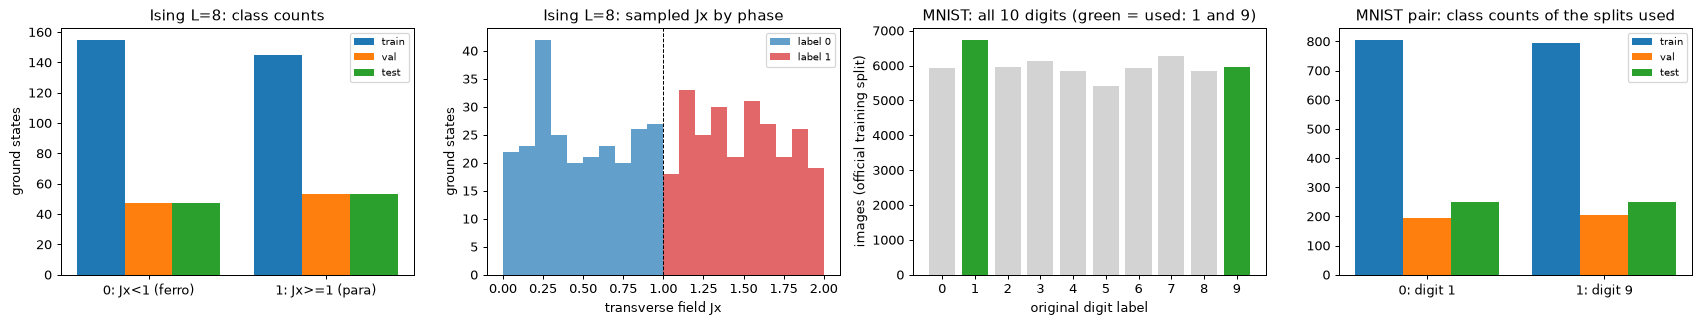

In [9]:
# ---- 2. real class distributions (bar charts / histograms) ----
fig, ax = plt.subplots(1, 4, figsize=(19, 3.7))
width = 0.27
for i, k in enumerate(("train", "val", "test")):
    ax[0].bar(np.arange(2) + (i - 1) * width, np.bincount(ISING[k][1], minlength=2), width, label=k)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["0: Jx<1 (ferro)", "1: Jx>=1 (para)"]); ax[0].set_ylabel("ground states"); ax[0].set_title("Ising L=8: class counts"); ax[0].legend(fontsize=8)
for lab, col in ((0, "tab:blue"), (1, "tab:red")):
    ax[1].hist(np.concatenate([ISING[k][2][ISING[k][1] == lab] for k in ISING]), bins=np.linspace(0, 2, 21), color=col, alpha=0.7, label=f"label {lab}")
ax[1].axvline(1.0, color="k", ls="--", lw=0.8); ax[1].set_xlabel("transverse field Jx"); ax[1].set_ylabel("ground states"); ax[1].set_title("Ising L=8: sampled Jx by phase"); ax[1].legend(fontsize=8)
ax[2].bar(range(10), MN["counts_train"], color=["tab:green" if c in DIGITS else "lightgrey" for c in range(10)])
ax[2].set_xticks(range(10)); ax[2].set_xlabel("original digit label"); ax[2].set_ylabel("images (official training split)"); ax[2].set_title(f"MNIST: all 10 digits (green = used: {DIGITS[0]} and {DIGITS[1]})")
for i, k in enumerate(("train", "val", "test")):
    ax[3].bar(np.arange(2) + (i - 1) * width, np.bincount(MNIST[k][1], minlength=2), width, label=k)
ax[3].set_xticks([0, 1]); ax[3].set_xticklabels([f"0: digit {DIGITS[0]}", f"1: digit {DIGITS[1]}"]); ax[3].set_title("MNIST pair: class counts of the splits used"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

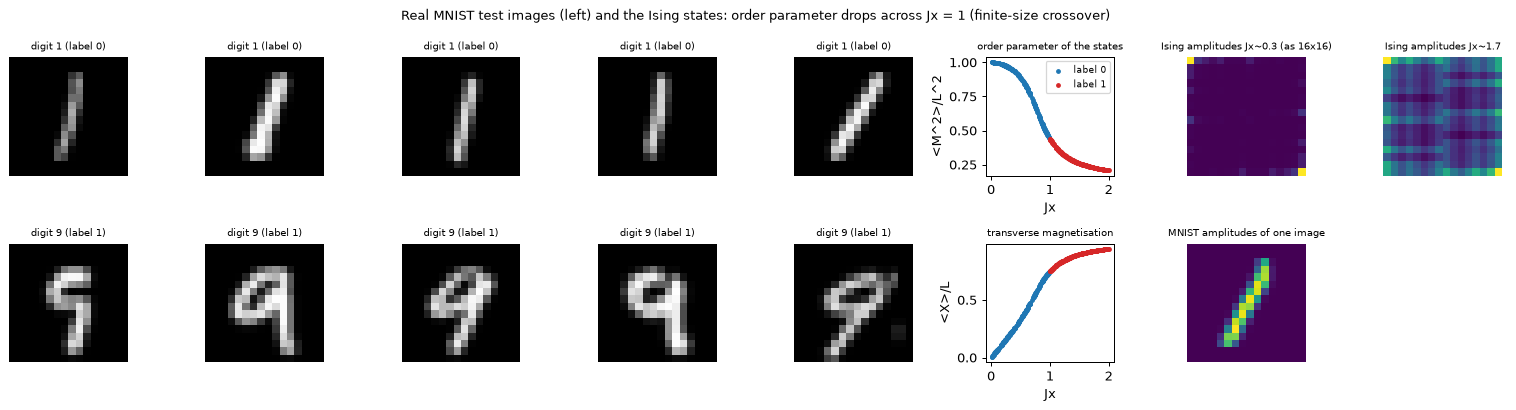

In [10]:
# ---- 3. real images, and the physics of the generated states ----
fig, ax = plt.subplots(2, 8, figsize=(17, 4.6))
Xte_m, yte_m, _ = MNIST["test"]
for r, lab in enumerate((0, 1)):
    for j in range(5):
        i = np.where(yte_m == lab)[0][j]
        ax[r, j].imshow(MN["X_test"][i].reshape(16, 16), cmap="gray", vmin=0, vmax=1); ax[r, j].set_title(f"digit {DIGITS[lab]} (label {lab})", fontsize=8); ax[r, j].axis("off")
allJ = np.concatenate([ISING[k][2] for k in ISING]); allX = np.concatenate([ISING[k][0] for k in ISING]); allY = np.concatenate([ISING[k][1] for k in ISING])
m2 = np.array([(p ** 2) @ CHAIN8.mag ** 2 for p in allX]) / N_DATA ** 2
sx = np.array([p @ (CHAIN8.Hx @ p) for p in allX]) / N_DATA
for lab, col in ((0, "tab:blue"), (1, "tab:red")):
    ax[0, 5].scatter(allJ[allY == lab], m2[allY == lab], s=8, c=col, label=f"label {lab}"); ax[1, 5].scatter(allJ[allY == lab], sx[allY == lab], s=8, c=col)
ax[0, 5].set_xlabel("Jx"); ax[0, 5].set_ylabel("<M^2>/L^2"); ax[0, 5].set_title("order parameter of the states", fontsize=8); ax[0, 5].legend(fontsize=7)
ax[1, 5].set_xlabel("Jx"); ax[1, 5].set_ylabel("<X>/L"); ax[1, 5].set_title("transverse magnetisation", fontsize=8)
for j in (6, 7):
    ax[0, j].axis("off"); ax[1, j].axis("off")
ax[0, 6].imshow(allX[np.argmin(np.abs(allJ - 0.3))].reshape(16, 16), cmap="viridis"); ax[0, 6].set_title("Ising amplitudes Jx~0.3 (as 16x16)", fontsize=8)
ax[0, 7].imshow(allX[np.argmin(np.abs(allJ - 1.7))].reshape(16, 16), cmap="viridis"); ax[0, 7].set_title("Ising amplitudes Jx~1.7", fontsize=8)
ax[1, 6].imshow(MNIST["train"][0][0].reshape(16, 16), cmap="viridis"); ax[1, 6].set_title("MNIST amplitudes of one image", fontsize=8)
plt.suptitle("Real MNIST test images (left) and the Ising states: order parameter drops across Jx = 1 (finite-size crossover)", fontsize=10); plt.tight_layout(); plt.show()

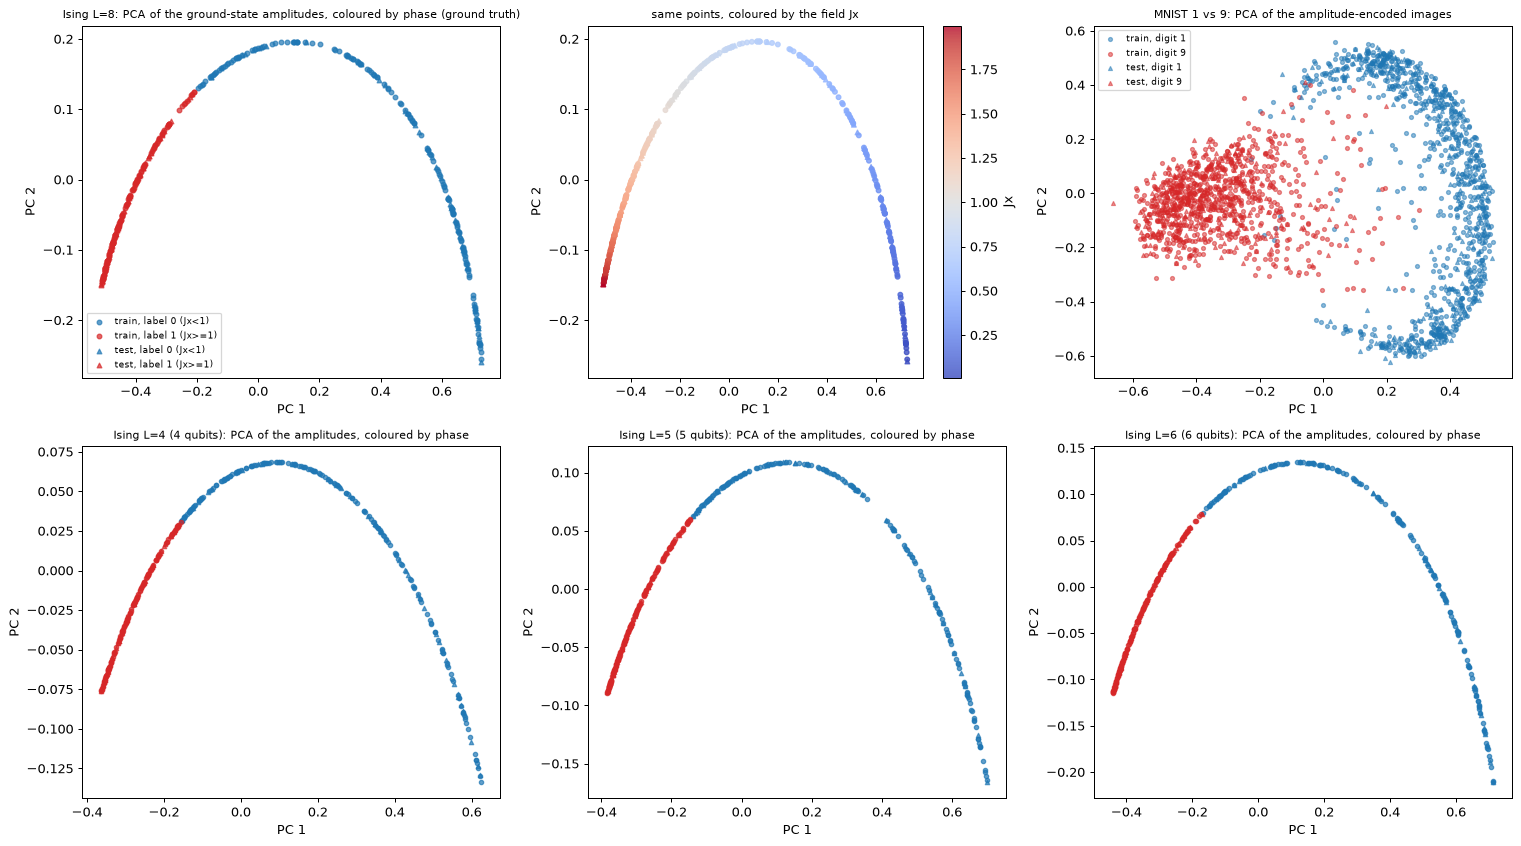

explained variance of the first two components - Ising L=8: [0.933 0.063], MNIST: [0.293 0.182]


In [11]:
# ---- 4. 2-D scatter of the real observations, coloured by ground-truth label (PCA fitted on the training split only) ----
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
pca_i = PCA(n_components=2, random_state=SEED).fit(ISING["train"][0])
for k, mk in (("train", "o"), ("test", "^")):
    X, y, J = ISING[k]; Z = pca_i.transform(X)
    for lab, col in ((0, "tab:blue"), (1, "tab:red")):
        ax[0, 0].scatter(Z[y == lab, 0], Z[y == lab, 1], s=14, c=col, marker=mk, alpha=0.7, label=f"{k}, label {lab} ({'Jx<1' if lab == 0 else 'Jx>=1'})")
    sc = ax[0, 1].scatter(Z[:, 0], Z[:, 1], s=14, c=J, cmap="coolwarm", marker=mk, alpha=0.8)
ax[0, 0].set_title("Ising L=8: PCA of the ground-state amplitudes, coloured by phase (ground truth)"); ax[0, 0].legend(fontsize=7)
ax[0, 1].set_title("same points, coloured by the field Jx"); plt.colorbar(sc, ax=ax[0, 1], label="Jx")
pca_m = PCA(n_components=2, random_state=SEED).fit(MNIST["train"][0])
for k, mk in (("train", "o"), ("test", "^")):
    X, y, dg = MNIST[k]; Z = pca_m.transform(X)
    for lab, col in ((0, "tab:blue"), (1, "tab:red")):
        ax[0, 2].scatter(Z[y == lab, 0], Z[y == lab, 1], s=10, c=col, marker=mk, alpha=0.5, label=f"{k}, digit {DIGITS[lab]}")
ax[0, 2].set_title("MNIST 1 vs 9: PCA of the amplitude-encoded images"); ax[0, 2].legend(fontsize=7)
for a, L_ in zip(ax[1], [l for l in sorted(CHAINS) if l != N_DATA][:3]):
    dat = CHAINS[L_]["data"]; p_ = PCA(n_components=2, random_state=SEED).fit(dat["train"][0])
    for lab, col in ((0, "tab:blue"), (1, "tab:red")):
        for k, mk in (("train", "o"), ("test", "^")):
            Z = p_.transform(dat[k][0]); y = dat[k][1]; a.scatter(Z[y == lab, 0], Z[y == lab, 1], s=12, c=col, marker=mk, alpha=0.7)
    a.set_title(f"Ising L={L_} ({L_} qubits): PCA of the amplitudes, coloured by phase")
for a in ax[1][len([l for l in CHAINS if l != N_DATA]):]: a.axis("off")             # no extra chain for this panel
for a in ax.ravel():
    if a.axison: a.set_xlabel("PC 1"); a.set_ylabel("PC 2"); a.title.set_fontsize(9)
plt.tight_layout(); plt.show()
print(f"explained variance of the first two components - Ising L=8: {pca_i.explained_variance_ratio_.round(3)}, MNIST: {pca_m.explained_variance_ratio_.round(3)}")

## 3. Training the eight classifiers (and classical baselines on the same inputs)

Every classifier is trained with **Adam** on the **cross-entropy** of the two output probabilities (paper, Eqs. S18 and Sec. S-III), for 20 epochs (8 in FAST mode); the number of iterations per epoch follows the paper's Fig. S2 caption
(Ising: 30 for the QCNN, 5 for the deep variational circuit; MNIST: 50 and 10), and the mini-batch size is inferred from them (300 training states / 30 = 10 and 300 / 5 = 60). Gradients come from automatic
differentiation of the exact simulator (the paper also uses the parameter-shift rule, which gives the same gradient). The whole set of eight classifiers is trained on both datasets; the Ising set is repeated with
`N_SEEDS` different initialisations (the training data stay fixed, only the random initial angles and the mini-batch order change).

Classical baselines on **exactly the same inputs** (the 256 amplitudes): logistic regression, an RBF-kernel SVM, a random forest and a small neural network (256-64-2, tanh) that is also used as the
classical model in the attack controls later. They are not part of the paper; they show how hard the two tasks are for a standard learner.

In [12]:
to_t = lambda X: torch.as_tensor(np.asarray(X), dtype=CDT)
DS = {"ising": {k: (to_t(ISING[k][0]), torch.as_tensor(ISING[k][1])) for k in ("train", "val", "test")},
      "mnist": {k: (to_t(MNIST[k][0]), torch.as_tensor(MNIST[k][1])) for k in ("train", "val", "test")}}
ce_loss = lambda p, y: -torch.log(p.gather(1, y[:, None]).squeeze(1) + 1e-12)       # cross entropy of the measured output probabilities
pred_label = lambda p: (p[:, 1] >= p[:, 0]).long()                                  # paper: y = 1 if P(1) >= P(0)

class QModel:
    # a trained quantum classifier: circuit + angles. probs(psi, delta) -> (B, 2) probabilities, delta = optional perturbation layer
    def __init__(self, circ, theta, name=None): self.circ, self.theta, self.name = circ, theta, name or circ.name
    def probs(self, psi, delta=None): return self.circ.probs(psi, self.theta, delta)

def evaluate(model, X, y):
    with torch.no_grad():
        p = model.probs(X); return float(ce_loss(p, y).mean()), float((pred_label(p) == y).float().mean())

def train_classifier(circ, data, epochs, its, bs, lr, seed, init_std=INIT_STD):
    # Adam on the cross-entropy; returns the angles and the per-epoch history (loss / accuracy on the full training and validation sets, as in Fig. S2)
    g = torch.Generator().manual_seed(seed)
    theta = (torch.randn(circ.n_params, generator=g, dtype=torch.float64) * init_std).requires_grad_()
    opt = torch.optim.Adam([theta], lr=lr); (Xtr, ytr), (Xva, yva) = data["train"], data["val"]
    hist = dict(loss_tr=[], loss_va=[], acc_tr=[], acc_va=[])
    for ep in range(epochs):
        for _ in range(its):
            idx = torch.randint(0, len(ytr), (bs,), generator=g)
            loss = ce_loss(circ.probs(Xtr[idx], theta), ytr[idx]).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        m = QModel(circ, theta.detach())
        for nm, (X_, y_) in (("tr", (Xtr, ytr)), ("va", (Xva, yva))):
            l_, a_ = evaluate(m, X_, y_); hist["loss_" + nm].append(l_); hist["acc_" + nm].append(a_)
    return theta.detach(), hist

def train_set(ds_name, seed_idx):
    # the eight classifiers of the paper on one dataset
    out_t, out_h = {}, {}
    for i, circ in enumerate(ARCHS):
        kind = "qcnn" if circ.name.startswith("QCNN") else "vc"
        its, bs = (ISING_ITS[kind], ISING_BS[kind]) if ds_name == "ising" else (MNIST_ITS[kind], MNIST_BS)
        out_t[circ.name], out_h[circ.name] = train_classifier(circ, DS[ds_name], EPOCHS, its, bs, LR[kind], seed=SEED + 1000 * seed_idx + 17 * i)
    return out_t, out_h

In [13]:
t0 = time.time()
THETA, HIST = {}, {}
for s in range(N_SEEDS):
    THETA[("ising", s)], HIST[("ising", s)] = train_set("ising", s)
    print(f"[{time.time() - t0:6.0f}s] Ising classifiers, seed {s} trained:", {k: round(v["acc_tr"][-1], 3) for k, v in HIST[("ising", s)].items()})
THETA[("mnist", 0)], HIST[("mnist", 0)] = train_set("mnist", 0)
print(f"[{time.time() - t0:6.0f}s] MNIST classifiers trained:", {k: round(v["acc_va"][-1], 3) for k, v in HIST[("mnist", 0)].items()})
T_TRAIN = time.time() - t0

[    73s] Ising classifiers, seed 0 trained: {'QCNN-1': 0.893, 'QCNN-2': 0.893, 'VC-p5': 0.943, 'VC-p6': 0.913, 'VC-p7': 0.96, 'VC-p8': 0.897, 'VC-p9': 0.96, 'VC-p10': 0.923}


[   148s] Ising classifiers, seed 1 trained: {'QCNN-1': 0.9, 'QCNN-2': 0.883, 'VC-p5': 0.923, 'VC-p6': 0.923, 'VC-p7': 0.913, 'VC-p8': 0.917, 'VC-p9': 0.917, 'VC-p10': 0.893}


[   228s] Ising classifiers, seed 2 trained: {'QCNN-1': 0.913, 'QCNN-2': 0.89, 'VC-p5': 0.887, 'VC-p6': 0.92, 'VC-p7': 0.913, 'VC-p8': 0.913, 'VC-p9': 0.917, 'VC-p10': 0.92}


[   446s] MNIST classifiers trained: {'QCNN-1': 0.975, 'QCNN-2': 0.978, 'VC-p5': 0.983, 'VC-p6': 0.983, 'VC-p7': 0.983, 'VC-p8': 0.98, 'VC-p9': 0.988, 'VC-p10': 0.988}


In [14]:
# ---- the trained models used from here on, and the classical baselines on the same amplitude vectors ----
ENS = {"ising": [[QModel(c, THETA[("ising", s)][c.name]) for c in ARCHS] for s in range(N_SEEDS)],
       "mnist": [[QModel(c, THETA[("mnist", 0)][c.name]) for c in ARCHS]]}
Q_ISING, Q_MNIST = ENS["ising"][0], ENS["mnist"][0]                                   # classifier set of the first seed: used for the attacks

def split_acc(models, ds_name):
    return np.array([[evaluate(m, *DS[ds_name][k])[1] for k in ("train", "val", "test")] for m in models])
rows = []
ACC_ISING = np.stack([split_acc(ENS["ising"][s], "ising") for s in range(N_SEEDS)])      # (seed, classifier, split)
ACC_MNIST = split_acc(Q_MNIST, "mnist")
for i, c in enumerate(ARCHS):
    a = ACC_ISING[:, i, :]
    am = ACC_MNIST[i]
    rows.append(dict(classifier=i + 1, structure=c.name, parameters=c.n_params, paper_accuracy=[0.917, 0.950, 0.923, 0.930, 0.940, 0.930, 0.947, 0.955][i],
                     ising_train_acc=f"{a[:, 0].mean():.3f} +- {a[:, 0].std():.3f}", ising_val_acc=round(a[:, 1].mean(), 3), ising_test_acc=round(a[:, 2].mean(), 3),
                     mnist_train_acc=round(am[0], 3), mnist_val_acc=round(am[1], 3), mnist_test_acc=round(am[2], 3)))
TABLE_S1 = pd.DataFrame(rows)
print(f"Table S1 recomputed (Ising training accuracy: mean +- std over {N_SEEDS} seed(s)); paper_accuracy = paper's Table S1 (accuracy over its 300 training states)")
display(TABLE_S1)

# classical baselines (numpy, identical inputs: the amplitude vectors)
BASE = {}
for ds_name, src in (("ising", ISING), ("mnist", MNIST)):
    Xtr, ytr = src["train"][0], src["train"][1]
    for nm, clf in (("LogReg", LogisticRegression(max_iter=5000)), ("SVC(rbf)", SVC(kernel="rbf", C=10.0, gamma="scale", random_state=SEED)),
                    ("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED))):
        clf.fit(Xtr, ytr)
        BASE[(ds_name, nm)] = {k: float((clf.predict(src[k][0]) == src[k][1]).mean()) for k in ("train", "val", "test")}
class MLPModel:
    # classical 256-64-2 network on |amplitudes| (the Ising ground states and the MNIST amplitudes are non-negative, so |psi| = psi on clean data;
    # for a perturbed (complex) state the magnitudes are what a classical model could see). Same probs(psi, delta) interface as the quantum models.
    def __init__(self, seed):
        torch.manual_seed(seed); self.net = nn.Sequential(nn.Linear(2 ** N_DATA, 64), nn.Tanh(), nn.Linear(64, 2)).double(); self.name = "MLP"
    def probs(self, psi, delta=None):
        if delta is not None: psi = apply_local_rot(psi, delta, N_DATA)
        return torch.softmax(self.net(torch.sqrt(psi.real ** 2 + psi.imag ** 2 + 1e-14)), 1)
def train_mlp(ds_name, seed, epochs=400):
    m = MLPModel(seed); opt = torch.optim.Adam(m.net.parameters(), lr=0.01); Xtr, ytr = DS[ds_name]["train"]
    for _ in range(epochs):
        loss = ce_loss(m.probs(Xtr), ytr).mean(); opt.zero_grad(); loss.backward(); opt.step()
    return m
MLPS = {ds_name: train_mlp(ds_name, SEED) for ds_name in ("ising", "mnist")}
for ds_name in ("ising", "mnist"):
    BASE[(ds_name, "MLP 256-64-2")] = {k: evaluate(MLPS[ds_name], *DS[ds_name][k])[1] for k in ("train", "val", "test")}
display(pd.DataFrame([dict(dataset=k[0], model=k[1], **{s: round(v, 3) for s, v in d.items()}) for k, d in BASE.items()]))
print(f"training of all classifiers took {T_TRAIN:.0f} s")

Table S1 recomputed (Ising training accuracy: mean +- std over 3 seed(s)); paper_accuracy = paper's Table S1 (accuracy over its 300 training states)


,classifier,structure,parameters,paper_accuracy,ising_train_acc,ising_val_acc,ising_test_acc,mnist_train_acc,mnist_val_acc,mnist_test_acc
0,1,QCNN-1,44,0.917,0.902 +- 0.008,0.887,0.930,0.974,0.975,0.982
1,2,QCNN-2,92,0.950,0.889 +- 0.004,0.873,0.910,0.972,0.978,0.986
2,3,VC-p5,144,0.923,0.918 +- 0.023,0.900,0.950,0.979,0.983,0.992
3,4,VC-p6,171,0.930,0.919 +- 0.004,0.900,0.963,0.979,0.983,0.988
4,5,VC-p7,198,0.940,0.929 +- 0.022,0.913,0.960,0.981,0.983,0.992
5,6,VC-p8,225,0.930,0.909 +- 0.009,0.893,0.943,0.982,0.980,0.988
6,7,VC-p9,252,0.947,0.931 +- 0.020,0.913,0.963,0.978,0.988,0.992
7,8,VC-p10,279,0.955,0.912 +- 0.013,0.893,0.950,0.986,0.988,0.990


,dataset,model,train,val,test
0,ising,LogReg,0.973,0.960,0.980
1,ising,SVC(rbf),1.000,1.000,1.000
2,ising,RandomForest,1.000,1.000,1.000
3,mnist,LogReg,0.992,0.990,0.994
4,mnist,SVC(rbf),1.000,0.998,0.998
5,mnist,RandomForest,1.000,0.993,0.994
6,ising,MLP 256-64-2,1.000,1.000,1.000
7,mnist,MLP 256-64-2,1.000,0.993,0.994


training of all classifiers took 446 s


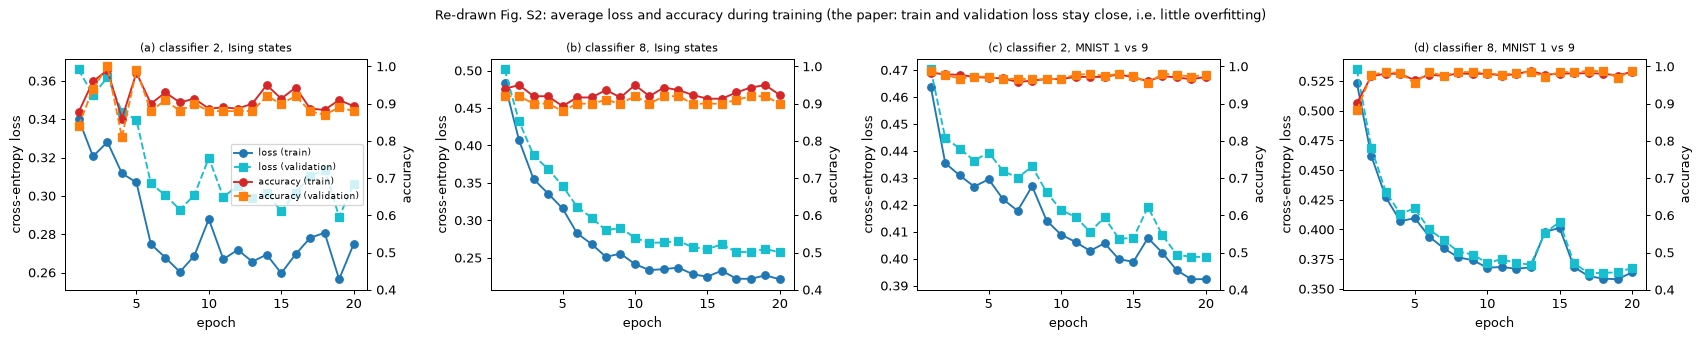

final |train loss - validation loss|: {('ising', 'QCNN-2'): 0.031, ('ising', 'VC-p10'): 0.036, ('mnist', 'QCNN-2'): 0.008, ('mnist', 'VC-p10'): 0.004}


In [15]:
# ---- Fig. S2 re-drawn: loss and accuracy of classifiers 2 (QCNN) and 8 (depth 10) during training, on the training and validation sets ----
fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
for a, (ds_name, nm, ttl) in zip(ax, (("ising", "QCNN-2", "(a) classifier 2, Ising states"), ("ising", "VC-p10", "(b) classifier 8, Ising states"),
                                      ("mnist", "QCNN-2", "(c) classifier 2, MNIST 1 vs 9"), ("mnist", "VC-p10", "(d) classifier 8, MNIST 1 vs 9"))):
    h = HIST[(ds_name, 0)][nm]; ep = np.arange(1, len(h["loss_tr"]) + 1)
    a.plot(ep, h["loss_tr"], "o-", c="tab:blue", label="loss (train)"); a.plot(ep, h["loss_va"], "s--", c="tab:cyan", label="loss (validation)")
    a.set_xlabel("epoch"); a.set_ylabel("cross-entropy loss"); a.set_title(ttl, fontsize=9)
    b = a.twinx(); b.plot(ep, h["acc_tr"], "o-", c="tab:red", label="accuracy (train)"); b.plot(ep, h["acc_va"], "s--", c="tab:orange", label="accuracy (validation)"); b.set_ylim(0.4, 1.02); b.set_ylabel("accuracy")
    if a is ax[0]:
        l1, n1 = a.get_legend_handles_labels(); l2, n2 = b.get_legend_handles_labels(); a.legend(l1 + l2, n1 + n2, fontsize=7, loc="center right")
plt.suptitle("Re-drawn Fig. S2: average loss and accuracy during training (the paper: train and validation loss stay close, i.e. little overfitting)", fontsize=10); plt.tight_layout(); plt.show()
GAP = {(d_, n_): abs(HIST[(d_, 0)][n_]["loss_tr"][-1] - HIST[(d_, 0)][n_]["loss_va"][-1]) for d_ in ("ising", "mnist") for n_ in ("QCNN-2", "VC-p10")}
print("final |train loss - validation loss|:", {k: round(v, 3) for k, v in GAP.items()})

## Quantum Circuit Architecture

All eight classifiers are gate-model circuits, so every architecture is drawn below. The drawings are **real Qiskit circuits built from the same gate list that the simulator runs** (`to_qiskit`): the amplitude encoder
(a `StatePreparation` box that loads the 256 normalised amplitudes into the 8 data qubits), an `X` gate that puts the label qubit of the variational classifiers into |1>, the parametrised gates (angles shown symbolically as `t[i]`), the entangling
CNOT / controlled-rotation gates, and the read-out: a measurement of the output qubit into one classical bit (the last qubit; for the QCNNs the surviving qubit of the last pooling stage). The simulations use the exact probabilities of that measurement instead of sampled shots; the drawn circuits include the measurement gate, the statevector comparison below excludes it.

* A cell first prints, for every classifier, the number of qubits, the circuit depth (Qiskit's `depth()`, the amplitude encoder counted as one operation) and the number of trainable parameters, and then **asserts that the torch simulator
  and Qiskit's exact state-vector simulation agree to 1e-8** for the *trained* angles on real test inputs (Ising states and MNIST images), with and without the attack's perturbation layer.
* One drawing per distinct architecture: the two QCNNs (different unit sizes), the variational classifier (depth 5 = classifier 3, depth 10 = classifier 8; classifiers 4 to 7 are the same circuit with 6 to 9 layers) and the attack's perturbation layer.
* **Assumptions where the paper omits circuit details** (they are marked `# CHOICE` in the code): the QCNN convolution / pooling / FC gates (the paper only gives their number and the parameter counts 44 and 92, which are matched exactly),
  the CNOT chain direction (0 -> 1 -> ... -> label qubit) of the variational classifiers, the final R_y layer that makes 27 p + 9 parameters, and the Euler rotation order Rz Rx Rz.

In [16]:
def circuit_stats(circ, theta, psi_row):
    qc = to_qiskit(circ, np.asarray(theta, dtype=float), psi_row)
    ops = dict(qc.count_ops())
    return dict(classifier=circ.name, qubits=qc.num_qubits, depth=qc.depth(), gates=int(sum(ops.values())), cnot=int(ops.get("cx", 0)), controlled_rot=int(sum(v for k, v in ops.items() if k in ("crz", "crx", "cry"))),
                trainable_parameters=circ.n_params)

rows = [circuit_stats(m.circ, m.theta, ISING["test"][0][0]) for m in Q_ISING]
display(pd.DataFrame(rows))
print("depth counts the amplitude encoder (StatePreparation) and the X on the label qubit as one operation each; 'gates' include them. The parameter counts equal Table S1: 44, 92, 144, 171, 198, 225, 252, 279.")

# equivalence of the torch simulator and Qiskit for the TRAINED angles on REAL inputs, with and without the perturbation layer
g_ = np.random.default_rng(SEED + 5); worst = 0.0
for ds_name, models, src in (("Ising", Q_ISING, ISING), ("MNIST", Q_MNIST, MNIST)):
    X3 = src["test"][0][:3]
    for m in models:
        worst = max(worst, check_equivalence(m.circ, m.theta.numpy(), X3), check_equivalence(m.circ, m.theta.numpy(), X3, delta=g_.normal(size=3 * N_DATA) * 0.4))
print(f"torch simulator == Qiskit state vector for all 16 trained classifiers (8 on Ising, 8 on MNIST), 3 real inputs each, with and without perturbation: largest difference {worst:.1e}  (assert < 1e-8; Qiskit's state-preparation synthesis ignores rotation angles below 1e-10)")

,classifier,qubits,depth,gates,cnot,controlled_rot,trainable_parameters
0,QCNN-1,8,49,172,23,12,44
1,QCNN-2,8,97,347,46,18,92
2,VC-p5,9,33,186,40,0,144
3,VC-p6,9,38,221,48,0,171
4,VC-p7,9,43,256,56,0,198
5,VC-p8,9,48,291,64,0,225
6,VC-p9,9,53,326,72,0,252
7,VC-p10,9,58,361,80,0,279


depth counts the amplitude encoder (StatePreparation) and the X on the label qubit as one operation each; 'gates' include them. The parameter counts equal Table S1: 44, 92, 144, 171, 198, 225, 252, 279.


torch simulator == Qiskit state vector for all 16 trained classifiers (8 on Ising, 8 on MNIST), 3 real inputs each, with and without perturbation: largest difference 9.1e-11  (assert < 1e-8; Qiskit's state-preparation synthesis ignores rotation angles below 1e-10)


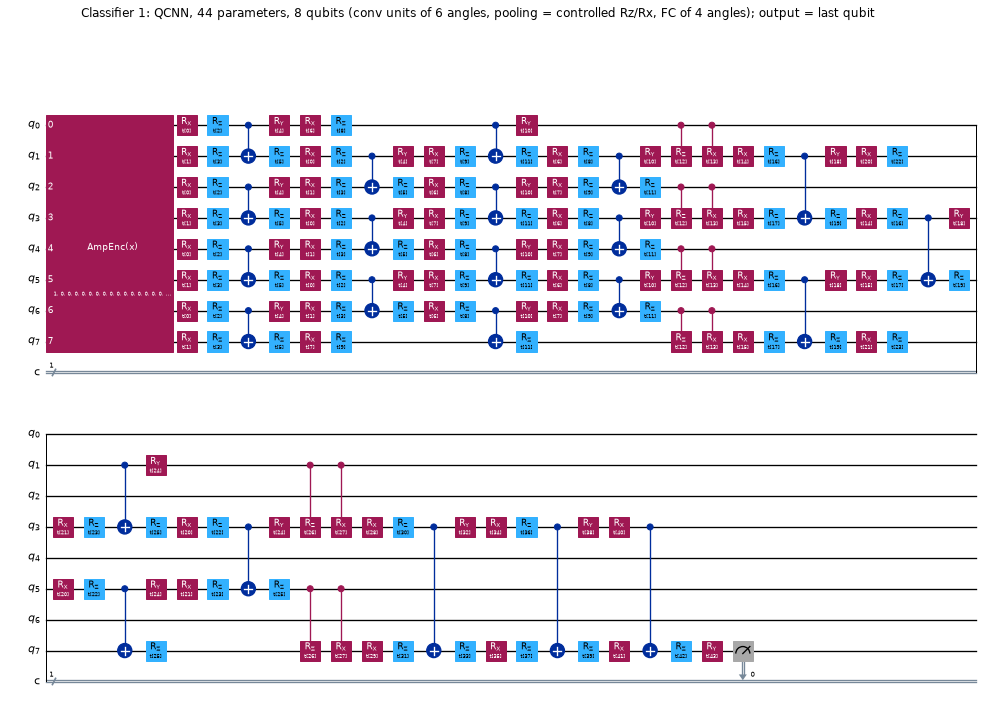

QCNN-1: 44 parameters, depth 49, 8 qubits


In [17]:
# ---- drawings of the executed circuits (symbolic angles t[i]; the numbers used are the trained ones listed in THETA) ----
def draw(qc, title, fold, scale=0.5):
    fig = qc.draw("mpl", fold=fold, scale=scale, plot_barriers=False)
    fig.suptitle(title, fontsize=11, y=1.0); fig.set_dpi(80)
    display(fig); plt.close(fig)                       # Qiskit closes its figure after drawing, so it must be displayed explicitly

draw(to_qiskit(ARCHS[0], measure=True), f"Classifier 1: QCNN, {ARCHS[0].n_params} parameters, 8 qubits (conv units of 6 angles, pooling = controlled Rz/Rx, FC of 4 angles); output = last qubit", fold=30, scale=0.6)
print(f"QCNN-1: {ARCHS[0].n_params} parameters, depth {to_qiskit(ARCHS[0]).depth()}, 8 qubits")

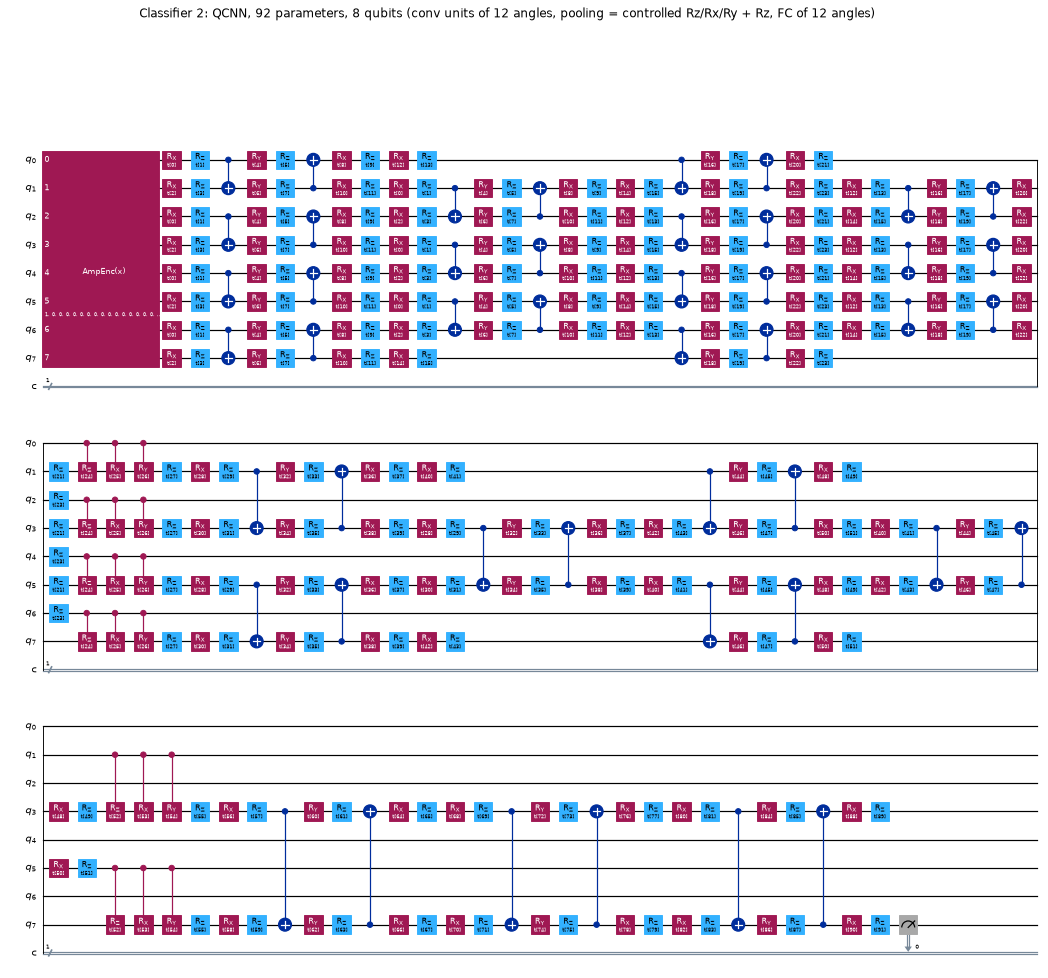

QCNN-2: 92 parameters, depth 97, 8 qubits


In [18]:
draw(to_qiskit(ARCHS[1], measure=True), f"Classifier 2: QCNN, {ARCHS[1].n_params} parameters, 8 qubits (conv units of 12 angles, pooling = controlled Rz/Rx/Ry + Rz, FC of 12 angles)", fold=35, scale=0.55)
print(f"QCNN-2: {ARCHS[1].n_params} parameters, depth {to_qiskit(ARCHS[1]).depth()}, 8 qubits")

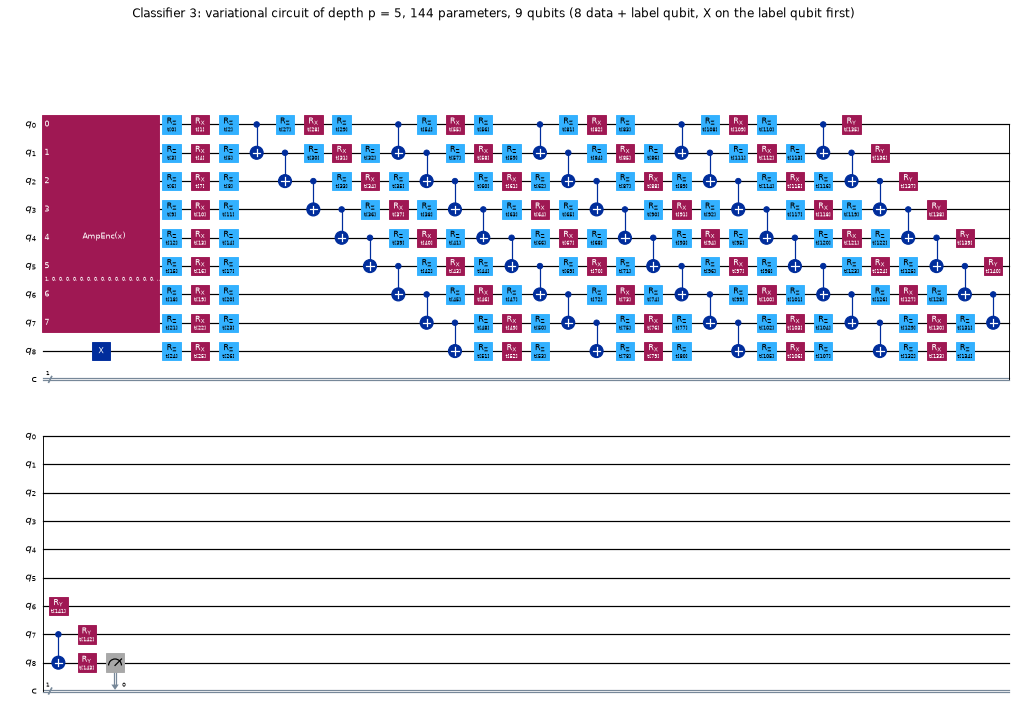

VC-p5: 144 parameters, depth 33, 9 qubits


In [19]:
draw(to_qiskit(ARCHS[2], measure=True), f"Classifier 3: variational circuit of depth p = 5, {ARCHS[2].n_params} parameters, 9 qubits (8 data + label qubit, X on the label qubit first)", fold=34, scale=0.55)
print(f"VC-p5: {ARCHS[2].n_params} parameters, depth {to_qiskit(ARCHS[2]).depth()}, 9 qubits")

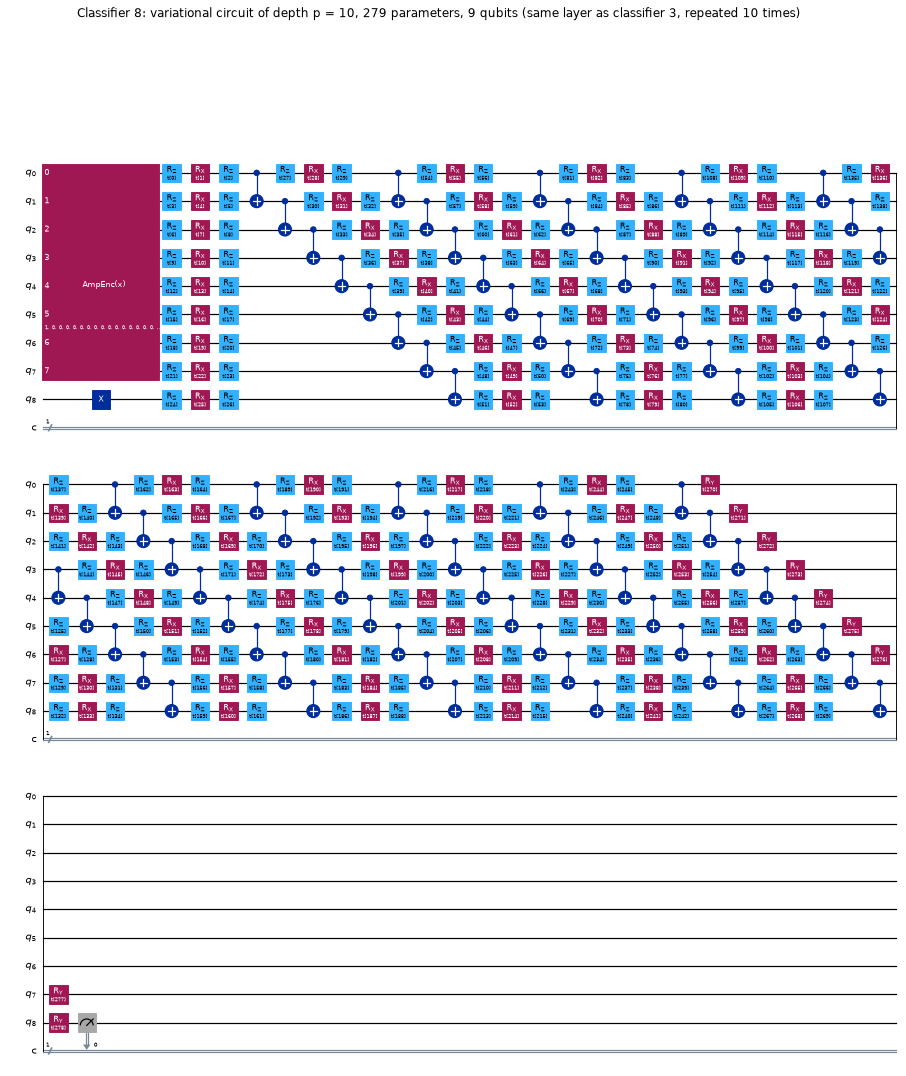

VC-p10: 279 parameters, depth 58, 9 qubits


In [20]:
draw(to_qiskit(ARCHS[7], measure=True), f"Classifier 8: variational circuit of depth p = 10, {ARCHS[7].n_params} parameters, 9 qubits (same layer as classifier 3, repeated 10 times)", fold=30, scale=0.55)
print(f"VC-p10: {ARCHS[7].n_params} parameters, depth {to_qiskit(ARCHS[7]).depth()}, 9 qubits")

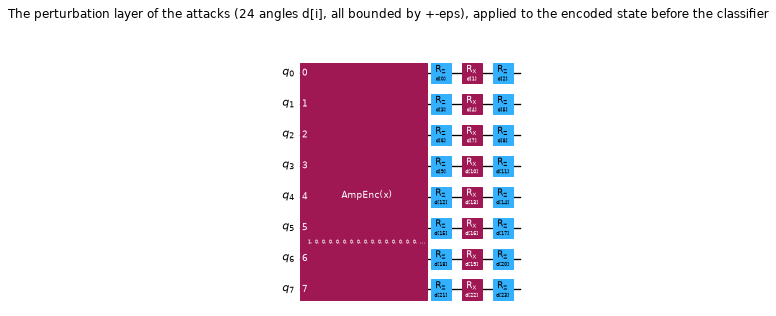

perturbation layer: 8 qubits, depth 4, 24 parameters; the classifier then acts on 8 (QCNN) or 8 + 1 (variational) qubits


In [21]:
# the attack unitary: Rz Rx Rz on each data qubit with angles |delta| <= eps (24 parameters), prepended to any classifier (here shown in front of the loader only)
att = QuantumCircuit(N_DATA, 0); dv = ParameterVector("d", 3 * N_DATA)
att.append(StatePreparation(np.eye(2 ** N_DATA)[0], label="AmpEnc(x)"), list(range(N_DATA)))
for q in range(N_DATA): att.rz(dv[3 * q], q); att.rx(dv[3 * q + 1], q); att.rz(dv[3 * q + 2], q)
draw(att, "The perturbation layer of the attacks (24 angles d[i], all bounded by +-eps), applied to the encoded state before the classifier", fold=40, scale=0.6)
print(f"perturbation layer: {att.num_qubits} qubits, depth {att.depth()}, 24 parameters; the classifier then acts on 8 (QCNN) or 8 + 1 (variational) qubits")

## 4. Universal adversarial examples (paper Fig. 2)

**The attack.** The paper uses the *quantum-adapted basic iterative method* (qBIM, Lu, Duan and Deng 2020) with step size alpha = 0.02. The perturbation is a product of **local unitaries near the identity** applied to the input state
(Supplement, Sec. S-IV); here that is the layer of 24 angles drawn in the circuit section (`Rz Rx Rz` on each of the 8 data qubits). qBIM starts at angles 0 and repeats
`angles <- project(angles + alpha * sign(gradient of the summed cross entropy))` for `ceil(1.25 eps / alpha) + 2` iterations, with gradients from the simulator, where `project` shrinks the angles until the perturbation has strength `eps`.

**Perturbation strength `eps`.** The paper's figures label the x axis "perturbation strength" without defining it for the simulations. Its theory (Definition 2) measures a perturbation by the **normalised Hilbert-Schmidt distance** between the legitimate and the perturbed state,
which for pure states is `D = sqrt(1 - F)` with the fidelity `F = |<psi|psi'>|^2`. The fidelities quoted in the paper, "about 96 %" for the examples of Fig. 2a and "about 78 %" for Fig. 3a, are `D = 0.2` and `D = 0.47`, i.e. exactly the ranges of the x axes (0 to 0.2 / 0.3 in Fig. 2, 0 to 0.8 in Fig. 3).
We therefore take: **for universal adversarial examples, `D(psi, psi') <= eps` for every input**; **for universal perturbations (one unitary `U` for all inputs), the operator distance `sqrt(1 - |tr U / d|^2) <= eps`**, which does not depend on the input and equals the typical state distance
(the Haar average of `1 - F` is `1 - |tr U / d|^2` up to `1/d` corrections). A first pilot that read `eps` as a bound on the rotation *angles* gave a fidelity of only 0.38 at `eps = 0.18`, nowhere near the paper's 0.96, and was dropped before any figure was drawn; the definition was chosen from the quoted fidelities,
not tuned to the quoted risks. The fidelity of the attacked states is reported everywhere.

**Universal adversarial examples** (one input that deceives a whole *set* of classifiers): for every test state the perturbation maximises `sum_i CE(h_i(U_delta psi), label)` over the classifiers `h_i` of the set (Eq. S20). The *universal adversarial risk*
is the share of test states that are misclassified by **all** classifiers of the set after the attack. The attacker is **white-box** when it knows all classifiers of the set, and **hybrid** (Fig. 2c) when it knows only one of them
and uses the perturbation crafted against it on the others (non-adaptive black-box transfer).

**Controls added here** (not in the paper): a *random-direction* perturbation of exactly the same strength (a random sign pattern of the 24 angles, scaled to strength `eps`: what the bound alone achieves without any optimisation), and a classical network
(256-64-2 on the amplitudes) attacked in the same way.

**One more control.** Besides the random-direction perturbation and the classical network, an **unrestricted state attack** is used throughout this section and the next ones: the perturbed state may be *any* state inside the Hilbert-Schmidt ball of radius `eps`
(`state_attack`: `psi' = cos(t) psi + sin(t) phi`, `sin t = eps`, `phi` orthogonal to `psi` and moved along the normalised gradient of the capped summed cross entropy for 20 steps). It is the numerical counterpart of Definition 2 and Theorem 1, and a lower bound on what any perturbation of that size can do.

In [22]:
N_PERT = 3 * N_DATA                                         # the 24 angles of the attack unitary
n_of = lambda psi: int(round(math.log2(psi.shape[1])))      # number of data qubits of a batch of amplitude vectors

def op_distance(delta, n):
    # strength of the unitary U = (x)_q Rz(d2) Rx(d1) Rz(d0): sqrt(1 - |tr U / d|^2) with tr U / d = prod_q cos(d1/2) cos((d0 + d2)/2); delta (..., 3n) -> (...)
    a = delta.reshape(*delta.shape[:-1], n, 3)
    c = (torch.cos(a[..., 1] / 2) * torch.cos((a[..., 0] + a[..., 2]) / 2)).prod(-1)
    return torch.sqrt(torch.clamp(1 - c ** 2, min=0.0))

def state_distance(psi, delta):
    # normalised Hilbert-Schmidt distance sqrt(1 - |<psi|U psi>|^2) between every input and its perturbed version (B,)
    phi = apply_local_rot(psi, delta, n_of(psi)); return torch.sqrt(torch.clamp(1 - (psi.conj() * phi).sum(1).abs() ** 2, min=0.0))

def project(delta, psi, eps, universal, iters=6):
    # shrink the angles (delta -> s * delta, s <= 1) until the strength is <= eps: state distance per input (examples) or operator distance (universal perturbation)
    n = n_of(psi); dist = (lambda d: op_distance(d, n)) if universal else (lambda d: state_distance(psi, d))
    s = torch.ones(delta.shape[:-1], dtype=torch.float64)
    for _ in range(iters):
        s = s * torch.clamp(eps / dist(delta * s[..., None]).clamp_min(1e-12), max=1.0)
    return delta * s[..., None]

def qbim(models, psi, y, eps, universal=False, alpha=ALPHA, n_iter=None):
    # Quantum basic iterative method: sign-gradient ascent on the summed cross entropy of `models`, perturbation strength limited to eps.
    # universal=False: one perturbation per input, shape (B, 24)  -> universal ADVERSARIAL EXAMPLES (the same input fools all `models`);
    # universal=True : one perturbation for all inputs, shape (24,) -> universal adversarial PERTURBATION (maximises the mean loss).
    B = psi.shape[0]; n_iter = int(math.ceil(ITER_FACTOR * eps / alpha)) + ITER_EXTRA if n_iter is None else n_iter
    npert = 3 * n_of(psi)
    if eps <= 0: return torch.zeros(npert if universal else (B, npert), dtype=torch.float64)
    delta = torch.zeros(npert if universal else (B, npert), dtype=torch.float64, requires_grad=True)
    for _ in range(n_iter):
        loss = sum(ce_loss(m.probs(psi, delta), y) for m in models)
        loss = loss.mean() if universal else loss.sum()
        g, = torch.autograd.grad(loss, delta)
        with torch.no_grad(): delta = project(delta.detach() + alpha * torch.sign(g), psi, eps, universal)
        delta.requires_grad_()
    return delta.detach()

def wrong_matrix(models, psi, y, delta=None):
    # (n_models, B) boolean: model i misclassifies input b
    with torch.no_grad(): return torch.stack([pred_label(m.probs(psi, delta)) != y for m in models])

def fidelity(psi, delta):
    if delta is None: return torch.ones(psi.shape[0], dtype=torch.float64)
    with torch.no_grad():
        phi = apply_local_rot(psi, delta, n_of(psi)); return (psi.conj() * phi).sum(1).abs() ** 2

def random_delta(psi, eps, g, universal=False):
    # control: a random sign pattern of the angles, scaled to exactly the strength eps (same strength as the attack, no optimisation)
    n = n_of(psi); shape = (3 * n,) if universal else (psi.shape[0], 3 * n)
    with torch.no_grad(): return project(torch.sign(torch.randn(*shape, generator=g, dtype=torch.float64)), psi, eps, universal, iters=25)

def risk(models, psi, y, delta=None):
    return float(wrong_matrix(models, psi, y, delta).all(0).float().mean())

CAP = 1.5 * math.log(2)          # CHOICE (control only): cross entropy above 1.5 ln 2 counts as "fooled", so the attack then stops pushing that classifier
def state_attack(models, psi, y, eps, steps=20, seed=0):
    # CONTROL, not in the paper: an unrestricted attack inside the same Hilbert-Schmidt ball, psi' = cos(t) psi + sin(t) phi with phi a unit vector orthogonal to psi and sin(t) = eps
    # (so sqrt(1 - F) = eps exactly). phi follows the normalised gradient of the capped summed cross entropy. Any perturbed state within distance eps can be written this way,
    # so this is a (lower-bound) estimate of what ANY perturbation of that size can do; qBIM with local rotations reaches only a 24-dimensional subset of these states.
    t = math.asin(min(eps, 1.0)); z = torch.randn(*psi.shape, 2, generator=torch.Generator().manual_seed(seed), dtype=torch.float64)
    perp = lambda v: v - (psi.conj() * v).sum(1, keepdim=True) * psi
    nrm = lambda v: v / v.norm(dim=1, keepdim=True).clamp_min(1e-12)
    phi = nrm(perp(torch.complex(z[..., 0], z[..., 1])))
    for k in range(steps):
        adv = (math.cos(t) * psi + math.sin(t) * phi).detach().requires_grad_()
        loss = sum(torch.clamp(ce_loss(m.probs(adv), y), max=CAP) for m in models).sum()
        g, = torch.autograd.grad(loss, adv)
        phi = nrm(perp(phi + (0.6 * (1 - k / steps) + 0.1) * nrm(g)))
    return (math.cos(t) * psi + math.sin(t) * phi).detach()

SUBSETS = {"classifiers 1, 2, 6": [0, 1, 5], "classifiers 1, 3, 6": [0, 2, 5], "classifiers 3, 6, 8": [2, 5, 7]}      # paper Fig. 2b
PSI_TE, Y_TE = DS["ising"]["test"]

# the strength constraint holds (and a random-direction control really has the requested strength): D <= eps for every input, operator distance <= eps for a shared unitary
_g = torch.Generator().manual_seed(SEED)
for _eps in (0.1, 0.2, 0.5):
    _d1 = random_delta(PSI_TE, _eps, _g); _d2 = random_delta(PSI_TE, _eps, _g, universal=True)
    print(f"eps = {_eps}: random-direction perturbations have state distance {float(state_distance(PSI_TE, _d1).max()):.4f} (max over inputs) and operator distance {float(op_distance(_d2, N_DATA)):.4f}; "
          f"mean state distance of the shared unitary over the test states {float(state_distance(PSI_TE, _d2.expand(len(PSI_TE), -1)).mean()):.3f}")
    assert float(state_distance(PSI_TE, _d1).max()) <= _eps * 1.001 and float(op_distance(_d2, N_DATA)) <= _eps * 1.001

eps = 0.1: random-direction perturbations have state distance 0.1000 (max over inputs) and operator distance 0.1000; mean state distance of the shared unitary over the test states 0.114


eps = 0.2: random-direction perturbations have state distance 0.2000 (max over inputs) and operator distance 0.2000; mean state distance of the shared unitary over the test states 0.284


eps = 0.5: random-direction perturbations have state distance 0.5000 (max over inputs) and operator distance 0.5000; mean state distance of the shared unitary over the test states 0.399


In [23]:
# ---- Fig. 2b: universal adversarial risk versus perturbation strength, white-box, three subsets of three classifiers (Ising ground states) ----
t0 = time.time(); rows = []
for s, models in enumerate(ENS["ising"]):
    for name, ids in SUBSETS.items():
        ms = [models[i] for i in ids]; g = torch.Generator().manual_seed(SEED + 31 * s)
        for eps in EPS_FIG2B:
            delta = qbim(ms, PSI_TE, Y_TE, eps)
            W = wrong_matrix(ms, PSI_TE, Y_TE, delta); F = fidelity(PSI_TE, delta)
            rr = [risk(ms, PSI_TE, Y_TE, random_delta(PSI_TE, eps, g)) for _ in range(N_RANDOM_DRAWS)]
            rows.append(dict(seed=s, attack="qBIM, local rotations (paper)", subset=name, eps=eps, risk=float(W.all(0).float().mean()), risk_random=float(np.mean(rr)), err_each=[round(float(x), 3) for x in W.float().mean(1)],
                             fidelity=float(F.mean()), hs_mean=float(torch.sqrt(torch.clamp(1 - F, min=0)).mean()), hs_max=float(torch.sqrt(torch.clamp(1 - F, min=0)).max())))
            if name == "classifiers 1, 3, 6" and eps > 0:                       # control: unrestricted attack inside the same ball (first seed only)
                if s == 0:
                    adv = state_attack(ms, PSI_TE, Y_TE, eps); W2 = wrong_matrix(ms, adv, Y_TE); F2 = (PSI_TE.conj() * adv).sum(1).abs() ** 2
                    rows.append(dict(seed=s, attack="unrestricted state attack (control)", subset=name, eps=eps, risk=float(W2.all(0).float().mean()), risk_random=float("nan"), err_each=[round(float(x), 3) for x in W2.float().mean(1)],
                                     fidelity=float(F2.mean()), hs_mean=float(torch.sqrt(torch.clamp(1 - F2, min=0)).mean()), hs_max=float(torch.sqrt(torch.clamp(1 - F2, min=0)).max())))
        print(f"[{time.time() - t0:6.0f}s] seed {s}, {name} done", flush=True)
FIG2B = pd.DataFrame(rows); T_FIG2B = time.time() - t0

[   214s] seed 0, classifiers 1, 2, 6 done


[   425s] seed 0, classifiers 1, 3, 6 done


[   585s] seed 0, classifiers 3, 6, 8 done


[   741s] seed 1, classifiers 1, 2, 6 done


[   885s] seed 1, classifiers 1, 3, 6 done


[  1041s] seed 1, classifiers 3, 6, 8 done


[  1194s] seed 2, classifiers 1, 2, 6 done


[  1339s] seed 2, classifiers 1, 3, 6 done


[  1500s] seed 2, classifiers 3, 6, 8 done


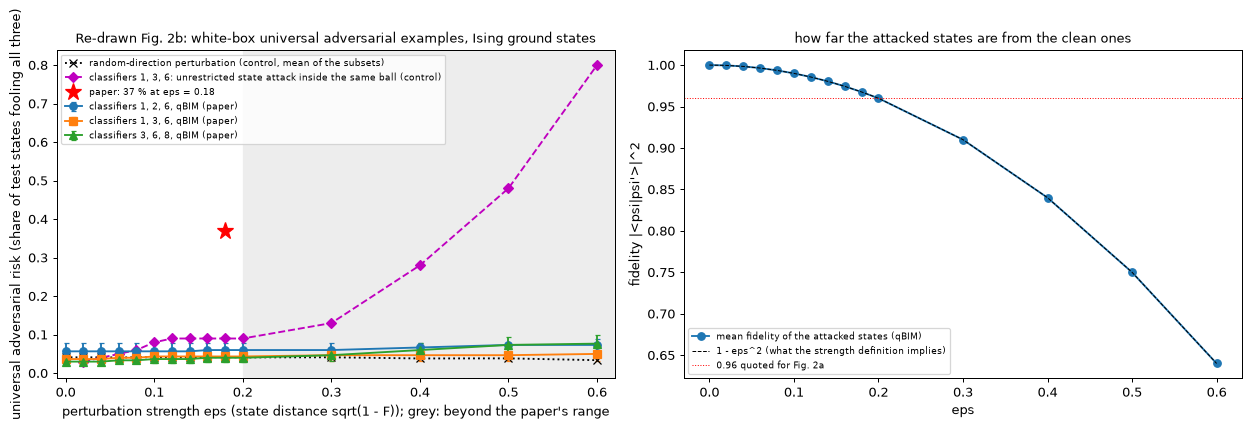

Universal adversarial risk (mean over 3 seed(s)); the attacks took 1500 s


subset,"classifiers 1, 2, 6","classifiers 1, 3, 6","classifiers 3, 6, 8",random-direction control,"unrestricted state attack (1, 3, 6)"
eps,,,,,
0.00,0.057,0.037,0.030,0.041,NaN
0.02,0.057,0.037,0.030,0.041,0.03
0.04,0.057,0.037,0.030,0.041,0.04
0.06,0.057,0.040,0.033,0.041,0.05
0.08,0.057,0.040,0.033,0.041,0.06
0.10,0.057,0.043,0.037,0.042,0.08
0.12,0.057,0.043,0.037,0.041,0.09
0.14,0.057,0.043,0.037,0.041,0.09
0.16,0.060,0.043,0.040,0.041,0.09


per-classifier error rates under the qBIM attack on subset (1, 3, 6), seed 0 (clean error at eps = 0):


,eps,err_each,fidelity,hs_max
15,0.00,"[0.09, 0.03, 0.08]",1.000,0.00
16,0.02,"[0.09, 0.03, 0.08]",1.000,0.02
18,0.04,"[0.09, 0.03, 0.08]",0.998,0.04
20,0.06,"[0.09, 0.03, 0.08]",0.996,0.06
22,0.08,"[0.09, 0.03, 0.08]",0.994,0.08
24,0.10,"[0.09, 0.03, 0.08]",0.990,0.10
26,0.12,"[0.09, 0.03, 0.08]",0.986,0.12
28,0.14,"[0.09, 0.03, 0.08]",0.980,0.14
30,0.16,"[0.09, 0.03, 0.08]",0.974,0.16
32,0.18,"[0.09, 0.03, 0.08]",0.968,0.18


In [24]:
PAPER_ATK = "qBIM, local rotations (paper)"
P = FIG2B[FIG2B.attack == PAPER_ATK]; U = FIG2B[FIG2B.attack != PAPER_ATK]
agg = P.groupby(["subset", "eps"]).agg(risk=("risk", "mean"), risk_sd=("risk", "std"), rnd=("risk_random", "mean"), fid=("fidelity", "mean"), hs_max=("hs_max", "max")).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for (name, d), mk in zip(agg.groupby("subset"), ("o", "s", "^")):
    ax[0].errorbar(d.eps, d.risk, yerr=d.risk_sd.fillna(0), marker=mk, capsize=2, label=name + ", qBIM (paper)")
ax[0].plot(agg.groupby("eps").rnd.mean().index, agg.groupby("eps").rnd.mean().values, "k:", marker="x", label="random-direction perturbation (control, mean of the subsets)")
ax[0].plot(U.eps, U.risk, "m--", marker="D", label="classifiers 1, 3, 6: unrestricted state attack inside the same ball (control)")
ax[0].plot([0.18], [0.37], "r*", ms=14, label="paper: 37 % at eps = 0.18"); ax[0].axvspan(0.2, max(EPS_FIG2B) + 0.02, color="0.93", zorder=0); ax[0].set_xlim(-0.01, max(EPS_FIG2B) + 0.02)
ax[0].set_xlabel("perturbation strength eps (state distance sqrt(1 - F)); grey: beyond the paper's range"); ax[0].set_ylabel("universal adversarial risk (share of test states fooling all three)"); ax[0].set_title("Re-drawn Fig. 2b: white-box universal adversarial examples, Ising ground states", fontsize=10); ax[0].legend(fontsize=7)
d = agg[agg.subset == "classifiers 1, 3, 6"]
ax[1].plot(d.eps, d.fid, "o-", label="mean fidelity of the attacked states (qBIM)"); ax[1].plot(d.eps, 1 - d.eps ** 2, "k--", lw=0.8, label="1 - eps^2 (what the strength definition implies)")
ax[1].set_xlabel("eps"); ax[1].set_ylabel("fidelity |<psi|psi'>|^2"); ax[1].axhline(0.96, color="r", ls=":", lw=0.8, label="0.96 quoted for Fig. 2a"); ax[1].legend(fontsize=7)
ax[1].set_title("how far the attacked states are from the clean ones", fontsize=10)
plt.tight_layout(); plt.show()
tab = agg.pivot(index="eps", columns="subset", values="risk").round(3); tab["random-direction control"] = agg.groupby("eps").rnd.mean().round(3)
tab["unrestricted state attack (1, 3, 6)"] = U.set_index("eps").risk.round(3)
print(f"Universal adversarial risk (mean over {N_SEEDS} seed(s)); the attacks took {T_FIG2B:.0f} s"); display(tab)
print("per-classifier error rates under the qBIM attack on subset (1, 3, 6), seed 0 (clean error at eps = 0):")
display(P[(P.subset == "classifiers 1, 3, 6") & (P.seed == 0)][["eps", "err_each", "fidelity", "hs_max"]].round(3))

In [25]:
# what does a strength eps mean physically for the Ising data? State distance D between the ground states at Jx and at Jx + dJx (L = 8)
dJs = np.round(np.arange(0.0, 2.0001, 0.02), 2); rows = []
for J in (0.5, 1.0, 1.5):
    a = torch.as_tensor(CHAIN8.ground_state(J)[0], dtype=CDT)
    Dj = np.array([float(torch.sqrt(1 - (a.conj() * torch.as_tensor(CHAIN8.ground_state(J + dJ)[0], dtype=CDT)).sum().abs() ** 2)) for dJ in dJs])
    rows.append(dict(Jx=J, **{f"D(dJx = {dJ})": round(float(Dj[int(round(dJ / 0.02))]), 3) for dJ in (0.1, 0.2, 0.4)}, dJx_for_D_0_2=round(float(np.interp(0.2, Dj, dJs)), 2), dJx_for_D_0_4=round(float(np.interp(0.4, Dj, dJs)), 2)))
print("state distance D between neighbouring Ising ground states, and the change of the transverse field dJx that corresponds to a distance of 0.2 / 0.4:"); display(pd.DataFrame(rows))

state distance D between neighbouring Ising ground states, and the change of the transverse field dJx that corresponds to a distance of 0.2 / 0.4:


,Jx,D(dJx = 0.1),D(dJx = 0.2),D(dJx = 0.4),dJx_for_D_0_2,dJx_for_D_0_4
0,0.5,0.134,0.283,0.546,0.14,0.28
1,1.0,0.090,0.161,0.261,0.27,0.93
2,1.5,0.033,0.062,0.108,1.02,2.00


In [26]:
# ---- Fig. 2c: white-box versus hybrid white-box / black-box attack on classifiers 1, 3 and 6 (the attacker knows only ONE classifier of the subset) ----
t0 = time.time(); rows = []; ids = SUBSETS["classifiers 1, 3, 6"]
for s, models in enumerate(ENS["ising"]):
    ms = [models[i] for i in ids]; g = torch.Generator().manual_seed(SEED + 77 * s)
    for eps in EPS_FIG2C:
        deltas = {"white-box (1, 3, 6)": qbim(ms, PSI_TE, Y_TE, eps)}
        for j, nm in zip(range(3), ("classifier 1", "classifier 3", "classifier 6")):
            deltas[f"{nm} known"] = qbim([ms[j]], PSI_TE, Y_TE, eps)
        for mode, delta in deltas.items():
            rows.append(dict(seed=s, mode=mode, eps=eps, risk=risk(ms, PSI_TE, Y_TE, delta), err_each=[round(float(x), 3) for x in wrong_matrix(ms, PSI_TE, Y_TE, delta).float().mean(1)]))
        rows.append(dict(seed=s, mode="random direction (control)", eps=eps, risk=float(np.mean([risk(ms, PSI_TE, Y_TE, random_delta(PSI_TE, eps, g)) for _ in range(N_RANDOM_DRAWS)])), err_each=None))
        if s == 0:                                                       # classical network: crafted for the quantum subset (transfer) and attacked directly (white-box)
            mlp = MLPS["ising"]
            rows.append(dict(seed=s, mode="MLP: perturbation crafted against the 3 quantum models", eps=eps, risk=risk([mlp], PSI_TE, Y_TE, deltas["white-box (1, 3, 6)"]), err_each=None))
            rows.append(dict(seed=s, mode="MLP: own white-box attack", eps=eps, risk=risk([mlp], PSI_TE, Y_TE, qbim([mlp], PSI_TE, Y_TE, eps)), err_each=None))
    print(f"[{time.time() - t0:6.0f}s] seed {s} done", flush=True)
FIG2C = pd.DataFrame(rows); T_FIG2C = time.time() - t0

[   209s] seed 0 done


[   419s] seed 1 done


[   628s] seed 2 done


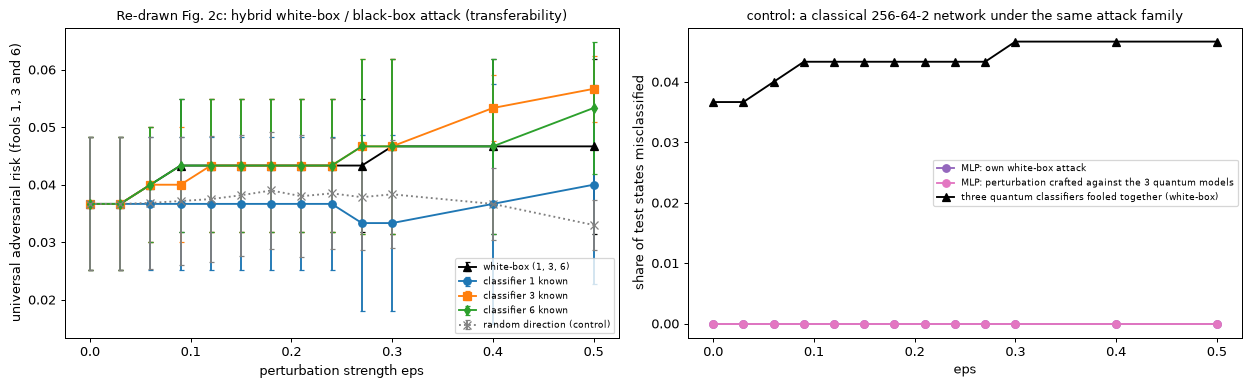

hybrid attack took 628 s


mode,MLP: own white-box attack,MLP: perturbation crafted against the 3 quantum models,classifier 1 known,classifier 3 known,classifier 6 known,random direction (control),"white-box (1, 3, 6)"
eps,,,,,,,
0.00,0.0,0.0,0.037,0.037,0.037,0.037,0.037
0.03,0.0,0.0,0.037,0.037,0.037,0.037,0.037
0.06,0.0,0.0,0.037,0.040,0.040,0.037,0.040
0.09,0.0,0.0,0.037,0.040,0.043,0.037,0.043
0.12,0.0,0.0,0.037,0.043,0.043,0.037,0.043
0.15,0.0,0.0,0.037,0.043,0.043,0.038,0.043
0.18,0.0,0.0,0.037,0.043,0.043,0.039,0.043
0.21,0.0,0.0,0.037,0.043,0.043,0.038,0.043
0.24,0.0,0.0,0.037,0.043,0.043,0.038,0.043


In [27]:
agg = FIG2C.groupby(["mode", "eps"]).risk.agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
sty = {"white-box (1, 3, 6)": ("k", "^-"), "classifier 1 known": ("tab:blue", "o-"), "classifier 3 known": ("tab:orange", "s-"), "classifier 6 known": ("tab:green", "d-"), "random direction (control)": ("grey", "x:")}
for mode, (c, mk) in sty.items():
    d = agg[agg["mode"] == mode]; ax[0].errorbar(d.eps, d["mean"], yerr=d["std"].fillna(0), color=c, fmt=mk, capsize=2, label=mode)
ax[0].set_xlabel("perturbation strength eps"); ax[0].set_ylabel("universal adversarial risk (fools 1, 3 and 6)"); ax[0].set_title("Re-drawn Fig. 2c: hybrid white-box / black-box attack (transferability)", fontsize=10); ax[0].legend(fontsize=7)
for mode, c in (("MLP: own white-box attack", "tab:purple"), ("MLP: perturbation crafted against the 3 quantum models", "tab:pink")):
    d = agg[agg["mode"] == mode]; ax[1].plot(d.eps, d["mean"], "o-", color=c, label=mode)
d = agg[agg["mode"] == "white-box (1, 3, 6)"]; ax[1].plot(d.eps, d["mean"], "k^-", label="three quantum classifiers fooled together (white-box)")
ax[1].set_xlabel("eps"); ax[1].set_ylabel("share of test states misclassified"); ax[1].set_title("control: a classical 256-64-2 network under the same attack family", fontsize=10); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"hybrid attack took {T_FIG2C:.0f} s"); display(agg.pivot(index="eps", columns="mode", values="mean").round(3))

### Universal adversarial examples for images (paper Fig. 2a)

The same experiment on the **amplitude-encoded digits**: for every test image the perturbation is crafted against **all eight MNIST classifiers at once**, and we look for the *smallest* perturbation that fools all eight.
Two attacks are run:

* **qBIM with local rotations (the paper's attack):** qBIM is run with a growing strength bound, at iteration `t` the strength (state distance) is limited to `min(t * alpha, eps_max)`, and the first `t` at which all eight classifiers are fooled is recorded
  (the minimal-perturbation reading of the iterative method; the examples of Fig. 2a "only differ slightly from the legitimate ones").
* **Unrestricted state attack (control):** the perturbed state may be *any* state within the Hilbert-Schmidt ball of radius `eps` (the objects of Definition 2 and Theorem 1), searched on a grid of `eps` values with 20 gradient steps each.
  It tells whether the failure of a local-rotation attack is a property of the classifiers or of the attack family.

The paper's claim to check is the fidelity of such examples with the clean ones, about 96 % (`eps = 0.2`). The images shown are the **magnitudes of the amplitudes** of the attacked state (the perturbed amplitudes are complex).

In [28]:
def progressive_universal_examples(models, psi, y, eps_max, alpha=ALPHA):
    # qBIM with the strength bound growing by alpha per iteration; records, for every input, the angles at the first iteration where ALL models are fooled
    B = psi.shape[0]; steps = int(math.ceil(ITER_FACTOR * eps_max / alpha)) + ITER_EXTRA
    delta = torch.zeros(B, N_PERT, dtype=torch.float64, requires_grad=True)
    first = torch.full((B,), float("inf"), dtype=torch.float64); best = torch.zeros(B, N_PERT, dtype=torch.float64)
    done0 = wrong_matrix(models, psi, y, None).all(0); first[done0] = 0.0
    for t in range(1, steps + 1):
        bound = min(t * alpha, eps_max)
        g, = torch.autograd.grad(sum(ce_loss(m.probs(psi, delta), y) for m in models).sum(), delta)
        with torch.no_grad(): delta = project(delta.detach() + alpha * torch.sign(g), psi, bound, universal=False)
        new = wrong_matrix(models, psi, y, delta).all(0) & torch.isinf(first)
        first[new] = bound; best[new] = delta[new]; delta.requires_grad_()
    return first.numpy(), best, delta.detach()

t0 = time.time()
idx_att = np.concatenate([np.where(MNIST["test"][1] == lab)[0][:MNIST_ATTACK_PER_CLASS] for lab in (0, 1)])
PSI_MN, Y_MN = DS["mnist"]["test"][0][idx_att], DS["mnist"]["test"][1][idx_att]
# (1) the paper's attack
first_q, MN_DELTA_BEST, MN_DELTA_FINAL = progressive_universal_examples(Q_MNIST, PSI_MN, Y_MN, MNIST_EPS_MAX)
F_q = fidelity(PSI_MN, MN_DELTA_BEST).numpy()
print(f"[{time.time() - t0:5.0f}s] qBIM done", flush=True)
# (2) control: unrestricted state attack on a grid of eps; keep the state at the first eps where all eight classifiers are fooled
first_u = np.full(len(Y_MN), np.inf); adv_u = PSI_MN.clone(); fooled_by_one = {}
for eps in MNIST_STATE_GRID:
    adv = state_attack(Q_MNIST, PSI_MN, Y_MN, eps, steps=STATE_STEPS)
    Wm = wrong_matrix(Q_MNIST, adv, Y_MN); alld = Wm.all(0).numpy(); new = alld & np.isinf(first_u)
    first_u[new] = eps; adv_u[torch.as_tensor(new)] = adv[torch.as_tensor(new)]
    fooled_by_one[eps] = [round(float(x), 3) for x in Wm.float().mean(1)]
    if eps == MNIST_STATE_GRID[-1]: adv_u[torch.as_tensor(np.isinf(first_u))] = adv[torch.as_tensor(np.isinf(first_u))]
print(f"[{time.time() - t0:5.0f}s] unrestricted state attack done", flush=True)
F_u = (PSI_MN.conj() * adv_u).sum(1).abs().numpy() ** 2
wrong_clean = wrong_matrix(Q_MNIST, PSI_MN, Y_MN, None).numpy()
g_ = torch.Generator().manual_seed(SEED + 9); grid = [0.1, 0.2, 0.3, MNIST_EPS_MAX]
rand_curve = [float(np.mean([risk(Q_MNIST, PSI_MN, Y_MN, random_delta(PSI_MN, e, g_)) for _ in range(N_RANDOM_DRAWS)])) for e in grid]
d_use = torch.where(torch.isinf(torch.as_tensor(first_q))[:, None], MN_DELTA_FINAL, MN_DELTA_BEST)                  # successful: minimal angles; otherwise the last iterate
mlp_q = risk([MLPS["mnist"]], PSI_MN, Y_MN, d_use); mlp_u = risk([MLPS["mnist"]], adv_u, Y_MN)
MN_EX = dict(first_q=first_q, fid_q=F_q, first_u=first_u, fid_u=F_u, adv_u=adv_u, wrong_clean=wrong_clean, rand_grid=grid, rand_curve=rand_curve, mlp_q=mlp_q, mlp_u=mlp_u,
             one_err=fooled_by_one, y=Y_MN.numpy(), digit=MNIST["test"][2][idx_att], idx=idx_att)
T_MN = time.time() - t0

[   62s] qBIM done


[  437s] unrestricted state attack done


200 test images (100 per digit); clean images already misclassified by all 8 classifiers: 1   (attacks took 490 s)
qBIM with local rotations (paper) fooled all 8 classifiers for 2 of 200 images (1 %) with eps <= 0.4; median eps 0.20, median fidelity 0.920
unrestricted state attack (control) fooled all 8 for 199 of 200 images (100 %) with eps <= 0.7; median eps 0.45 -> median fidelity 0.797 (= 1 - eps^2), 10-90 % range of eps 0.30 - 0.55
single-classifier error rates under the unrestricted attack (columns = classifiers 1-8), by strength:


,classifier 1,classifier 2,classifier 3,classifier 4,classifier 5,classifier 6,classifier 7,classifier 8
eps,,,,,,,,
0.10,0.110,0.085,0.055,0.060,0.055,0.075,0.060,0.050
0.15,0.205,0.135,0.075,0.075,0.080,0.095,0.080,0.085
0.20,0.300,0.215,0.125,0.090,0.115,0.135,0.095,0.130
0.25,0.405,0.330,0.175,0.170,0.160,0.185,0.155,0.185
0.30,0.555,0.495,0.310,0.265,0.245,0.290,0.245,0.290
0.35,0.685,0.670,0.440,0.440,0.445,0.465,0.410,0.470
0.40,0.840,0.820,0.645,0.660,0.615,0.660,0.595,0.615
0.45,0.920,0.945,0.835,0.845,0.845,0.760,0.835,0.760
0.50,0.980,0.995,0.940,0.930,0.960,0.850,0.940,0.885


control: random-direction perturbations of the same strength fool all 8 classifiers for 0 % at eps=0.1, 0 % at eps=0.2, 0 % at eps=0.3, 0 % at eps=0.4
control: a classical 256-64-2 network is misclassified on 1 % of the qBIM-attacked and on 55 % of the unrestricted-attack images (perturbations crafted against the 8 quantum classifiers)


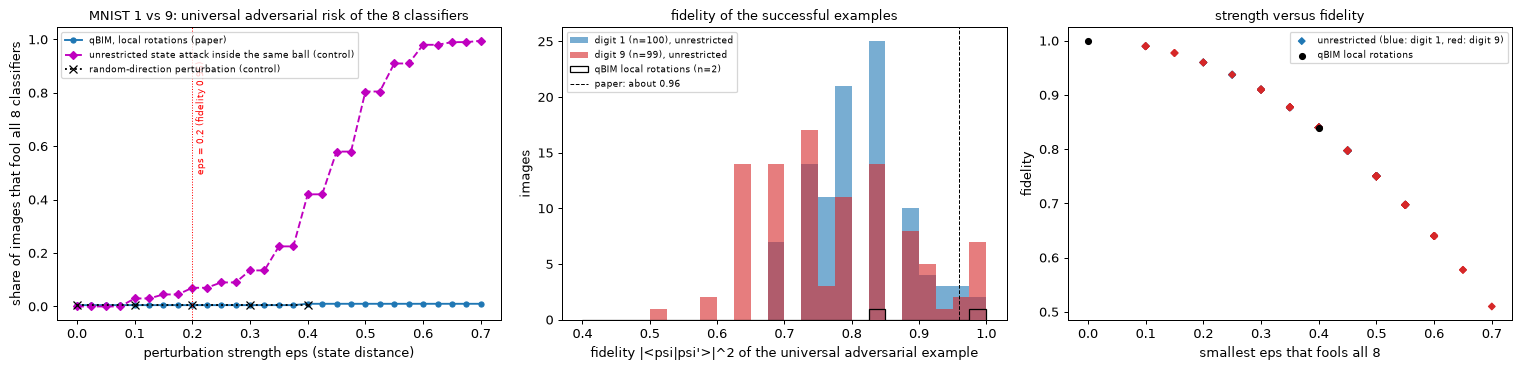

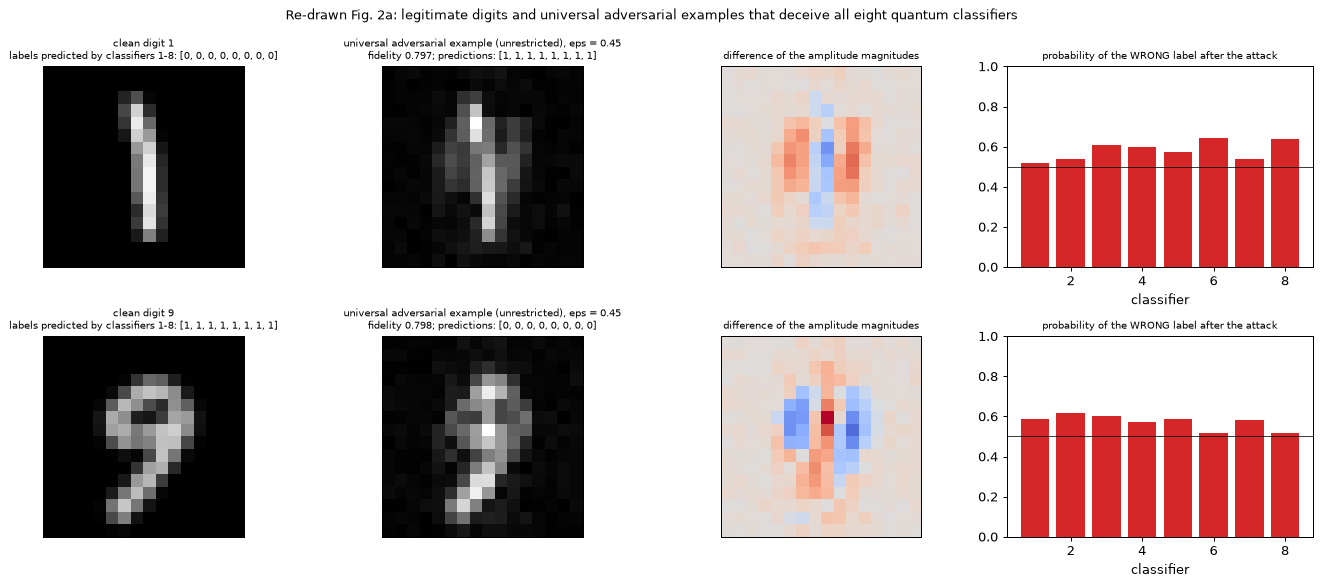

In [29]:
fq, Fq, fu, Fu, ybm = MN_EX["first_q"], MN_EX["fid_q"], MN_EX["first_u"], MN_EX["fid_u"], MN_EX["y"]; okq, oku = np.isfinite(fq), np.isfinite(fu)
print(f"{len(fq)} test images ({MNIST_ATTACK_PER_CLASS} per digit); clean images already misclassified by all 8 classifiers: {int((fq == 0).sum())}   (attacks took {T_MN:.0f} s)")
print(f"qBIM with local rotations (paper) fooled all 8 classifiers for {okq.sum()} of {len(fq)} images ({100 * okq.mean():.0f} %) with eps <= {MNIST_EPS_MAX}"
      + (f"; median eps {np.median(fq[okq]):.2f}, median fidelity {np.median(Fq[okq]):.3f}" if okq.any() else ""))
print(f"unrestricted state attack (control) fooled all 8 for {oku.sum()} of {len(fu)} images ({100 * oku.mean():.0f} %) with eps <= {max(MNIST_STATE_GRID)}"
      + (f"; median eps {np.median(fu[oku]):.2f} -> median fidelity {np.median(Fu[oku]):.3f} (= 1 - eps^2), 10-90 % range of eps {np.percentile(fu[oku], 10):.2f} - {np.percentile(fu[oku], 90):.2f}" if oku.any() else ""))
print("single-classifier error rates under the unrestricted attack (columns = classifiers 1-8), by strength:")
display(pd.DataFrame(MN_EX["one_err"], index=[f"classifier {i}" for i in range(1, 9)]).T.rename_axis("eps"))
print(f"control: random-direction perturbations of the same strength fool all 8 classifiers for {', '.join(f'{100 * r:.0f} % at eps={e}' for e, r in zip(MN_EX['rand_grid'], MN_EX['rand_curve']))}")
print(f"control: a classical 256-64-2 network is misclassified on {100 * MN_EX['mlp_q']:.0f} % of the qBIM-attacked and on {100 * MN_EX['mlp_u']:.0f} % of the unrestricted-attack images (perturbations crafted against the 8 quantum classifiers)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
eg = np.linspace(0, max(MNIST_EPS_MAX, max(MNIST_STATE_GRID)), 29)
ax[0].plot(eg, [(fq <= e + 1e-9).mean() for e in eg], "o-", ms=4, label="qBIM, local rotations (paper)")
ax[0].plot(eg, [(fu <= e + 1e-9).mean() for e in eg], "m--D", ms=4, label="unrestricted state attack inside the same ball (control)")
ax[0].plot([0] + MN_EX["rand_grid"], [(fq == 0).mean()] + MN_EX["rand_curve"], "k:x", label="random-direction perturbation (control)")
ax[0].axvline(0.2, color="r", ls=":", lw=0.8); ax[0].text(0.205, 0.5, "eps = 0.2 (fidelity 0.96)", color="r", fontsize=7, rotation=90)
ax[0].set_xlabel("perturbation strength eps (state distance)"); ax[0].set_ylabel("share of images that fool all 8 classifiers"); ax[0].set_title("MNIST 1 vs 9: universal adversarial risk of the 8 classifiers", fontsize=10); ax[0].legend(fontsize=7)
for lab, col in ((0, "tab:blue"), (1, "tab:red")):
    sel = oku & (ybm == lab); ax[1].hist(Fu[sel], bins=np.linspace(0.4, 1.0, 25), color=col, alpha=0.6, label=f"digit {DIGITS[lab]} (n={sel.sum()}), unrestricted")
if okq.any(): ax[1].hist(Fq[okq], bins=np.linspace(0.4, 1.0, 25), histtype="step", color="k", label=f"qBIM local rotations (n={okq.sum()})")
ax[1].axvline(0.96, color="k", ls="--", lw=0.8, label="paper: about 0.96"); ax[1].set_xlabel("fidelity |<psi|psi'>|^2 of the universal adversarial example"); ax[1].set_ylabel("images"); ax[1].legend(fontsize=7); ax[1].set_title("fidelity of the successful examples", fontsize=10)
ax[2].scatter(fu[oku], Fu[oku], c=np.where(ybm[oku] == 0, "tab:blue", "tab:red"), s=14, marker="D", label="unrestricted (blue: digit 1, red: digit 9)")
if okq.any(): ax[2].scatter(fq[okq], Fq[okq], c="k", s=22, label="qBIM local rotations")
ax[2].set_xlabel("smallest eps that fools all 8"); ax[2].set_ylabel("fidelity"); ax[2].set_title("strength versus fidelity", fontsize=10); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

# example images (one per digit): successful image whose eps is closest to the median (unrestricted attack, else qBIM)
use_u = oku.any(); first_use, ok_use = (fu, oku) if use_u else (fq, okq)
fig, ax = plt.subplots(2, 4, figsize=(15, 6.6))
for r, lab in enumerate((0, 1)):
    cand = np.where(ok_use & (ybm == lab))[0]
    if len(cand) == 0: continue
    i = cand[np.argmin(np.abs(first_use[cand] - np.median(first_use[ok_use])))]
    psi_i = PSI_MN[i:i + 1]; phi_i = MN_EX["adv_u"][i:i + 1] if use_u else apply_local_rot(psi_i, MN_DELTA_BEST[i:i + 1], N_DATA)
    fid_i = float((psi_i.conj() * phi_i).sum().abs() ** 2)
    pr0 = [int(pred_label(m.probs(psi_i))) for m in Q_MNIST]; pr1 = [int(pred_label(m.probs(phi_i))) for m in Q_MNIST]
    clean, adv = psi_i.abs()[0].reshape(16, 16).numpy(), phi_i.abs()[0].reshape(16, 16).numpy(); v = max(clean.max(), adv.max())
    ax[r, 0].imshow(clean, cmap="gray", vmin=0, vmax=v); ax[r, 0].set_title(f"clean digit {DIGITS[lab]}\nlabels predicted by classifiers 1-8: {pr0}", fontsize=8)
    ax[r, 1].imshow(adv, cmap="gray", vmin=0, vmax=v); ax[r, 1].set_title(f"universal adversarial example ({'unrestricted' if use_u else 'qBIM'}), eps = {first_use[i]:.2f}\nfidelity {fid_i:.3f}; predictions: {pr1}", fontsize=8)
    ax[r, 2].imshow(adv - clean, cmap="coolwarm", vmin=-v / 2, vmax=v / 2); ax[r, 2].set_title("difference of the amplitude magnitudes", fontsize=8)
    ax[r, 3].bar(range(1, 9), [float(m.probs(phi_i)[0, 1 - lab]) for m in Q_MNIST], color="tab:red"); ax[r, 3].set_ylim(0, 1); ax[r, 3].axhline(0.5, color="k", lw=0.6)
    ax[r, 3].set_xlabel("classifier"); ax[r, 3].set_title("probability of the WRONG label after the attack", fontsize=8)
    for a in ax[r, :3]: a.set_xticks([]); a.set_yticks([])
plt.suptitle("Re-drawn Fig. 2a: legitimate digits and universal adversarial examples that deceive all eight quantum classifiers", fontsize=10); plt.tight_layout(); plt.show()

## 5. Universal adversarial perturbations (paper Fig. 3)

Now the roles are reversed: **one fixed classifier** and **one fixed unitary perturbation** that is added to *all* inputs. The paper implements it as "an additional variational layer before the original classifier"
whose parameters are optimised by qBIM to maximise the loss over a given set of n samples (Eq. S21): the same 24-angle layer as above, but now **one set of 24 angles shared by every input**
(`qbim(..., universal=True)`, mean loss over the inputs, step 0.02, the operator distance `sqrt(1 - |tr U / d|^2)` of the unitary from the identity limited to `eps`, which is the input-independent strength of a unitary perturbation). The paper's protocol optimises the perturbation on the *test* states and reports the accuracy and the cross-entropy loss on the same states
(Fig. 3b, c: classifier 2 = QCNN and classifier 8 = depth-10 circuit, Ising ground states).

Two points are tested: Theorem 2 says that a *unitary* perturbation cannot change the average risk over the Haar measure (the accuracy settles at a finite value, about 0.5 in the figure), while the *loss*
keeps rising because it is continuous.

**Controls (not in the paper).** (1) *Held-out UAP*: the perturbation is optimised on 100 **training** states and evaluated on the 100 **test** states, which is the real meaning of "universal" (it works on inputs the attacker never saw);
(2) *per-input perturbation*: one perturbation per state with the same strength (the non-universal upper reference); (3) *random direction*: one random sign pattern of the angles, shared by all inputs and scaled to strength eps, averaged over draws;
(4) *the classical 256-64-2 network*: attacked with its own universal perturbation of the same family and strength, and attacked with the perturbation crafted against the quantum classifier (transfer);
(5) *unrestricted universal unitary*: the perturbation is **any** unitary `U = exp(iA)` (a general 256 x 256 Hermitian `A`, so entangling and non-local) of operator distance exactly `eps` from the identity, optimised with Adam on the mean cross entropy, once on the test states (paper protocol) and once on 100 training states (held-out). This is the object that Theorem 2 talks about
and shows whether a perturbation of that strength can lower the accuracy at all, independently of the 24-angle family. **Note on the strength:** the operator distance is an average over the whole 256-dimensional Hilbert space; the Ising and MNIST states occupy a tiny part of it, so a unitary with a small operator distance can still rotate *these* states a lot (the fidelity of the attacked states is reported in the tables).

In [30]:
def uap_eval(model, psi, y, delta):
    with torch.no_grad():
        p = model.probs(psi, delta); pl = pred_label(p)
        return dict(loss=float(ce_loss(p, y).mean()), acc=float((pl == y).float().mean()), frac_pred1=float(pl.float().mean()), fid=float(fidelity(psi, delta).mean()) if delta is not None else 1.0)
PSI_TR, Y_TR = DS["ising"]["train"][0][:100], DS["ising"]["train"][1][:100]          # CHOICE: the held-out UAP is optimised on 100 training states

def states_eval(model, psi, y, phi):
    # same quantities for explicitly given perturbed states phi
    with torch.no_grad():
        p = model.probs(phi); pl = pred_label(p)
        return dict(loss=float(ce_loss(p, y).mean()), acc=float((pl == y).float().mean()), frac_pred1=float(pl.float().mean()), fid=float((psi.conj() * phi).sum(1).abs().pow(2).mean()))

def unitary_scale(lam, eps):
    # largest s <= s_max with sqrt(1 - |mean_j exp(i s lam_j)|^2) <= eps, i.e. operator distance of exp(i s H) from the identity (bisection); lam = eigenvalues of H
    f = lambda s: math.sqrt(max(0.0, 1.0 - abs(np.exp(1j * s * lam).mean()) ** 2))
    lo, hi = 0.0, 3.0 / max(float(np.abs(lam).max()), 1e-9)
    if f(hi) <= eps: return hi
    for _ in range(40):
        mid = 0.5 * (lo + hi); lo, hi = (mid, hi) if f(mid) <= eps else (lo, mid)
    return lo

def universal_unitary_attack(model, psi, y, eps, steps=UNI_STEPS, lr=UNI_LR, seed=0):
    # CONTROL, not in the paper: U = exp(i s H), H a general traceless Hermitian matrix, s chosen after every step so that the operator distance of U from the identity is eps;
    # H is optimised with Adam to maximise the mean cross entropy of `model` on psi. Returns the unitary (d x d).
    d = psi.shape[1]; z = torch.randn(d, d, 2, generator=torch.Generator().manual_seed(seed), dtype=torch.float64)
    G = torch.complex(z[..., 0], z[..., 1]).requires_grad_(); opt = torch.optim.Adam([G], lr=lr); I = torch.eye(d, dtype=CDT)
    def unitary():
        H = (G + G.conj().T) / 2; H = H - (torch.trace(H) / d) * I
        lam, V = torch.linalg.eigh(H); s = unitary_scale(lam.detach().numpy(), eps)
        return (V * torch.exp(1j * s * lam)) @ V.conj().T
    for _ in range(steps):
        loss = -ce_loss(model.probs(psi @ unitary().T), y).mean(); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad(): return unitary()

In [31]:
t0 = time.time(); rows = []
for s, models in enumerate(ENS["ising"]):
    for ci, label in ((1, "classifier 2 (QCNN)"), (7, "classifier 8 (depth 10)")):
        m = models[ci]; g = torch.Generator().manual_seed(SEED + 5 * s + ci)
        for eps in EPS_FIG3:
            d_uap = qbim([m], PSI_TE, Y_TE, eps, universal=True)                     # paper protocol: optimised on the test states themselves
            rows.append(dict(seed=s, clf=label, kind="UAP optimised on the test set (paper protocol)", eps=eps, **uap_eval(m, PSI_TE, Y_TE, d_uap)))
            if s == 0:
                d_held = qbim([m], PSI_TR, Y_TR, eps, universal=True)               # optimised on training states, evaluated on test states
                rows.append(dict(seed=s, clf=label, kind="UAP optimised on 100 training states, evaluated on test", eps=eps, **uap_eval(m, PSI_TE, Y_TE, d_held)))
                d_per = qbim([m], PSI_TE, Y_TE, eps, universal=False)               # one perturbation per state (not universal)
                rows.append(dict(seed=s, clf=label, kind="per-state perturbation (not universal)", eps=eps, **uap_eval(m, PSI_TE, Y_TE, d_per)))
                rr = [uap_eval(m, PSI_TE, Y_TE, random_delta(PSI_TE, eps, g, universal=True)) for _ in range(N_RANDOM_DRAWS)]
                rows.append(dict(seed=s, clf=label, kind="random-direction perturbation (control)", eps=eps, **{k: float(np.mean([r[k] for r in rr])) for k in rr[0]}))
                mlp = MLPS["ising"]
                rows.append(dict(seed=s, clf=label, kind="classical MLP under the same perturbation (transfer)", eps=eps, **uap_eval(mlp, PSI_TE, Y_TE, d_uap)))
                d_mlp = qbim([mlp], PSI_TE, Y_TE, eps, universal=True)
                rows.append(dict(seed=s, clf=label, kind="classical MLP, own UAP (white-box)", eps=eps, **uap_eval(mlp, PSI_TE, Y_TE, d_mlp)))
                rows.append(dict(seed=s, clf=label, kind="quantum classifier under the MLP's UAP (transfer)", eps=eps, **uap_eval(m, PSI_TE, Y_TE, d_mlp)))
                if eps > 0:                                                         # control: any unitary of the same operator distance from the identity
                    U = universal_unitary_attack(m, PSI_TE, Y_TE, eps)
                    rows.append(dict(seed=s, clf=label, kind="unrestricted universal unitary (control)", eps=eps, **states_eval(m, PSI_TE, Y_TE, PSI_TE @ U.T)))
                    U2 = universal_unitary_attack(m, PSI_TR, Y_TR, eps)                    # held-out: optimised on 100 training states, evaluated on the test states
                    rows.append(dict(seed=s, clf=label, kind="unrestricted universal unitary, optimised on 100 training states (held-out)", eps=eps, **states_eval(m, PSI_TE, Y_TE, PSI_TE @ U2.T)))
        print(f"[{time.time() - t0:6.0f}s] seed {s}, {label} done", flush=True)
UAP_RES = pd.DataFrame(rows); T_UAP = time.time() - t0

[   227s] seed 0, classifier 2 (QCNN) done


[   495s] seed 0, classifier 8 (depth 10) done


[   514s] seed 1, classifier 2 (QCNN) done


[   540s] seed 1, classifier 8 (depth 10) done


[   559s] seed 2, classifier 2 (QCNN) done


[   583s] seed 2, classifier 8 (depth 10) done


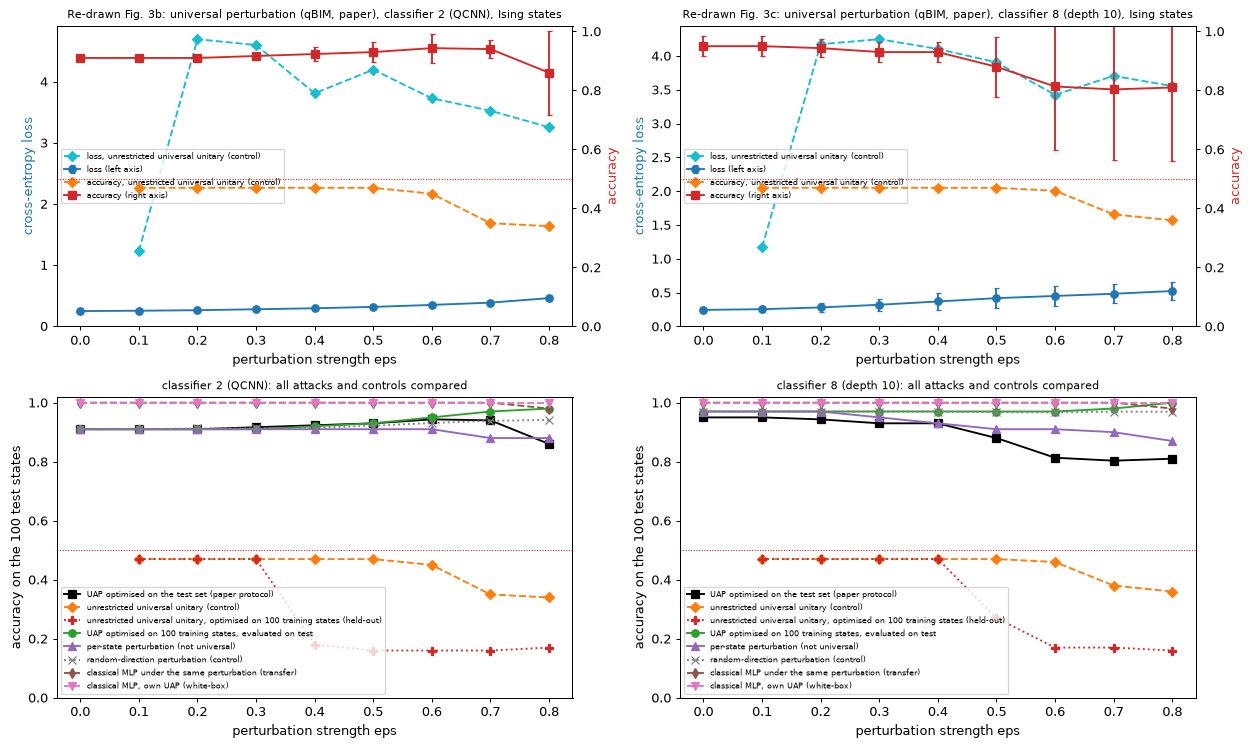

Universal perturbation (paper's qBIM protocol, optimised on the test states) and the unrestricted universal unitary control (mean over 3 seed(s); the control uses the first seed); frac_pred1 = share of test states labelled 1 (0.53 of the test states truly are 1); fid = mean fidelity of the attacked states; took 583 s


acc   loss  frac_pred1    fid
clf                     kind                                           eps                                 
classifier 2 (QCNN)     UAP optimised on the test set (paper protocol) 0.0  0.910  0.247       0.620  1.000
                                                                       0.1  0.910  0.253       0.620  0.991
                                                                       0.2  0.910  0.261       0.620  0.964
                                                                       0.3  0.917  0.277       0.613  0.831
                                                                       0.4  0.923  0.293       0.607  0.737
                                                                       0.5  0.930  0.315       0.600  0.620
                                                                       0.6  0.943  0.348       0.587  0.515
                                                                       0.7  0.940  0.385       0.570  0.409
                                                                       0.8  0.860  0.459       0.470  0.322
                        unrestricted universal unitary (control)       0.1  0.470  1.225       0.000  0.600
                                                                       0.2  0.470  4.696       0.000  0.396
                                                                       0.3  0.470  4.600       0.000  0.360
                                                                       0.4  0.470  3.810       0.000  0.309
                                                                       0.5  0.470  4.197       0.000  0.234
                                                                       0.6  0.450  3.728       0.020  0.131
                                                                       0.7  0.350  3.525       0.120  0.084
                                                                       0.8  0.340  3.254       0.130  0.070
classifier 8 (depth 10) UAP optimised on the test set (paper protocol) 0.0  0.950  0.245       0.580  1.000
                                                                       0.1  0.950  0.256       0.580  0.968
                                                                       0.2  0.943  0.281       0.587  0.878
                                                                       0.3  0.930  0.321       0.600  0.740
                                                                       0.4  0.930  0.370       0.600  0.576
                                                                       0.5  0.880  0.419       0.650  0.407
                                                                       0.6  0.813  0.451       0.717  0.336
                                                                       0.7  0.803  0.484       0.727  0.259
                                                                       0.8  0.810  0.524       0.720  0.190
                        unrestricted universal unitary (control)       0.1  0.470  1.170       0.000  0.585
                                                                       0.2  0.470  4.172       0.000  0.350
                                                                       0.3  0.470  4.247       0.000  0.313
                                                                       0.4  0.470  4.102       0.000  0.273
                                                                       0.5  0.470  3.904       0.000  0.210
                                                                       0.6  0.460  3.424       0.010  0.118
                                                                       0.7  0.380  3.704       0.090  0.044
                                                                       0.8  0.360  3.553       0.110  0.034

In [32]:
main = "UAP optimised on the test set (paper protocol)"; ctrl = "unrestricted universal unitary (control)"
fig, ax = plt.subplots(2, 2, figsize=(14, 8.4))
for c, label in enumerate(("classifier 2 (QCNN)", "classifier 8 (depth 10)")):
    d = UAP_RES[(UAP_RES.clf == label) & (UAP_RES.kind == main)].groupby("eps")[["loss", "acc"]].agg(["mean", "std"])
    a = ax[0, c]; a.errorbar(d.index, d[("loss", "mean")], yerr=d[("loss", "std")].fillna(0), fmt="o-", c="tab:blue", capsize=2, label="loss (left axis)")
    a.set_xlabel("perturbation strength eps"); a.set_ylabel("cross-entropy loss", color="tab:blue"); a.set_title(f"Re-drawn Fig. 3{'b' if c == 0 else 'c'}: universal perturbation (qBIM, paper), {label}, Ising states", fontsize=9)
    b = a.twinx(); b.errorbar(d.index, d[("acc", "mean")], yerr=d[("acc", "std")].fillna(0), fmt="s-", c="tab:red", capsize=2, label="accuracy (right axis)"); b.set_ylim(0, 1.02); b.set_ylabel("accuracy", color="tab:red"); b.axhline(0.5, color="r", ls=":", lw=0.8)
    u = UAP_RES[(UAP_RES.clf == label) & (UAP_RES.kind == ctrl)].sort_values("eps")
    a.plot(u.eps, u.loss, "D--", c="tab:cyan", label="loss, unrestricted universal unitary (control)"); b.plot(u.eps, u.acc, "D--", c="tab:orange", label="accuracy, unrestricted universal unitary (control)")
    h1, l1 = a.get_legend_handles_labels(); h2, l2 = b.get_legend_handles_labels(); a.legend(h1 + h2, l1 + l2, fontsize=6.5, loc="center left")
    a2 = ax[1, c]
    for kind, col, mk in ((main, "k", "s-"), (ctrl, "tab:orange", "D--"), ("unrestricted universal unitary, optimised on 100 training states (held-out)", "tab:red", "P:"), ("UAP optimised on 100 training states, evaluated on test", "tab:green", "o-"), ("per-state perturbation (not universal)", "tab:purple", "^-"),
                          ("random-direction perturbation (control)", "grey", "x:"), ("classical MLP under the same perturbation (transfer)", "tab:brown", "d--"), ("classical MLP, own UAP (white-box)", "tab:pink", "v--")):
        e = UAP_RES[(UAP_RES.clf == label) & (UAP_RES.kind == kind)].groupby("eps").acc.mean(); a2.plot(e.index, e.values, mk, c=col, label=kind)
    a2.set_xlabel("perturbation strength eps"); a2.set_ylabel("accuracy on the 100 test states"); a2.set_ylim(0, 1.02); a2.axhline(0.5, color="r", ls=":", lw=0.8); a2.legend(fontsize=6.5); a2.set_title(f"{label}: all attacks and controls compared", fontsize=9)
plt.tight_layout(); plt.show()
tab = UAP_RES[UAP_RES.kind.isin([main, ctrl])].groupby(["clf", "kind", "eps"])[["acc", "loss", "frac_pred1", "fid"]].mean().round(3)
print(f"Universal perturbation (paper's qBIM protocol, optimised on the test states) and the unrestricted universal unitary control (mean over {N_SEEDS} seed(s); the control uses the first seed); "
      f"frac_pred1 = share of test states labelled 1 (0.53 of the test states truly are 1); fid = mean fidelity of the attacked states; took {T_UAP:.0f} s")
display(tab)

In [33]:
# ---- Fig. 3a: one perturbation for all digits, against classifier 2 (QCNN) on MNIST 1 vs 9 ----
t0 = time.time(); rows, rows_u = [], []; m2 = Q_MNIST[1]; deltas, unitaries = {}, {}
for eps in EPS_FIG3:
    d = qbim([m2], PSI_MN, Y_MN, eps, universal=True); deltas[eps] = d
    rows.append(dict(eps=eps, **uap_eval(m2, PSI_MN, Y_MN, d)))
    if eps > 0:
        U = universal_unitary_attack(m2, PSI_MN, Y_MN, eps); unitaries[eps] = U.numpy()
        rows_u.append(dict(eps=eps, **states_eval(m2, PSI_MN, Y_MN, PSI_MN @ U.T)))
MN_UAP = dict(table=pd.DataFrame(rows), table_u=pd.DataFrame(rows_u), deltas={k: v.numpy() for k, v in deltas.items()}, unitaries=unitaries); T_MN_UAP = time.time() - t0

qBIM with the 24-angle layer (paper):


,eps,loss,acc,frac_pred1,fid
0,0.0,0.395,0.970,0.490,1.000
1,0.1,0.403,0.965,0.485,0.986
2,0.2,0.417,0.965,0.485,0.943
3,0.3,0.438,0.960,0.480,0.874
4,0.4,0.465,0.955,0.465,0.779
5,0.5,0.499,0.950,0.470,0.651
6,0.6,0.565,0.895,0.395,0.495
7,0.7,0.627,0.670,0.230,0.375
8,0.8,0.702,0.415,0.145,0.222


unrestricted universal unitary (control):


,eps,loss,acc,frac_pred1,fid
0,0.1,0.859,0.205,0.305,0.809
1,0.2,1.803,0.070,0.560,0.413
2,0.3,2.449,0.135,0.635,0.262
3,0.4,2.746,0.165,0.665,0.216
4,0.5,2.951,0.190,0.690,0.178
5,0.6,3.062,0.230,0.730,0.142
6,0.7,3.106,0.245,0.745,0.107
7,0.8,3.106,0.250,0.750,0.073


took 158 s


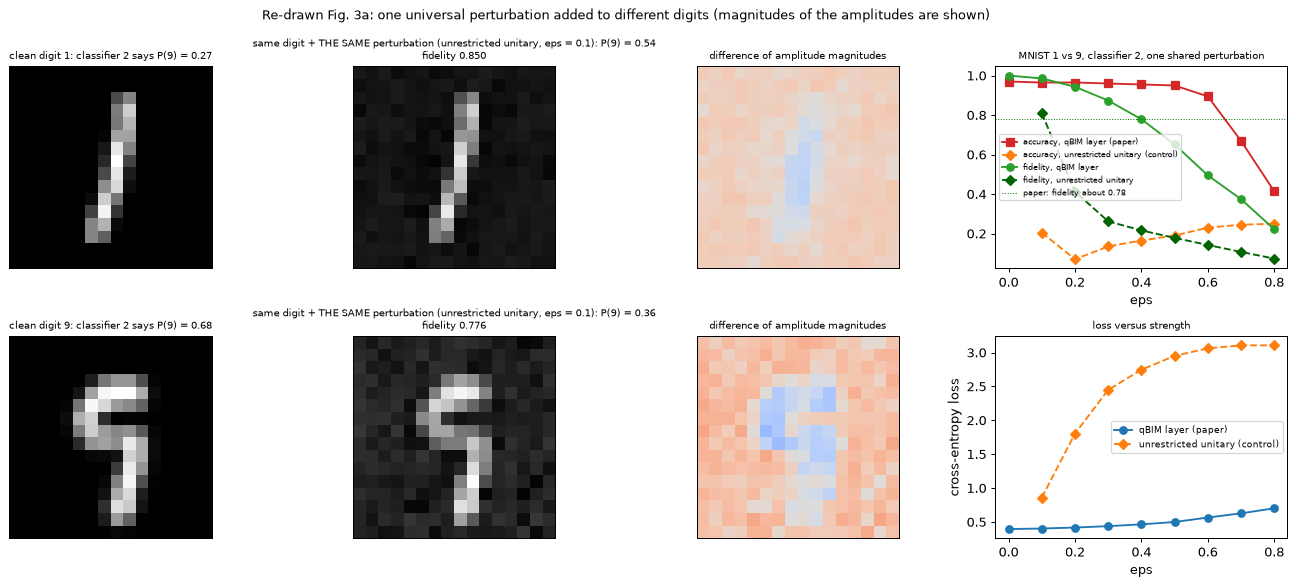

In [34]:
tb, tu = MN_UAP["table"], MN_UAP["table_u"]
print("qBIM with the 24-angle layer (paper):"); display(tb.round(3)); print("unrestricted universal unitary (control):"); display(tu.round(3)); print(f"took {T_MN_UAP:.0f} s")
use_u = (tu.acc.min() < tb.acc.min())                                                  # show the attack that lowers the accuracy most
tab_use = tu if use_u else tb; below = tab_use[tab_use.acc <= 0.5]; e_show = float(below.eps.iloc[0]) if len(below) else float(tab_use.eps.iloc[tab_use.acc.values.argmin()])
m2 = Q_MNIST[1]; phi_all = (PSI_MN @ torch.as_tensor(MN_UAP["unitaries"][e_show]).T) if use_u else apply_local_rot(PSI_MN, torch.as_tensor(MN_UAP["deltas"][e_show]), N_DATA)
fig, ax = plt.subplots(2, 4, figsize=(15, 6.6))
for r, lab in enumerate((0, 1)):
    i = int(np.where(Y_MN.numpy() == lab)[0][0]); psi_i, phi_i = PSI_MN[i:i + 1], phi_all[i:i + 1]
    clean, adv = psi_i.abs()[0].reshape(16, 16).numpy(), phi_i.abs()[0].reshape(16, 16).numpy(); v = max(clean.max(), adv.max())
    p0, p1 = m2.probs(psi_i)[0].detach().numpy(), m2.probs(phi_i)[0].detach().numpy()
    ax[r, 0].imshow(clean, cmap="gray", vmin=0, vmax=v); ax[r, 0].set_title(f"clean digit {DIGITS[lab]}: classifier 2 says P(9) = {p0[1]:.2f}", fontsize=8)
    ax[r, 1].imshow(adv, cmap="gray", vmin=0, vmax=v); ax[r, 1].set_title(f"same digit + THE SAME perturbation ({'unrestricted unitary' if use_u else 'qBIM layer'}, eps = {e_show}): P(9) = {p1[1]:.2f}\nfidelity {float((psi_i.conj() * phi_i).sum().abs() ** 2):.3f}", fontsize=8)
    ax[r, 2].imshow(adv - clean, cmap="coolwarm", vmin=-v / 2, vmax=v / 2); ax[r, 2].set_title("difference of amplitude magnitudes", fontsize=8)
    for a in ax[r, :3]: a.set_xticks([]); a.set_yticks([])
ax[0, 3].plot(tb.eps, tb.acc, "s-", c="tab:red", label="accuracy, qBIM layer (paper)"); ax[0, 3].plot(tu.eps, tu.acc, "D--", c="tab:orange", label="accuracy, unrestricted unitary (control)")
ax[0, 3].plot(tb.eps, tb.fid, "o-", c="tab:green", label="fidelity, qBIM layer"); ax[0, 3].plot(tu.eps, tu.fid, "D--", c="darkgreen", label="fidelity, unrestricted unitary"); ax[0, 3].axhline(0.78, color="g", ls=":", lw=0.8, label="paper: fidelity about 0.78")
ax[0, 3].set_xlabel("eps"); ax[0, 3].legend(fontsize=6); ax[0, 3].set_title("MNIST 1 vs 9, classifier 2, one shared perturbation", fontsize=8)
ax[1, 3].plot(tb.eps, tb.loss, "o-", label="qBIM layer (paper)"); ax[1, 3].plot(tu.eps, tu.loss, "D--", label="unrestricted unitary (control)"); ax[1, 3].set_xlabel("eps"); ax[1, 3].set_ylabel("cross-entropy loss"); ax[1, 3].legend(fontsize=7); ax[1, 3].set_title("loss versus strength", fontsize=8)
plt.suptitle("Re-drawn Fig. 3a: one universal perturbation added to different digits (magnitudes of the amplitudes are shown)", fontsize=10); plt.tight_layout(); plt.show()

## 6. The two theorems, checked numerically

**Theorem 1** (universal adversarial examples). For `k` classifiers on `n` qubits (`d = 2^n`), with `mu_min` the smallest clean error among them (Haar measure), a perturbation of Hilbert-Schmidt size
`eps_HS` guarantees a universal adversarial risk of at least `R0` once

`eps_HS^2 >= (4 / d) * ln( 2 k / (mu_min * (1 - R0)) )`.        (Eq. 1 of the paper, read from the text as `4/d` times the logarithm; the same expression is derived in the Supplement, Eqs. S2 to S9)

Equivalently the guaranteed risk at distance `D` is `R_guar(D) = 1 - (2k / mu_min) * exp(-d D^2 / 4)` (vacuous when negative). We take the distance to be `D = sqrt(1 - F)` (the normalised Hilbert-Schmidt distance of pure states, `F` the fidelity).
Two things can be checked: (a) *how large the guarantee is compared with the risk the attacks reach on the real data*; (b) *scaling*: the required strength should grow like `sqrt(ln k)` with the number of classifiers and shrink like `2^(-n/2)` with the number of qubits.
**What a comparison can and cannot show.** The theorem is a statement about **Haar-random inputs** and an **optimal** adversary. The Ising and MNIST states occupy a tiny corner of Hilbert space, and our attacks (local rotations, or the unrestricted gradient attack with 20 steps) only give a *lower bound* on what an
optimal adversary achieves, so a measured risk *below* the guarantee is **not a contradiction** of the proof; it shows how much of the Haar-measure behaviour carries over to real data (the paper makes the same remark in its discussion: legitimate samples may occupy only a tiny subspace). A measured risk *above* the guarantee is the expected behaviour.
For the scaling experiments the **unrestricted state attack** is used, because it is the closest numerical counterpart of the theorem (perturbed states anywhere in the ball), and the target risk `R0 = 0.25` is chosen so that it is reached at strengths well above the paper's range.

In [35]:
eps_bound = lambda d, k, mu, R0: math.sqrt(4.0 / d * math.log(2.0 * k / (mu * (1.0 - R0))))       # Theorem 1, Eq. (1): sufficient Hilbert-Schmidt distance
r_guar = lambda D, d, k, mu: 1.0 - 2.0 * k / mu * math.exp(-d * D ** 2 / 4.0)                      # guaranteed universal adversarial risk at distance D (may be negative = vacuous)
d8 = 2 ** N_DATA

# (a) consistency with the Fig. 2b attack: guaranteed risk at the largest measured distance versus the risk the attack reached
rows = []
FBt = FIG2B[FIG2B.attack == "qBIM, local rotations (paper)"]
clean = FBt[FBt.eps == 0].groupby("subset").err_each.apply(lambda s: np.min([min(e) for e in s]))
for name in SUBSETS:
    mu = max(float(clean[name]), 1.0 / len(Y_TE))                                   # smallest clean error among the three (floored at one test state)
    for atk, dd in FIG2B[FIG2B.subset == name].groupby("attack"):
        for _, r in dd.groupby("eps").agg(risk=("risk", "mean"), hs=("hs_max", "max")).reset_index().iterrows():
            rows.append(dict(attack=atk, subset=name, eps=r.eps, hs_max=r.hs, mu_min=mu, risk_attack=r.risk, risk_guaranteed=r_guar(r.hs, d8, 3, mu)))
T1A = pd.DataFrame(rows); T1A["consistent"] = T1A.risk_attack >= T1A.risk_guaranteed - 1e-9
display(T1A[T1A.eps.isin([0.0, EPS_FIG2B[len(EPS_FIG2B) // 2], max(EPS_FIG2B)])].round(3))
print(f"guaranteed risk is vacuous (negative) in {int((T1A.risk_guaranteed <= 0).sum())} of {len(T1A)} (attack, subset, eps) points; where it is positive the attack is at or above it in {int(T1A[T1A.risk_guaranteed > 0].consistent.sum())} of {int((T1A.risk_guaranteed > 0).sum())}")
print("largest guaranteed risk:", round(float(T1A.risk_guaranteed.max()), 3), "| distance needed by Eq. (1) for R0 = 0.3 / 0.5 / 0.9 with k = 3, mu_min = 0.05, d = 256:",
      [round(eps_bound(d8, 3, 0.05, R0), 3) for R0 in (0.3, 0.5, 0.9)], "| largest distance the attack used:", round(float(T1A.hs_max.max()), 3))

,attack,subset,eps,hs_max,mu_min,risk_attack,risk_guaranteed,consistent
0,"qBIM, local rotations (paper)","classifiers 1, 2, 6",0.00,0.00,0.04,0.057,-149.000,True
7,"qBIM, local rotations (paper)","classifiers 1, 2, 6",0.14,0.14,0.04,0.057,-41.787,True
14,"qBIM, local rotations (paper)","classifiers 1, 2, 6",0.60,0.60,0.04,0.073,1.000,False
15,"qBIM, local rotations (paper)","classifiers 1, 3, 6",0.00,0.00,0.03,0.037,-199.000,True
22,"qBIM, local rotations (paper)","classifiers 1, 3, 6",0.14,0.14,0.03,0.043,-56.049,True
29,"qBIM, local rotations (paper)","classifiers 1, 3, 6",0.60,0.60,0.03,0.050,1.000,False
36,unrestricted state attack (control),"classifiers 1, 3, 6",0.14,0.14,0.03,0.090,-56.049,True
43,unrestricted state attack (control),"classifiers 1, 3, 6",0.60,0.60,0.03,0.800,1.000,False
44,"qBIM, local rotations (paper)","classifiers 3, 6, 8",0.00,0.00,0.03,0.030,-199.000,True
51,"qBIM, local rotations (paper)","classifiers 3, 6, 8",0.14,0.14,0.03,0.037,-56.049,True


guaranteed risk is vacuous (negative) in 43 of 59 (attack, subset, eps) points; where it is positive the attack is at or above it in 0 of 16
largest guaranteed risk: 1.0 | distance needed by Eq. (1) for R0 = 0.3 / 0.5 / 0.9 with k = 3, mu_min = 0.05, d = 256: [0.284, 0.293, 0.333] | largest distance the attack used: 0.6


In [36]:
# (b) scaling: (i) with the number of classifiers k (nested sets of the eight Ising classifiers, white-box joint attack), (ii) with the number of qubits n (new classifiers on shorter chains);
# both with the unrestricted state attack (a control of this notebook), because Theorem 1 is about arbitrary perturbed states in the Hilbert-Schmidt ball
t0 = time.time(); R0_SCAL = 0.25
K_ORDER = [5, 7, 2, 0, 1, 3, 4, 6]                                                   # CHOICE: classifiers added one by one (6, 8, 3, 1, 2, 4, 5, 7 in the paper's numbering)
rows = []
for k in K_LIST:
    ms = [Q_ISING[i] for i in K_ORDER[:k]]
    for eps in EPS_SCAL:
        adv = state_attack(ms, PSI_TE, Y_TE, eps)                                  # unrestricted attack inside the ball: distance = eps exactly
        rows.append(dict(k=k, eps=eps, risk=float(wrong_matrix(ms, adv, Y_TE).all(0).float().mean())))
T1_K = pd.DataFrame(rows); print(f"[{time.time() - t0:5.0f}s] k-scaling done", flush=True)

rows = []
for L_ in sorted(CHAINS):
    dat = CHAINS[L_]["data"]; data_t = {k: (to_t(dat[k][0]), torch.as_tensor(dat[k][1])) for k in ("train", "val", "test")}
    if L_ == N_DATA: ms = [Q_ISING[i] for i in (2, 3, 4)]                          # the depth-5/6/7 classifiers already trained on L = 8
    else:
        ms = []
        for j, depth in enumerate((5, 6, 7)):
            c = build_vc(depth, n_data=L_); th, _ = train_classifier(c, data_t, EPOCHS, ISING_ITS["vc"], ISING_BS["vc"], LR["vc"], seed=SEED + 100 * L_ + j); ms.append(QModel(c, th))
    psi, y = data_t["test"]
    acc = [evaluate(m, psi, y)[1] for m in ms]; mu = max(1 - max(acc), 1.0 / len(y))
    for eps in EPS_SCAL:
        adv = state_attack(ms, psi, y, eps)
        rows.append(dict(L=L_, eps=eps, risk=float(wrong_matrix(ms, adv, y).all(0).float().mean()), mu_min=mu, clean_acc=float(np.mean(acc))))
    print(f"[{time.time() - t0:5.0f}s] L = {L_} done (clean test accuracy of the three classifiers {np.round(acc, 2).tolist()})", flush=True)
T1_N = pd.DataFrame(rows); T_SCAL = time.time() - t0

[  146s] k-scaling done


[  149s] L = 4 done (clean test accuracy of the three classifiers [0.97, 0.95, 0.94])


[  155s] L = 5 done (clean test accuracy of the three classifiers [0.9, 0.9, 0.91])


[  163s] L = 6 done (clean test accuracy of the three classifiers [0.97, 0.97, 0.95])


[  178s] L = 7 done (clean test accuracy of the three classifiers [0.87, 0.88, 0.93])


[  202s] L = 8 done (clean test accuracy of the three classifiers [0.97, 0.95, 0.98])


Strength needed for a universal adversarial risk of R0 = 0.25 against the first k classifiers (L = 8, unrestricted attack); Eq. (1) predicts growth with sqrt(ln k) only:


,k,eps_for_R0,Eq.(1) distance,Eq.(1) relative to k=1,measured relative to k=1
0,1,0.314,0.276,1.000,1.000
1,2,0.361,0.295,1.068,1.149
2,4,0.380,0.313,1.133,1.209
3,8,0.413,0.330,1.194,1.314


Strength needed for R0 = 0.25 against three depth-5/6/7 classifiers on Ising chains of n qubits (unrestricted attack); Eq. (1) predicts a fall like 2^(-n/2):


,qubits n,eps_for_R0,mu_min,clean_test_acc,Eq.(1) distance (k=3)
0,4,0.219,0.03,0.953,1.182
1,5,0.175,0.09,0.903,0.749
2,6,0.260,0.03,0.963,0.591
3,7,0.288,0.07,0.893,0.385
4,8,0.341,0.02,0.967,0.306


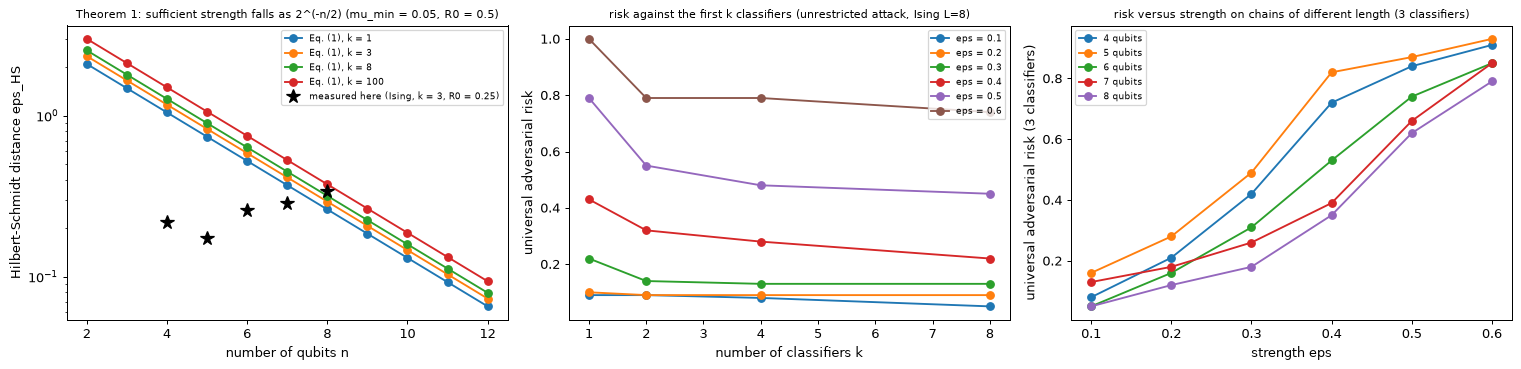

scaling experiments took 202 s


In [37]:
def first_reach(df, xcol, R0):
    # smallest value of xcol (interpolated linearly between grid points) at which the attack's risk reaches R0; nan if never
    df = df.sort_values(xcol); x, r = df[xcol].values, df.risk.values
    if r.max() < R0: return float("nan")
    j = int(np.argmax(r >= R0))
    return float(x[j]) if j == 0 else float(x[j - 1] + (R0 - r[j - 1]) / (r[j] - r[j - 1]) * (x[j] - x[j - 1]))

# (i) number of classifiers
TK = pd.DataFrame([(k, first_reach(T1_K[T1_K.k == k], "eps", R0_SCAL)) for k in K_LIST], columns=["k", "eps_for_R0"])
mu8 = max(1 - float(np.max([evaluate(Q_ISING[i], PSI_TE, Y_TE)[1] for i in K_ORDER])), 1.0 / len(Y_TE))
TK["Eq.(1) distance"] = [eps_bound(d8, k, mu8, R0_SCAL) for k in K_LIST]
TK["Eq.(1) relative to k=1"] = TK["Eq.(1) distance"] / TK["Eq.(1) distance"].iloc[0]
TK["measured relative to k=1"] = TK.eps_for_R0 / TK.eps_for_R0.iloc[0]
print(f"Strength needed for a universal adversarial risk of R0 = {R0_SCAL} against the first k classifiers (L = 8, unrestricted attack); Eq. (1) predicts growth with sqrt(ln k) only:")
display(TK.round(3))

# (ii) number of qubits
TN = pd.DataFrame([(L_, first_reach(T1_N[T1_N.L == L_], "eps", R0_SCAL), float(T1_N[T1_N.L == L_].mu_min.iloc[0]), float(T1_N[T1_N.L == L_].clean_acc.iloc[0]))
                   for L_ in sorted(CHAINS)], columns=["qubits n", "eps_for_R0", "mu_min", "clean_test_acc"])
TN["Eq.(1) distance (k=3)"] = [eps_bound(2 ** n_, 3, mu_, R0_SCAL) for n_, mu_ in zip(TN["qubits n"], TN.mu_min)]
print(f"Strength needed for R0 = {R0_SCAL} against three depth-5/6/7 classifiers on Ising chains of n qubits (unrestricted attack); Eq. (1) predicts a fall like 2^(-n/2):")
display(TN.round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
nn = np.arange(2, 13)
for k_ in (1, 3, 8, 100): ax[0].semilogy(nn, [eps_bound(2 ** n_, k_, 0.05, 0.5) for n_ in nn], "o-", label=f"Eq. (1), k = {k_}")
ax[0].plot(TN["qubits n"], TN.eps_for_R0, "k*", ms=11, label="measured here (Ising, k = 3, R0 = 0.25)")
ax[0].set_xlabel("number of qubits n"); ax[0].set_ylabel("Hilbert-Schmidt distance eps_HS"); ax[0].set_title("Theorem 1: sufficient strength falls as 2^(-n/2) (mu_min = 0.05, R0 = 0.5)", fontsize=9); ax[0].legend(fontsize=7)
for eps, d in T1_K.groupby("eps"): ax[1].plot(d.k, d.risk, "o-", label=f"eps = {eps}")
ax[1].set_xlabel("number of classifiers k"); ax[1].set_ylabel("universal adversarial risk"); ax[1].set_title("risk against the first k classifiers (unrestricted attack, Ising L=8)", fontsize=9); ax[1].legend(fontsize=7)
for L_, d in T1_N.groupby("L"): ax[2].plot(d.eps, d.risk, "o-", label=f"{L_} qubits")
ax[2].set_xlabel("strength eps"); ax[2].set_ylabel("universal adversarial risk (3 classifiers)"); ax[2].set_title("risk versus strength on chains of different length (3 classifiers)", fontsize=9); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"scaling experiments took {T_SCAL:.0f} s")

In [38]:
# ---- Theorem 2, first part: Hoeffding bound  |R_E - mu(E)| <= sqrt(ln(2/delta) / (2 n))  for n inputs of the perturbed classifier ----
t0 = time.time(); g = np.random.default_rng(SEED + 401)
J_pool = g.uniform(0, 2, HOEFFDING_POOL); X_pool = to_t(CHAIN8.states(J_pool)); y_pool = torch.as_tensor((J_pool >= 1).astype(np.int64))         # fresh states, never used for training or attacking
rows = []; n_s = 100
for ci, label in ((1, "classifier 2 (QCNN)"), (7, "classifier 8 (depth 10)")):
    m = Q_ISING[ci]; d_star = qbim([m], PSI_TE, Y_TE, 0.4, universal=True)                    # one fixed unitary perturbation (the universal perturbation at eps = 0.4)
    with torch.no_grad(): err_pool = (pred_label(m.probs(X_pool, d_star)) != y_pool).numpy().astype(float)
    mu = err_pool.mean()                                                                       # mu(E) of the perturbed classifier on the data distribution (large pool)
    draws = np.array([err_pool[g.choice(len(err_pool), n_s, replace=False)].mean() for _ in range(HOEFFDING_DRAWS)])
    for delta_ in (0.05, 0.10, 0.50):
        bound = math.sqrt(math.log(2 / delta_) / (2 * n_s))
        rows.append(dict(classifier=label, mu_E=mu, n=n_s, delta=delta_, hoeffding_bound=bound, coverage=float((np.abs(draws - mu) <= bound).mean()), required=1 - delta_, mean_abs_dev=float(np.abs(draws - mu).mean()), max_abs_dev=float(np.abs(draws - mu).max())))
HOEF = pd.DataFrame(rows); T_HOEF = time.time() - t0

In [39]:
display(HOEF.round(3))
print(f"A pool of {HOEFFDING_POOL} fresh ground states estimates mu(E); {HOEFFDING_DRAWS} random test sets of n = 100 states per classifier ({T_HOEF:.0f} s). Hoeffding is satisfied if coverage >= 1 - delta in every row: {bool((HOEF.coverage >= HOEF.required).all())}")

,classifier,mu_E,n,delta,hoeffding_bound,coverage,required,mean_abs_dev,max_abs_dev
0,classifier 2 (QCNN),0.10,100,0.05,0.136,1.000,0.95,0.023,0.09
1,classifier 2 (QCNN),0.10,100,0.10,0.122,1.000,0.90,0.023,0.09
2,classifier 2 (QCNN),0.10,100,0.50,0.083,0.999,0.50,0.023,0.09
3,classifier 8 (depth 10),0.06,100,0.05,0.136,1.000,0.95,0.018,0.09
4,classifier 8 (depth 10),0.06,100,0.10,0.122,1.000,0.90,0.018,0.09
5,classifier 8 (depth 10),0.06,100,0.50,0.083,1.000,0.50,0.018,0.09


A pool of 4000 fresh ground states estimates mu(E); 2000 random test sets of n = 100 states per classifier (16 s). Hoeffding is satisfied if coverage >= 1 - delta in every row: True


**Theorem 2, second part (Eq. 4, the no-free-lunch lower bound).** The theorem states that averaged over ground-truth functions `t` and training sets of size `N`, the risk of *any* quantum classifier with `d' = 2` labels satisfies

`E_t E_S [ mu(E) ] >= 1 - d' (N^2 + d + 1) / (d (d + 1))`      (Eq. 4, as printed in the text and in Eq. S16 of the Supplement)

with `d = 2^n`. For small `N` and large `d` the right-hand side approaches 1, i.e. *every* classifier would be wrong almost always. That cannot hold for a binary classifier, because a classifier that ignores the input and
answers 0 or 1 at random is right half of the time on average over balanced ground truths. The cell below tests it with a Monte-Carlo experiment that follows the theorem's setting: Haar-random input states,
a **Haar-random ground-truth unitary** `T` (label = the measured value of qubit 0 of `T|psi>`), `N` random training states, a trained variational classifier (depth 3, Adam, cross entropy) and the true error `mu(E)` on 300 fresh Haar states,
averaged over many draws of `T`.

In [40]:
t0 = time.time(); g = torch.Generator().manual_seed(SEED + 555)
def haar_states(nq, n):
    z = torch.randn(n, 2 ** nq, 2, generator=g, dtype=torch.float64); z = torch.complex(z[..., 0], z[..., 1]); return z / z.norm(dim=1, keepdim=True)
def haar_unitary(d):
    z = torch.randn(d, d, 2, generator=g, dtype=torch.float64); q, r = torch.linalg.qr(torch.complex(z[..., 0], z[..., 1])); return q * (torch.diagonal(r) / torch.diagonal(r).abs())
def true_label(T, psi, nq):
    out = (psi @ T.T).reshape(len(psi), 2, 2 ** (nq - 1))                                                       # T|psi>, first axis = most significant qubit
    return ((out[:, 1, :].abs() ** 2).sum(1) > 0.5).long()                                                      # label = that qubit measured as 1 with probability > 1/2
rows = []
for nq in NFL_QUBITS:
    d = 2 ** nq; circ = build_vc(3, n_data=nq)
    for N in NFL_TRAIN_SIZES:
        errs, errs_nn = [], []
        for draw in range(NFL_DRAWS):
            T = haar_unitary(d); Xtr = haar_states(nq, N); ytr = true_label(T, Xtr, nq); Xte = haar_states(nq, 300); yte = true_label(T, Xte, nq)
            th = (torch.randn(circ.n_params, generator=g, dtype=torch.float64) * INIT_STD).requires_grad_(); opt = torch.optim.Adam([th], lr=0.1)
            for _ in range(60):
                loss = ce_loss(circ.probs(Xtr, th), ytr).mean(); opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad(): errs.append(float((pred_label(circ.probs(Xte, th)) != yte).float().mean()))
            nn_idx = (Xte @ Xtr.conj().T).abs().argmax(1); errs_nn.append(float((ytr[nn_idx] != yte).float().mean()))      # a trivial learner: label of the most similar training state
        bound = 1 - 2 * (N ** 2 + d + 1) / (d * (d + 1))
        rows.append(dict(qubits=nq, d=d, N=N, mean_risk_trained_circuit=np.mean(errs), sd=np.std(errs), mean_risk_nearest_state=np.mean(errs_nn), eq4_lower_bound=bound, chance_level=0.5))
NFL = pd.DataFrame(rows); T_NFL = time.time() - t0

In [41]:
display(NFL.round(3))
viol = NFL[NFL.eq4_lower_bound > NFL.mean_risk_trained_circuit + 2 * NFL.sd / np.sqrt(NFL_DRAWS)]
print(f"{NFL_DRAWS} random ground truths per row ({T_NFL:.0f} s). Eq. (4) is above the measured mean risk (by more than two standard errors) in {len(viol)} of {len(NFL)} settings; "
      f"the measured risk stays near the chance level 0.5, as it must for a balanced binary problem, while the printed bound goes to 1 for small N and large d.")

,qubits,d,N,mean_risk_trained_circuit,sd,mean_risk_nearest_state,eq4_lower_bound,chance_level
0,3,8,2,0.493,0.060,0.474,0.639,0.5
1,3,8,8,0.438,0.039,0.433,-1.028,0.5
2,4,16,2,0.493,0.028,0.495,0.846,0.5
3,4,16,8,0.482,0.040,0.460,0.404,0.5
4,5,32,2,0.505,0.028,0.498,0.930,0.5
5,5,32,8,0.487,0.025,0.482,0.816,0.5
6,6,64,2,0.498,0.025,0.496,0.967,0.5
7,6,64,8,0.511,0.029,0.502,0.938,0.5


20 random ground truths per row (37 s). Eq. (4) is above the measured mean risk (by more than two standard errors) in 6 of 8 settings; the measured risk stays near the chance level 0.5, as it must for a balanced binary problem, while the printed bound goes to 1 for small N and large d.


## 7. The paper's claims next to this notebook's numbers

Every claim that the paper states with a number or a clear qualitative statement gets one verdict: **reproduced** (within the tolerance of 0.02 / 2 points, or the stated qualitative behaviour is observed),
**not reached here** / **exceeded here** (with the gap), or **cannot be checked** (the paper gives only a plot without printed values, or the quantity is not defined in the text).
Where the paper prints no number (the curves of Figs. 2 and 3), the verdict tests the statements made in the text about them. Differences in absolute values are expected: the paper's circuits, learning rates, data subsets, the meaning of
"perturbation strength" and the Hamiltonian size are partly unspecified and are choices of this notebook (see the table above).

**How to read the verdicts.** The tolerance is 0.02 (two points) for every number the paper prints; rows 2.x are the eight accuracies of Table S1. For claims about how *strong* an attack is, a lower accuracy (or a higher risk) than the paper's is reported as
"exceeded here" even though the number is smaller. Where the paper's own attack (qBIM with local rotations) fails but a control attack succeeds, the row says so in the "this notebook" column and the verdict follows the rule stated in the claim (for the existence claims, the best attack counts, for the quantitative ones the paper's attack and the control are both shown).
Every statement about an attack not working means: **not reached with these attacks**; attacks give lower bounds on what an optimal adversary can do.

In [42]:
claims = []
def add(cid, source, claim, paper, here, verdict): claims.append({"#": cid, "where": source, "claim": claim, "paper": paper, "this notebook": here, "verdict": verdict})
def vnum(paper, here, tol=TOL, up="exceeded here", down="not reached here"):
    return "reproduced" if abs(paper - here) <= tol + 1e-12 else (up if here > paper else down)
def r2_linear(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float); A = np.vstack([x, np.ones_like(x)]).T; coef, res, *_ = np.linalg.lstsq(A, y, rcond=None)
    ss = ((y - y.mean()) ** 2).sum(); return (1.0 - ((y - A @ coef) ** 2).sum() / ss if ss > 1e-12 else float("nan")), coef[0]       # R^2 is undefined (nan) for a flat curve

# 1. parameter counts (Table S1)
add(1, "Table S1", "parameter counts of the 8 classifiers", str(PAPER_PARAMS), str([a.n_params for a in ARCHS]), "reproduced" if [a.n_params for a in ARCHS] == PAPER_PARAMS else "not reached here")
# 2. accuracies (Table S1), Ising, over the 300 training states
for i, c in enumerate(ARCHS):
    pa = TABLE_S1.paper_accuracy[i]; here = float(ACC_ISING[:, i, 0].mean())
    add(f"2.{i + 1}", "Table S1", f"accuracy of classifier {i + 1} ({c.name}) on the 300 training states", f"{pa:.3f}", f"{here:.3f}", vnum(pa, here))
# 3. five of 100 test states misclassified by all eight classifiers without perturbation
n_all = int(wrong_matrix(Q_ISING, PSI_TE, Y_TE).all(0).sum())
add(3, "Suppl. A", "test states (of 100) misclassified by all eight classifiers without perturbation", "5", str(n_all), vnum(5, n_all, tol=2))
# 4. Fig. 2b: 37 % at eps = 0.18
FB = FIG2B[FIG2B.attack == "qBIM, local rotations (paper)"]; FU = FIG2B[FIG2B.attack != "qBIM, local rotations (paper)"]
r18 = FB[np.isclose(FB.eps, 0.18)].groupby("subset").risk.mean()
add(4, "Fig. 2b", "universal adversarial risk at eps = 0.18 (mean of the three subsets)", "0.37 for each subset", f"{r18.mean():.3f} (" + ", ".join(f"{v:.2f}" for v in r18.values) + ")", vnum(0.37, float(r18.mean())))
# 5. roughly linear in eps
ag = FB[FB.eps <= 0.2 + 1e-9].groupby(["subset", "eps"]).risk.mean().reset_index(); lin = {n: r2_linear(d.eps, d.risk) for n, d in ag.groupby("subset")}
add(5, "Fig. 2b", "the universal adversarial risk increases roughly linearly with eps", "linear (qualitative)", "R^2 / slope of a line over eps <= 0.2: " + ", ".join(f"{v[0]:.2f} / {v[1]:.2f}" for v in lin.values()), "reproduced" if all(v[0] >= 0.9 and v[1] > 0 for v in lin.values()) else "not reached here")
# 6. universal examples exist for every subset, regardless of structure (above clean level and above the random-direction control)
gaps = {n: (float(d[d.eps == d.eps.max()].risk.iloc[0] - d[d.eps == 0].risk.iloc[0])) for n, d in ag.groupby("subset")}
rnd = FB.groupby(["subset", "eps"]).risk_random.mean().reset_index(); gaps_r = {n: float(d[d.eps == d.eps.max()].risk.iloc[0] - rnd[(rnd.subset == n) & (rnd.eps == d.eps.max())].risk_random.iloc[0]) for n, d in ag.groupby("subset")}
add(6, "Fig. 2b", "universal adversarial examples exist for every subset (risk rises >= 0.10 above the clean level and above the random-direction control)", "exist for all subsets", "rise over clean: " + ", ".join(f"{v:.2f}" for v in gaps.values()) + "; over random: " + ", ".join(f"{v:.2f}" for v in gaps_r.values()),
    "reproduced" if min(gaps.values()) >= 0.10 and min(gaps_r.values()) >= 0.10 else "not reached here")
# 7. hybrid attack: smaller than white-box but clearly above the clean level
ag2 = FIG2C.groupby(["mode", "eps"]).risk.mean().reset_index(); em = max(e for e in EPS_FIG2C if e <= 0.3 + 1e-9); get = lambda m, e: float(ag2[(ag2["mode"] == m) & np.isclose(ag2.eps, e)].risk.iloc[0])
wb, cl = get("white-box (1, 3, 6)", em), get("white-box (1, 3, 6)", 0.0)
bb = {m: get(m, em) for m in ("classifier 1 known", "classifier 3 known", "classifier 6 known")}
add(7, "Fig. 2c", "with only one classifier known the attack still works (above clean level) but is weaker than white-box", "bb < wb, bb > 0 (transferable)", f"eps={em}: white-box {wb:.2f}; known 1/3/6: " + "/".join(f"{v:.2f}" for v in bb.values()) + f"; clean {cl:.2f}",
    "reproduced" if all((v < wb) and (v > cl + TOL) for v in bb.values()) else "not reached here")
# 8. hybrid curves also linear
lin2 = {m: r2_linear(ag2[(ag2["mode"] == m) & (ag2.eps <= 0.3 + 1e-9)].eps, ag2[(ag2["mode"] == m) & (ag2.eps <= 0.3 + 1e-9)].risk) for m in bb}
add(8, "Fig. 2c", "the black-box risk also increases linearly with eps", "linear (qualitative)", "R^2 / slope over eps <= 0.3: " + ", ".join(f"{v[0]:.2f} / {v[1]:.2f}" for v in lin2.values()), "reproduced" if all(v[0] >= 0.9 and v[1] > 0 for v in lin2.values()) else "not reached here")
# 9-10. Fig. 2a (MNIST)
fq, Fq, fu, Fu = MN_EX["first_q"], MN_EX["fid_q"], MN_EX["first_u"], MN_EX["fid_u"]; okq, oku = np.isfinite(fq), np.isfinite(fu)
medq = float(np.median(Fq[okq])) if okq.any() else float("nan"); medu = float(np.median(Fu[oku])) if oku.any() else float("nan")
best = max([v for v, ok_ in ((medq, okq), (medu, oku)) if v == v and ok_.mean() >= 0.5], default=float("nan"))      # only an attack that works on at least half of the images counts
add(9, "Fig. 2a", "fidelity between a universal adversarial image and the clean image (higher = smaller perturbation)", "about 0.96",
    f"qBIM (paper's attack): {int(okq.sum())} of {len(okq)} images, median {medq:.3f}; unrestricted control: {int(oku.sum())} of {len(oku)}, median {medu:.3f}", vnum(0.96, best) if best == best else "not reached here")
anyok = okq | oku
add(10, "Fig. 2a", "universal adversarial digits exist that fool all eight classifiers (digits 1 and 9)", "yes (two examples shown)",
    f"qBIM: {int(okq.sum())}/{len(okq)}; unrestricted: {int(oku.sum())}/{len(oku)} (digit 1: {int((oku & (MN_EX['y'] == 0)).sum())}, digit 9: {int((oku & (MN_EX['y'] == 1)).sum())}); random direction: {100 * MN_EX['rand_curve'][-1]:.0f} %",
    "reproduced" if (anyok & (MN_EX["y"] == 0)).any() and (anyok & (MN_EX["y"] == 1)).any() else "not reached here")# 11-13. Fig. 3b, c, 3a: the paper's qBIM layer and the unrestricted universal-unitary control; the verdict uses whichever of the two lowers the accuracy most
MAINK, CTRLK = "UAP optimised on the test set (paper protocol)", "unrestricted universal unitary (control)"
bal = float(Y_TE.float().mean()); band = (min(bal, 1 - bal) - TOL, max(bal, 1 - bal) + TOL)       # "about 0.5": the accuracy of a constant classifier on this test set (+- 0.02)
def plateau_of(d):
    # accuracy at the smallest eps where it has dropped to <= 0.6 (the level it settles at); nan if it never drops that far
    s = d[d.acc <= 0.6]; return (float(s.acc.iloc[0]), float(s.eps.iloc[0])) if len(s) else (float("nan"), float("nan"))
for nm, label in (("3b", "classifier 2 (QCNN)"), ("3c", "classifier 8 (depth 10)")):
    dm = UAP_RES[(UAP_RES.clf == label) & (UAP_RES.kind == MAINK)].groupby("eps")[["acc", "loss"]].mean().reset_index()
    dc = UAP_RES[(UAP_RES.clf == label) & (UAP_RES.kind == CTRLK)].groupby("eps")[["acc", "loss"]].mean().reset_index()
    (plm, epm), (plc, epc) = plateau_of(dm), plateau_of(dc)
    d, plateau, ep_first, who = (dc, plc, epc, "unrestricted unitary") if plc == plc else (dm, plm, epm, "qBIM layer")
    if plateau != plateau: verdict = "not reached here"                                              # neither attack lowers the accuracy to 0.6
    elif band[0] <= plateau <= band[1]: verdict = "reproduced"
    else: verdict = "exceeded here" if plateau < band[0] else "not reached here"                    # below the band: the attack is stronger than the paper's plateau
    add(f"11.{nm}", f"Fig. {nm}", f"{label}: after a rapid drop the accuracy settles at a finite value", "about 0.5 (= chance for balanced classes)",
        f"qBIM layer: " + (f"drops to {plm:.2f} at eps = {epm}" if plm == plm else f"never below 0.6 (accuracy {float(dm.acc.min()):.2f} at best)") + f"; unrestricted unitary: " + (f"settles at {plc:.2f} from eps = {epc} (all test states get one label; {band[0] + TOL:.2f} / {band[1] - TOL:.2f} = the constant-classifier accuracies)" if plc == plc else "never below 0.6")
        + f"; clean accuracy {float(dm.acc.iloc[0]):.2f}", verdict)
    l_first = float(d[np.isclose(d.eps, ep_first)].loss.iloc[0]) if ep_first == ep_first else float("nan"); l_last = float(d.loss.iloc[-1])
    add(f"12.{nm}", f"Fig. {nm}", f"{label}: the loss keeps increasing in the region where the accuracy is flat", "loss rises while accuracy is flat",
        f"{who}: loss {l_first:.3f} at eps = {ep_first} (accuracy has dropped) -> {l_last:.3f} at eps = {d.eps.max()}", "reproduced" if (l_first == l_first and l_last > l_first + 0.005) else "not reached here")
tb, tu = MN_UAP["table"], MN_UAP["table_u"]; tab_use = tu if tu.acc.min() < tb.acc.min() else tb; who = "unrestricted unitary" if tab_use is tu else "qBIM layer"
below = tab_use[tab_use.acc <= 0.5]; e_show = float(below.eps.iloc[0]) if len(below) else float(tab_use.eps.iloc[tab_use.acc.values.argmin()])
f_show = float(tab_use[np.isclose(tab_use.eps, e_show)].fid.iloc[0]); a_show = float(tab_use[np.isclose(tab_use.eps, e_show)].acc.iloc[0])
add(13, "Fig. 3a", "fidelity of the digits perturbed by the same unitary (classifier 2 fooled)", "about 0.78", f"{f_show:.3f} at eps = {e_show} (accuracy {a_show:.2f}; best attack: {who}; qBIM layer alone reaches accuracy {float(tb.acc.min()):.2f})", vnum(0.78, f_show) if a_show <= 0.55 else "not reached here")# 15. Fig. S2: little overfitting
add(14, "Suppl. Fig. S2", "training and validation loss stay close (low overfitting risk)", "close", "max |gap| " + f"{max(GAP.values()):.3f}", "reproduced" if max(GAP.values()) <= 0.05 else "not reached here")
# 16-18. Theorem 1
pos = T1A[T1A.risk_guaranteed > 0]
add(15, "Theorem 1", "the risk reached by the attacks on the real data is at least the guaranteed R_guar(D) of Eq. (1) (a shortfall is no contradiction: Haar measure, non-optimal attacks)", "guarantee of R0 for D above the bound", f"{int(pos.consistent.sum())} of {len(pos)} points with a non-vacuous bound consistent; vacuous at {int((T1A.risk_guaranteed <= 0).sum())} of {len(T1A)} points",
    ("reproduced" if pos.consistent.all() else "not reached here") if len(pos) else "cannot be checked (vacuous at the distances reached)")
kd = TK.eps_for_R0.values
add(16, "Theorem 1", "the strength needed for a given risk grows only like sqrt(ln k) with the number of classifiers", "O(ln k / 2^n)", "distance for R0: " + ", ".join(f"k={k}: {v:.3f}" for k, v in zip(TK.k, kd)),
    "cannot be checked (target risk not reached)" if np.isnan(kd).any() else ("reproduced" if (np.all(np.diff(kd) >= -0.01) and kd[-1] / kd[0] <= 2.0 * TK["Eq.(1) relative to k=1"].iloc[-1]) else "not reached here"))
nd = TN.eps_for_R0.values
add(17, "Theorem 1", "the strength needed shrinks exponentially with the number of qubits n", "~ 2^(-n/2)", "distance for R0: " + ", ".join(f"n={n}: {v:.3f}" for n, v in zip(TN["qubits n"], nd)),
    "cannot be checked (target risk not reached)" if np.isnan(nd).any() else ("reproduced" if (nd[-1] < nd[0] * 0.7) else "not reached here"))
# 19-20. Theorem 2
add(18, "Theorem 2", "|R_E - mu(E)| <= sqrt(ln(2/delta)/2n) with probability >= 1 - delta (Hoeffding)", "holds", "coverage " + ", ".join(f"{c:.3f} (need {r:.2f})" for c, r in zip(HOEF.coverage, HOEF.required)), "reproduced" if (HOEF.coverage >= HOEF.required).all() else "not reached here")
vio = NFL[NFL.eq4_lower_bound > NFL.mean_risk_trained_circuit + 2 * NFL.sd / np.sqrt(NFL_DRAWS)]
add(19, "Theorem 2 / Eq. (4)", "expected risk over ground truths and training sets >= 1 - d'(N^2 + d + 1)/(d(d + 1))", "lower bound close to 1 for small N, large d", f"measured mean risk {NFL.mean_risk_trained_circuit.min():.2f} - {NFL.mean_risk_trained_circuit.max():.2f} (chance 0.5); the bound is above it in {len(vio)} of {len(NFL)} settings (up to {NFL.eq4_lower_bound.max():.2f})",
    "not reached here" if len(vio) else "reproduced")
add(20, "Figs. 2c, 3b, 3c", "the exact curve values (the paper prints no numbers for them)", "plots only", "see the re-drawn figures", "cannot be checked")
VERDICTS = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 250)          # show the full text of every claim
display(VERDICTS)
print(VERDICTS.verdict.str.split(r" \(", regex=True).str[0].value_counts().to_string())
print(f"\ntotal run time of this notebook: {(time.time() - T_START) / 60:.1f} min (FAST_MODE = {FAST_MODE}; the heavy cells above ran {T_TRAIN + T_FIG2B + T_FIG2C + T_MN + T_UAP + T_MN_UAP + T_SCAL + T_HOEF + T_NFL:.0f} s in this session)")

,#,where,claim,paper,this notebook,verdict
0,1,Table S1,parameter counts of the 8 classifiers,"[44, 92, 144, 171, 198, 225, 252, 279]","[44, 92, 144, 171, 198, 225, 252, 279]",reproduced
1,2.1,Table S1,accuracy of classifier 1 (QCNN-1) on the 300 training states,0.917,0.902,reproduced
2,2.2,Table S1,accuracy of classifier 2 (QCNN-2) on the 300 training states,0.950,0.889,not reached here
3,2.3,Table S1,accuracy of classifier 3 (VC-p5) on the 300 training states,0.923,0.918,reproduced
4,2.4,Table S1,accuracy of classifier 4 (VC-p6) on the 300 training states,0.930,0.919,reproduced
5,2.5,Table S1,accuracy of classifier 5 (VC-p7) on the 300 training states,0.940,0.929,reproduced
6,2.6,Table S1,accuracy of classifier 6 (VC-p8) on the 300 training states,0.930,0.909,not reached here
7,2.7,Table S1,accuracy of classifier 7 (VC-p9) on the 300 training states,0.947,0.931,reproduced
8,2.8,Table S1,accuracy of classifier 8 (VC-p10) on the 300 training states,0.955,0.912,not reached here
9,3,Suppl. A,test states (of 100) misclassified by all eight classifiers without perturbation,5,2,not reached here


verdict
reproduced           14
not reached here     13
exceeded here         1
cannot be checked     1

total run time of this notebook: 68.6 min (FAST_MODE = False; the heavy cells above ran 4060 s in this session)


## Reading the paper critically

**What the run supports.**

* **The setting is reproduced where the paper is specific.** The eight classifiers have exactly the parameter counts of Table S1 (44, 92, 144, ..., 279) and the torch simulator agrees with Qiskit's state vector to 1e-10. After 20 epochs the Ising training accuracies (mean of 3 seeds) are 0.889 to 0.931:
  within 0.02 of Table S1 for five of the eight classifiers, below it for classifier 2 (QCNN, 0.889 against 0.950), classifier 6 (0.909 against 0.930) and classifier 8 (0.912 against 0.955). Two test states (against the paper's five) are misclassified by all eight classifiers.
  Training and validation losses stay within 0.04 (Fig. S2).
* **Universal adversarial examples exist, but not for the paper's attack.** The unrestricted attack (any state inside the Hilbert-Schmidt ball) fools **all eight** MNIST classifiers on 199 of 200 digits with strength at most 0.7; the median example needs strength 0.45, i.e. fidelity 0.80 (the paper: 0.96, strength 0.2).
  Random perturbations of the same strength fool none. On the Ising states the same control reaches 0.37 universal risk at a strength of about 0.45, 2.5 times the paper's 0.18 (Fig. 2b).
* **Universal perturbations exist.** A single unitary `exp(iA)` of operator distance 0.1 makes both classifiers label **every** test state 0: the accuracy is 0.47, the share of label-0 states, which is the paper's "about 0.5" up to the class imbalance of our 100 test states. The lower panels of Fig. 3 show the same plateau
  when the unitary is optimised on 100 *training* states and evaluated on the test states (red dotted curves: 0.47 for the smaller strengths, about 0.17 for the larger ones). The cross-entropy loss is far above its clean value (1.2 to 4.7 against 0.25) while the accuracy sits at the constant-classifier level: both statements of Fig. 3 hold for the control in this sense, but the loss peaks at strength 0.2 to 0.3 (4.7 and 4.2) and falls back to 3.3 and 3.6 at 0.8 instead of rising monotonically.
  On MNIST a unitary at strength 0.1 already lowers the accuracy of classifier 2 to 0.20 at a mean fidelity of 0.81, close to the fidelity 0.78 of Fig. 3a (the paper's qBIM layer needs strength 0.8, fidelity 0.22, to reach accuracy 0.42).
* **Theory.** Hoeffding's bound in Theorem 2 holds (coverage 0.999 to 1.000 against 0.50 to 0.95 required). The strength needed for a universal risk of 0.25 grows slowly with the number of classifiers (0.31, 0.36, 0.38, 0.41 for k = 1, 2, 4, 8: relative growth 1.15, 1.21, 1.31 against 1.07, 1.13, 1.19 from Eq. 1),
  the logarithmic growth the theorem predicts.

**What it does not support.**

* **The headline numbers of Fig. 2 are not reproduced with the paper's attack.** With local rotations (qBIM, 24 angles) the universal risk of the three subsets stays at 0.03 to 0.06 for strengths up to 0.2 and reaches only 0.05 to 0.08 at 0.6; the black-box curves of Fig. 2c are flat; the paper's 37 % at strength 0.18 is 0.048 here.
  The restriction is the likely reason, not the optimiser (the simulator's gradients were checked against finite differences during development): for the variational classifiers the first trained layer is itself an arbitrary rotation of every qubit, so a layer of local rotations in front of the circuit is *absorbed* by the first layer and only moves 24 of the trained angles by at most the attack angle.
  That explanation was not tested directly; what was tested is that the unrestricted attack, which is not so restricted, does succeed, and that the same layer fails for one classifier at a time (per-state attacks, last panels of Fig. 3) and as a universal perturbation (accuracy 0.86 and 0.80 at best up to strength 0.8).
* **"Strength" is undefined in the paper.** Everything above depends on how the x axes are read. We chose the Hilbert-Schmidt distance from the fidelities the paper quotes (0.96 and 0.78), not from the risks; an angle bound gave fidelity 0.38 at 0.18 in a first pilot. A different reading could change every number in Figs. 2 and 3, so a quantitative check against the paper is only as good as this reading.
* **The no-free-lunch bound (Eq. 4) cannot hold for binary labels.** Averaged over random ground-truth unitaries the measured risk of a trained circuit is 0.44 to 0.51 for 3 to 6 qubits and 2 or 8 training states, i.e. chance, while the printed bound reaches 0.97; a trivial learner (label of the most similar training state) does equally well. A classifier that ignores its input is right half the time on a balanced problem, so a lower bound near 1 on the *average* risk is impossible.
* **Theorem 1 is about Haar-random inputs and an optimal adversary.** The guaranteed risk is positive at 16 of the 59 (attack, subset, strength) points and the attacks are below it at all 16 (for instance 0.80 against 1.00 for the unrestricted attack at strength 0.6). That is not a contradiction (real states occupy a tiny subspace, the attacks are not optimal; the paper says the same in its discussion), but it shows the guarantee is far from what is reached on real data.
  The required strength also *grows* with the number of qubits here (0.22, 0.18, 0.26, 0.29, 0.34 for 4 to 8 qubits) instead of falling like `2^(-n/2)`; the chains are different tasks with different classifier accuracies (0.89 to 0.97), so this is a weak test, but it does not support exponentially small perturbations on real data.

**Further points for a careful reader.**

* The operator distance used for universal perturbations is an average over the whole Hilbert space. A unitary at operator distance 0.1 can rotate the low-dimensional set of Ising or MNIST states a lot (fidelity 0.60 and 0.81 above): *small unitary* does not mean *small change of the data*, which is how Theorem 2 should be read.
* The plateau "about 0.5" is the accuracy of a **constant classifier**. It says the perturbation makes the classifier ignore its input; it is not evidence for a bound of the form of Eq. 4.
* **Quantum versus classical.** On the same 256 amplitudes a logistic regression, an RBF SVM, a random forest and a 256-64-2 network reach 0.98 to 1.00 test accuracy on both tasks; the quantum Ising classifiers reach 0.91 to 0.96. The classical network is also fooled: 55 % of the unrestricted examples crafted against the eight quantum classifiers fool it,
  and it is immune to the local-rotation attacks of the paper. Universal adversarial examples are a property of high-dimensional classification, not of quantum classifiers in particular.
* **Statistics.** Test sets are small (100 Ising states: a standard error of about 0.03 on every accuracy; 200 digits); most attack curves use the first training seed only (Figs. 2b, 2c and the paper-protocol curves of Fig. 3b, c use three). All attacks are lower bounds, so "not reached" means "not reached with a few tens of gradient steps".
* The chain length (L = 8), the ansatz of the QCNNs, the learning rate and the data subsets are our choices; the paper's supplement does not contain them.

## Exercises

1. **A different reading of "strength".** The notebook defines the perturbation strength as a Hilbert-Schmidt distance. Redo Fig. 2b with the strength defined as an L-infinity bound on the 24 rotation angles (clip instead of `project` in `qbim`) and compare the fidelity curve with the paper's 0.96. Which reading makes the quoted fidelity, the axis range and the 37 % consistent?
2. **A better attack.** Replace the sign-gradient step by a projected gradient step with a random start, or add restarts, and repeat Fig. 2b for subset (1, 3, 6). How much of the gap between qBIM with local rotations and the unrestricted attack (the magenta curve) can be closed?
3. **Adversarial training.** Fine-tune classifier 3 for a few epochs on its own qBIM examples at strength 0.2 and measure the universal adversarial risk of subset (1, 3, 6) again. Does the transferability of Fig. 2c drop?
4. **More qubits.** Add chains with L = 9 and L = 10 (512 and 1024 amplitudes) to `SCALING_L`; the variational classifiers (`build_vc(depth, n_data=L)`) and the attacks work for any L, the QCNN builder assumes a power of two. Does the strength needed for the same risk keep falling, as Eq. 1 predicts, or keep rising as in the table above?
5. **Targeted universal perturbation.** Replace the untargeted loss in `qbim(..., universal=True)` by the cross entropy towards label 1 and measure how many label-0 states are sent to label 1 at strength 0.4. Compare with the plateau of Fig. 3b.